# Analisi Parametri Simulazione Pedonale
**Obiettivo**: identificare la combinazione di parametri che massimizza l'attivazione NavMesh (agente raggiunge la Transition Zone) e minimizza i tempi di attraversamento delle zone.

**Metriche chiave**:
- `NavMesh` (0–1): percentuale di artefatti per cui NavMesh è stato attivato → **indicatore principale**
- `TempoWZ`: tempo nella Warning Zone → da minimizzare
- `TempoTZ`: tempo nella Transition Zone (solo navigazione, esclusa interazione) → da minimizzare
- `TempoTot`: durata totale episodio → deve rimanere ragionevole

**Parametri testati**: angularSpeed (30–150°/s) · warningSpeedMultiplier (0.5–0.95) · wzRadius (3–5m) · posObiettivo (Dentro/Fuori WZ)



## 0. Setup e caricamento dati

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#F8F9FA',
    'axes.grid': True, 'grid.alpha': 0.4, 'font.family': 'sans-serif',
    'axes.spines.top': False, 'axes.spines.right': False,
})

PALETTE_ANG = {30:'#1565C0', 60:'#2E7D32', 90:'#E65100', 120:'#6A1B9A', 150:'#AD1457', 180:'#FF4FF8'}
PALETTE_WZR = {3:'#185FA5', 4:'#1D9E75', 5:'#D85A30'}
PALETTE_ART = {'Monitor':'#185FA5', 'Totem4':'#D85A30'}
PALETTE_POS = {'Dentro WZ':'#185FA5', 'Fuori WZ':'#E65100'}
ARTIFACTS   = ['Monitor', 'Totem4']


In [2]:
# ── Caricamento ──────────────────────────────────────────────────────
# from google.colab import files
# uploaded = files.upload()

FILE_PATH = 'steering_test_final.xlsx'  # aggiorna se necessario

df_raw = pd.read_excel(FILE_PATH, sheet_name='Test Completo', header=0)
df_raw.columns = [str(c).strip() for c in df_raw.columns]
df_raw = df_raw.rename(columns={
    'angularSpeed\n(°/s)': 'angularSpeed', 'warningSpeed\nMultiplier': 'warnMult',
    'WZ Radius\n(m)': 'wzRadius', 'TZ Radius\n(m)': 'tzRadius',
    'Pos. Obiettivo': 'posObiettivo', 'Campione': 'campione',
})

filled = df_raw.dropna(subset=['Agent1_TempoWZ']).copy()
filled['isTimeout']   = (filled['Agent1_TempoWZ']==0)&(filled['Agent1_TempoTot']==0)&(filled['Agent1_DistWZ']==0)
filled['hasNegative'] = (filled['Agent1_TempoWZ']<0)|(filled['Agent1_TempoTZ']<0)
# Filtro outlier: rimuove i valori sopra il 95° percentile per TempoWZ e TempoTot
p95_wz  = filled['Agent1_TempoWZ'].quantile(0.95)
p95_tot = filled['Agent1_TempoTot'].quantile(0.95)
filled['isOutlier'] = (filled['Agent1_TempoWZ'] > p95_wz) | (filled['Agent1_TempoTot'] > p95_tot)
filled['isValid']     = ~filled['isTimeout'] & ~filled['hasNegative'] & ~filled['isOutlier']
clean = filled[filled['isValid']].copy()

print(f"Totale righe con dati:  {len(filled)}")
print(f"  Timeout (esclusi):    {filled['isTimeout'].sum()}")
print(f"  Valori negativi:      {filled['hasNegative'].sum()}")
print(f"  Outlier > 95° pct:    {filled['isOutlier'].sum()} (soglia TempoWZ>{p95_wz:.1f}s, TempoTot>{p95_tot:.1f}s)")
print(f"  Dati validi:          {len(clean)}")
print(f"\nParametri disponibili:")
for p in ['angularSpeed','wzRadius','warnMult']:
    print(f"  {p}: {sorted(clean[p].unique())}")


Totale righe con dati:  1296
  Timeout (esclusi):    171
  Valori negativi:      7
  Outlier > 95° pct:    109 (soglia TempoWZ>6.2s, TempoTot>49.6s)
  Dati validi:          1015

Parametri disponibili:
  angularSpeed: [np.int64(30), np.int64(60), np.int64(90), np.int64(120), np.int64(150), np.int64(180)]
  wzRadius: [np.int64(3), np.int64(4), np.int64(5)]
  warnMult: [np.float64(0.5), np.float64(0.65), np.float64(0.8), np.float64(0.95)]


## 1. Distribuzione metriche principali

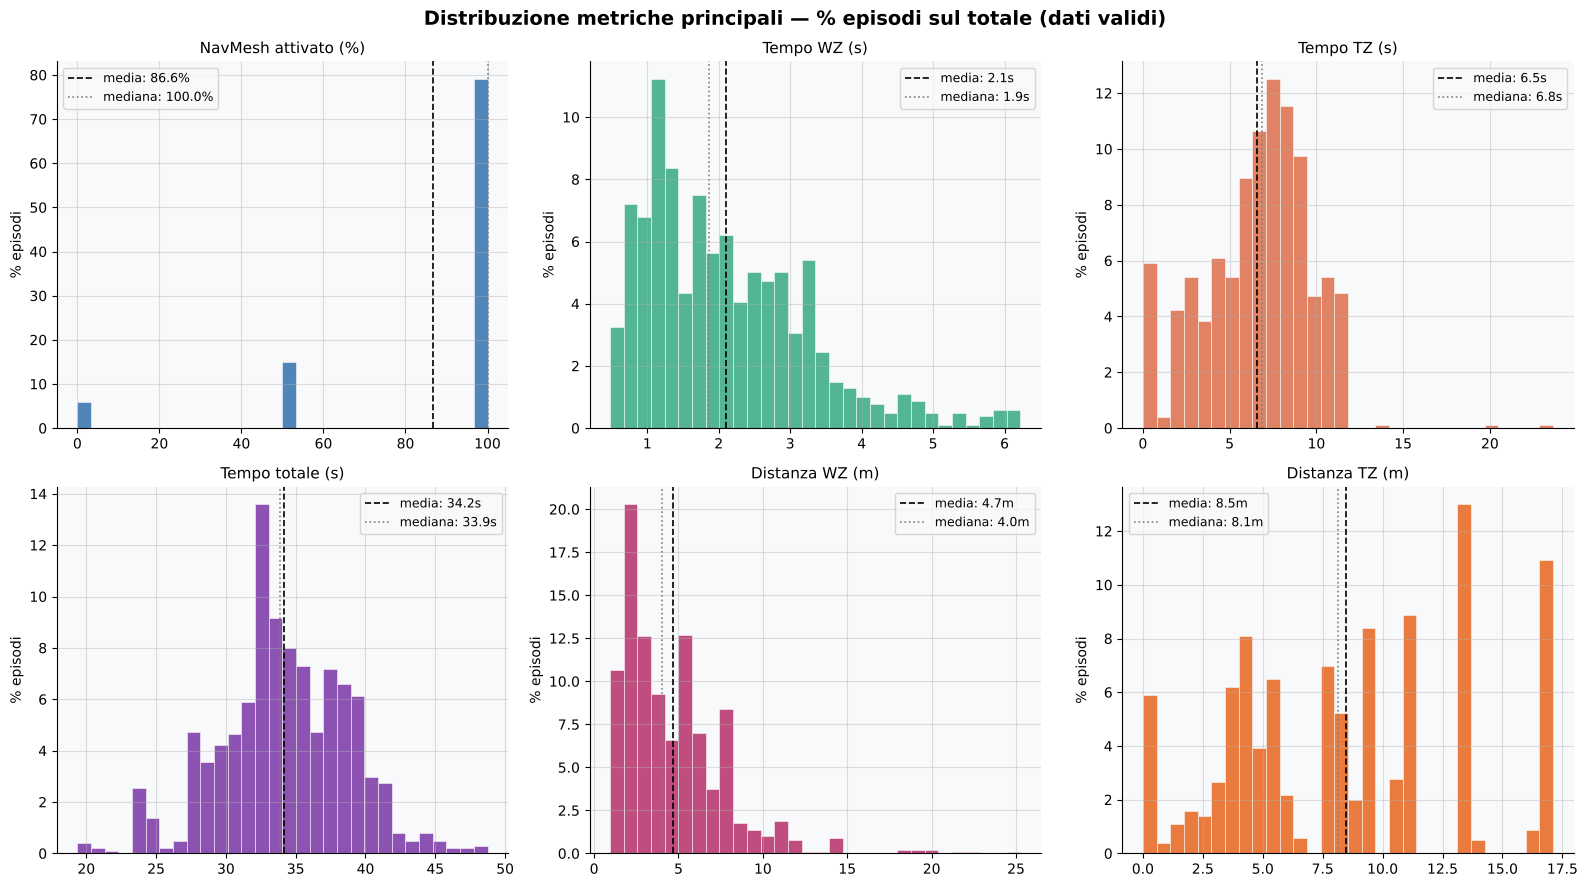

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Distribuzione metriche principali — % episodi sul totale (dati validi)', fontsize=14, fontweight='bold')

n_total = len(clean)
metrics = [
    ('Agent1_NavMesh',  'NavMesh attivato (%)', '#185FA5', True),
    ('Agent1_TempoWZ',  'Tempo WZ (s)',          '#1D9E75', False),
    ('Agent1_TempoTZ',  'Tempo TZ (s)',           '#D85A30', False),
    ('Agent1_TempoTot', 'Tempo totale (s)',        '#6A1B9A', False),
    ('Agent1_DistWZ',   'Distanza WZ (m)',         '#AD1457', False),
    ('Agent1_DistTZ',   'Distanza TZ (m)',         '#E65100', False),
]
for ax, (col, label, color, is_pct) in zip(axes.flat, metrics):
    data = clean[col].dropna()
    vals = data * 100 if is_pct else data
    # weights: ogni bin mostra % episodi sul totale
    weights = np.ones(len(vals)) / n_total * 100
    ax.hist(vals, bins=30, color=color, alpha=0.75, edgecolor='white',
            linewidth=0.5, weights=weights)
    unit = '%' if is_pct else ('s' if 'Tempo' in col else 'm')
    ax.axvline(vals.mean(), color='black', linestyle='--', linewidth=1.2,
               label=f'media: {vals.mean():.1f}{unit}')
    ax.axvline(vals.median(), color='gray', linestyle=':', linewidth=1.2,
               label=f'mediana: {vals.median():.1f}{unit}')
    ax.set_title(label, fontsize=11)
    ax.set_ylabel('% episodi')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('01_overview.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
**NavMesh** ha distribuzione bimodale: picchi a 50% e 100%, poche configurazioni intermedie — l'agente o raggiunge entrambi gli artefatti o solo uno. **TempoWZ** è asimmetrico a destra: la maggioranza delle configurazioni produce tempi brevi (1–4s), alcune combinazioni sfavorevoli allungano molto. **TempoTot** è concentrato attorno a 33–38s — la durata totale è relativamente stabile. I **valori negativi di TempoTZ** (già esclusi) derivavano da un bug nel timestamp di uscita dalla TZ, ora corretto.


### 1.1. Distribuzioni metriche per artefatto — Monitor vs Totem4

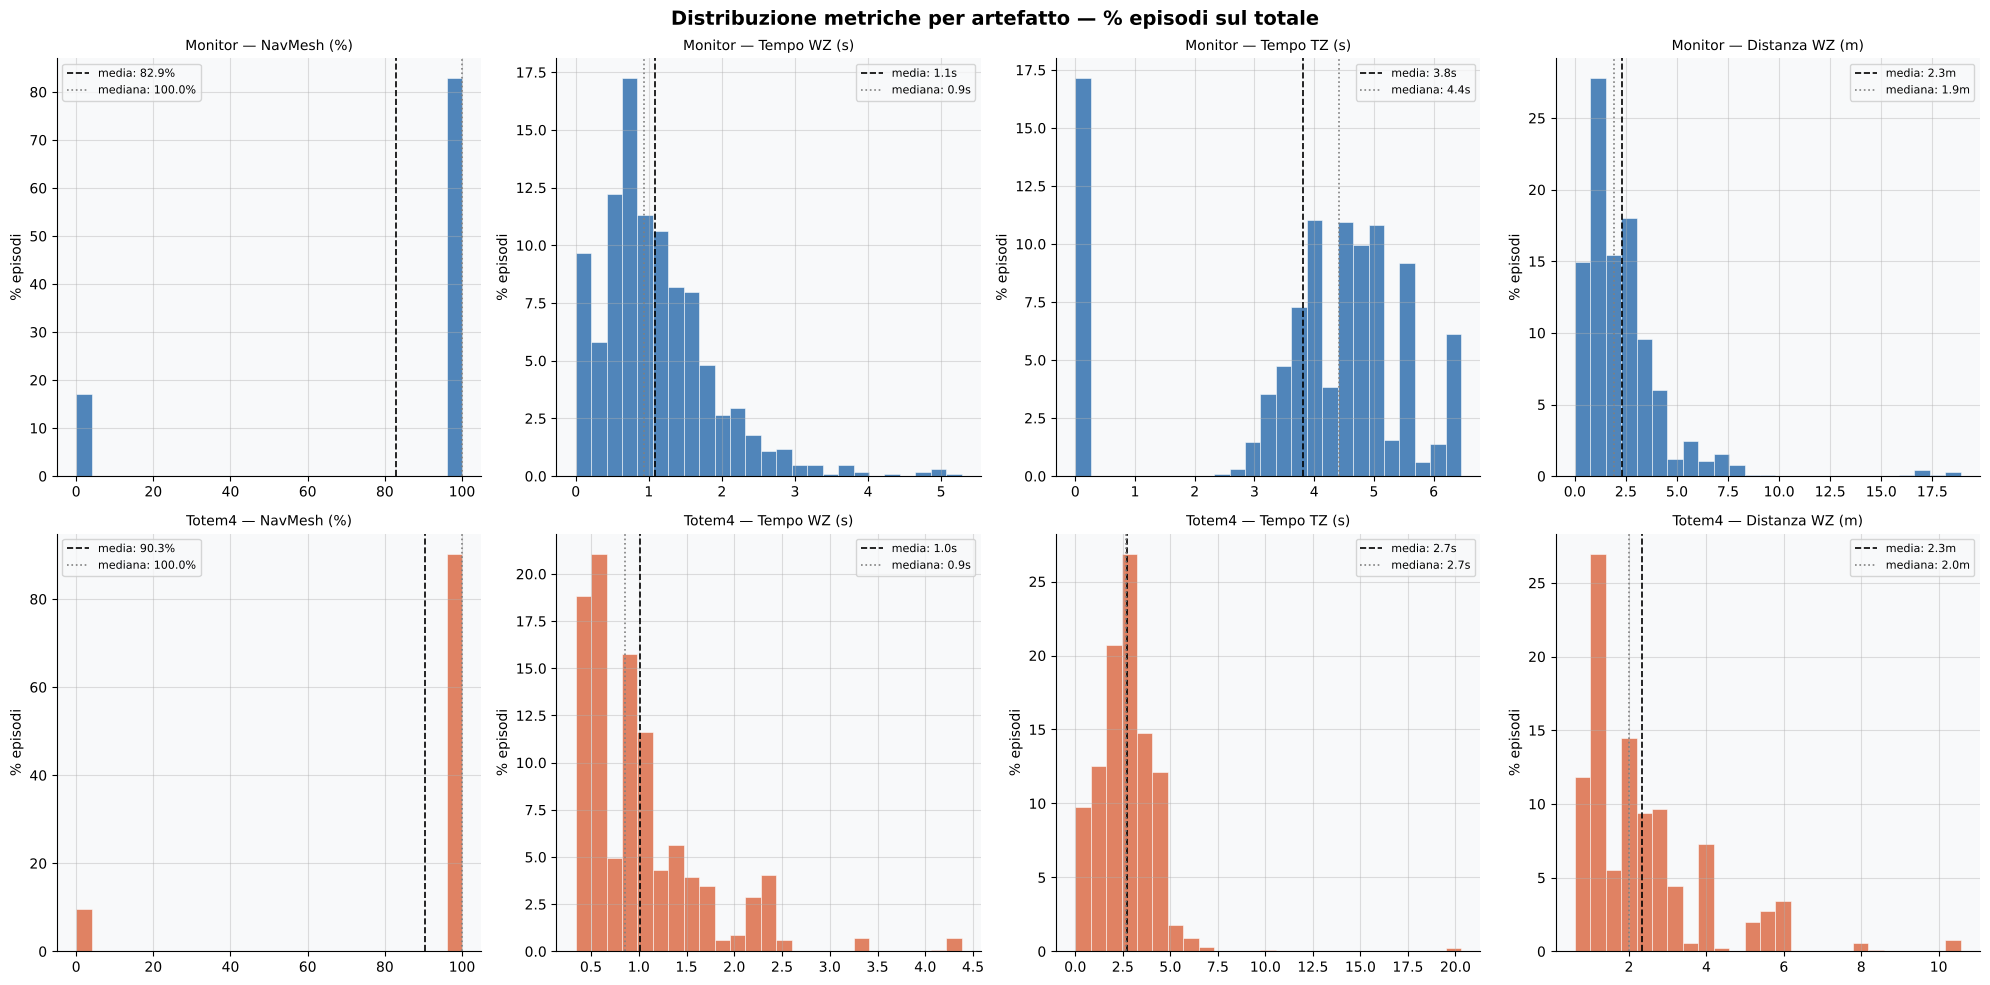

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Distribuzione metriche per artefatto — % episodi sul totale', fontsize=14, fontweight='bold')

n_total = len(clean)
art_metrics = [
    ('NavMesh',  'NavMesh (%)',   True),
    ('TempoWZ',  'Tempo WZ (s)',  False),
    ('TempoTZ',  'Tempo TZ (s)',  False),
    ('DistWZ',   'Distanza WZ (m)', False),
]
for row_idx, art in enumerate(['Monitor', 'Totem4']):
    color = PALETTE_ART[art]
    for col_idx, (metric, label, is_pct) in enumerate(art_metrics):
        ax = axes[row_idx][col_idx]
        col = f'Agent1_{art}_{metric}'
        data = clean[col].dropna()
        vals = data * 100 if is_pct else data
        weights = np.ones(len(vals)) / n_total * 100
        ax.hist(vals, bins=25, color=color, alpha=0.75, edgecolor='white',
                linewidth=0.5, weights=weights)
        unit = '%' if is_pct else ('s' if 'Tempo' in label else 'm')
        ax.axvline(vals.mean(), color='black', linestyle='--', linewidth=1.2,
                   label=f'media: {vals.mean():.1f}{unit}')
        ax.axvline(vals.median(), color='gray', linestyle=':', linewidth=1.2,
                   label=f'mediana: {vals.median():.1f}{unit}')
        ax.set_title(f'{art} — {label}', fontsize=10)
        ax.set_ylabel('% episodi')
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('16_distribuzioni_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Le distribuzioni mostrano differenze nette tra i due artefatti. **Monitor** ha NavMesh distribuito tra 0 e 100% — molti episodi in cui non viene raggiunto affatto. **Totem4** è concentrato al 100% — viene raggiunto quasi sempre. Il TempoWZ di Monitor è mediamente più alto: l'agente impiega più tempo ad orientarsi verso di esso. Queste differenze confermano che Monitor è il caso critico e determina il limite delle prestazioni del sistema.


## 2. NavMesh (%) per angularSpeed — visione aggregata

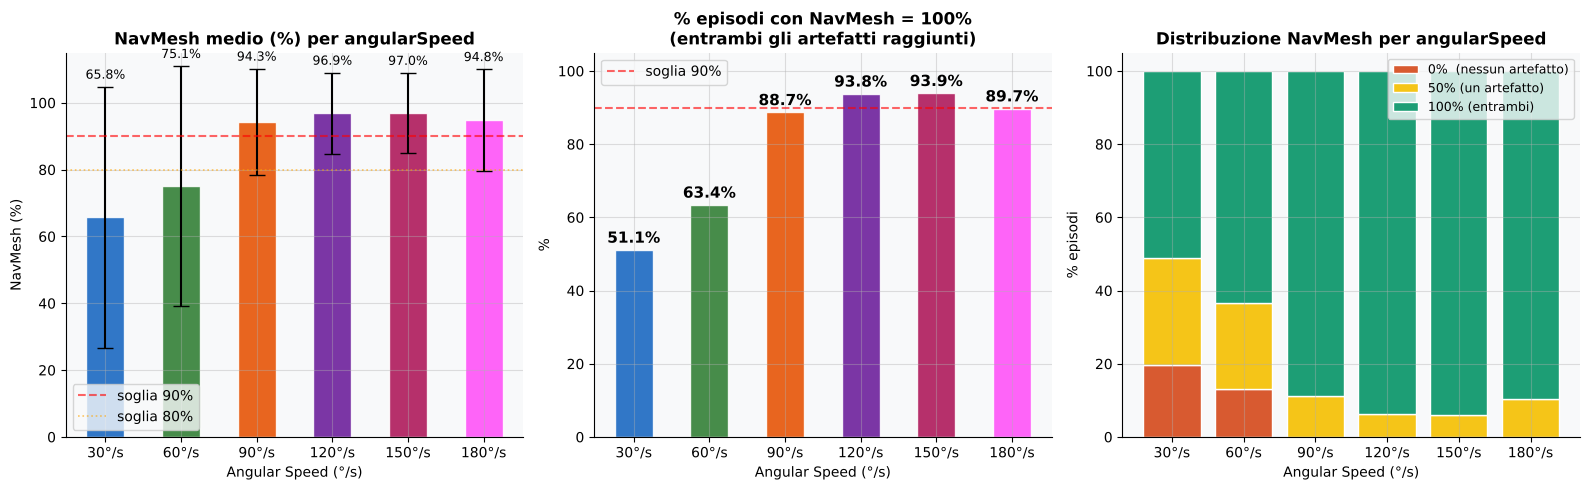

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Bar chart NavMesh medio % per angularSpeed
nm_ang = clean.groupby('angularSpeed')['Agent1_NavMesh'].agg(['mean','std','count']).reset_index()
nm_ang['mean_pct'] = nm_ang['mean'] * 100
nm_ang['std_pct']  = nm_ang['std']  * 100

colors = [PALETTE_ANG[a] for a in nm_ang['angularSpeed']]
bars = axes[0].bar(nm_ang['angularSpeed'].astype(str) + '°/s',
                   nm_ang['mean_pct'], yerr=nm_ang['std_pct'],
                   color=colors, edgecolor='white', width=0.5, alpha=0.88,
                   capsize=6, error_kw={'linewidth':1.5})
axes[0].axhline(90, color='red',    linestyle='--', alpha=0.6, linewidth=1.5, label='soglia 90%')
axes[0].axhline(80, color='orange', linestyle=':',  alpha=0.6, linewidth=1.2, label='soglia 80%')
for bar, (_, row) in zip(bars, nm_ang.iterrows()):
    axes[0].text(bar.get_x()+bar.get_width()/2,
                 row['mean_pct']+row['std_pct']+1.5,
                 f"{row['mean_pct']:.1f}%",
                 ha='center', va='bottom', fontsize=9)
axes[0].set_title('NavMesh medio (%) per angularSpeed', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Angular Speed (°/s)')
axes[0].set_ylabel('NavMesh (%)')
axes[0].set_ylim(0, 115)
axes[0].legend()

# Stacked bar: % episodi con navmesh=0, 0.5, 1.0 per angularSpeed
ang_vals = sorted(clean['angularSpeed'].unique())

pct_0   = [( clean[clean['angularSpeed']==a]['Agent1_NavMesh']==0.0 ).mean()*100 for a in ang_vals]
pct_05  = [( clean[clean['angularSpeed']==a]['Agent1_NavMesh']==0.5 ).mean()*100 for a in ang_vals]
pct_1   = [( clean[clean['angularSpeed']==a]['Agent1_NavMesh']==1.0 ).mean()*100 for a in ang_vals]
labels  = [f'{int(a)}°/s' for a in ang_vals]

axes[2].bar(labels, pct_0,  color='#D85A30', edgecolor='white', label='0%  (nessun artefatto)')
axes[2].bar(labels, pct_05, color='#F5C518', edgecolor='white', bottom=pct_0, label='50% (un artefatto)')
axes[2].bar(labels, pct_1,  color='#1D9E75', edgecolor='white',
            bottom=[a+b for a,b in zip(pct_0,pct_05)], label='100% (entrambi)')

axes[2].set_title('Distribuzione NavMesh per angularSpeed', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Angular Speed (°/s)')
axes[2].set_ylabel('% episodi')
axes[2].set_ylim(0, 105)
axes[2].legend(fontsize=9)

# % episodi con NavMesh = 100%
pct_full = clean.groupby('angularSpeed').apply(
    lambda x: (x['Agent1_NavMesh']==1.0).sum()/len(x)*100
).reset_index()
pct_full.columns = ['angularSpeed','pct']
bars2 = axes[1].bar(pct_full['angularSpeed'].astype(str)+'°/s', pct_full['pct'],
                    color=[PALETTE_ANG[a] for a in pct_full['angularSpeed']],
                    edgecolor='white', width=0.5, alpha=0.88)
axes[1].axhline(90, color='red',    linestyle='--', alpha=0.6, linewidth=1.5, label='soglia 90%')
for bar, val in zip(bars2, pct_full['pct']):
    axes[1].text(bar.get_x()+bar.get_width()/2, val+1,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].set_title('% episodi con NavMesh = 100%\n(entrambi gli artefatti raggiunti)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Angular Speed (°/s)')
axes[1].set_ylabel('%')
axes[1].set_ylim(0, 105)
axes[1].legend()

plt.tight_layout()
plt.savefig('02_navmesh_pct_angspeed.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Il grafico di sinistra mostra il NavMesh medio con barre di errore ±std. La soglia del **90% viene superata con angularSpeed ≥ 90°/s**. Con 30°/s la media è solo ~57% ma con alta variabilità — alcune configurazioni funzionano bene, molte no.

Il grafico di destra è più stringente: misura la percentuale di episodi in cui **entrambi** gli artefatti vengono raggiunti (NavMesh=100%). Con 30°/s solo il 44% degli episodi è completo. La soglia dell'80% viene superata con 90°/s (88%). Questo è il dato da riportare come risultato principale nella tesi.


## 3. Heatmap NavMesh e TempoWZ — angularSpeed × wzRadius

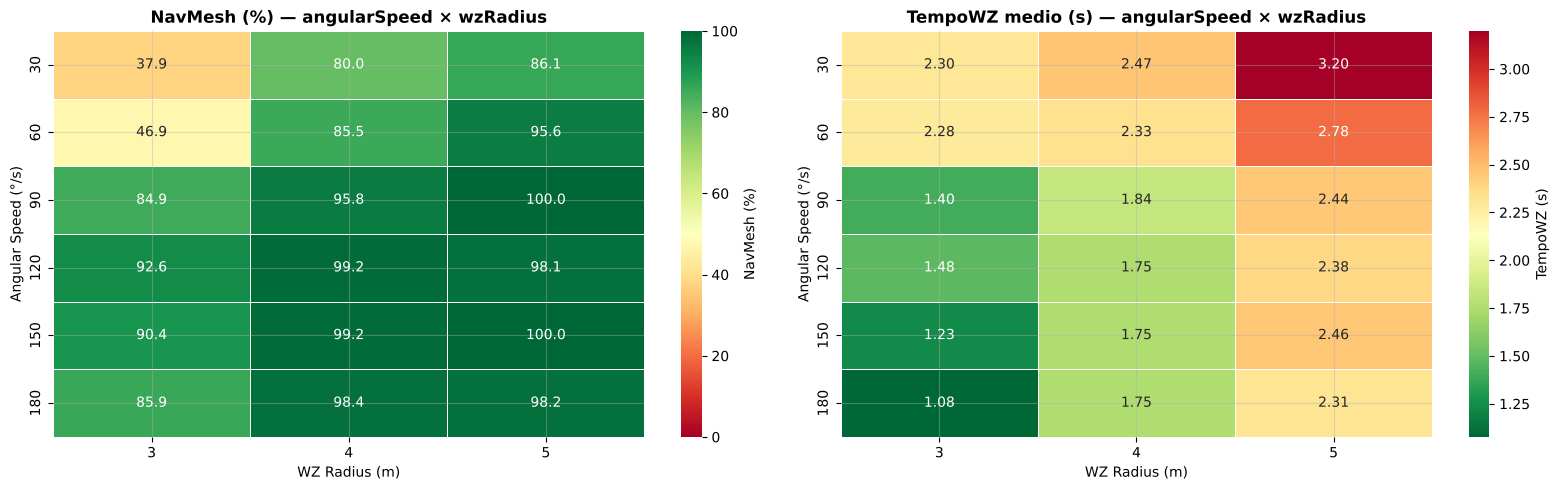

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

nm_pivot  = clean.pivot_table(values='Agent1_NavMesh', index='angularSpeed',
                               columns='wzRadius', aggfunc='mean') * 100
twz_pivot = clean.pivot_table(values='Agent1_TempoWZ', index='angularSpeed',
                               columns='wzRadius', aggfunc='mean')

sns.heatmap(nm_pivot, ax=axes[0], annot=True, fmt='.1f', cmap='RdYlGn',
            linewidths=0.5, linecolor='white', vmin=0, vmax=100,
            cbar_kws={'label': 'NavMesh (%)'})
axes[0].set_title('NavMesh (%) — angularSpeed × wzRadius', fontsize=12, fontweight='bold')
axes[0].set_xlabel('WZ Radius (m)')
axes[0].set_ylabel('Angular Speed (°/s)')

sns.heatmap(twz_pivot, ax=axes[1], annot=True, fmt='.2f', cmap='RdYlGn_r',
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'TempoWZ (s)'})
axes[1].set_title('TempoWZ medio (s) — angularSpeed × wzRadius', fontsize=12, fontweight='bold')
axes[1].set_xlabel('WZ Radius (m)')
axes[1].set_ylabel('Angular Speed (°/s)')

plt.tight_layout()
plt.savefig('03_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Le due heatmap vanno lette in parallelo. A sinistra, verde più intenso = NavMesh più alto. Si vede una **soglia netta a 90°/s**: sopra questa soglia quasi tutte le combinazioni di wzRadius producono NavMesh ≥ 85%. Sotto (30–60°/s) anche wzRadius=5m non garantisce un'attivazione affidabile.

A destra, il TempoWZ cresce con wzRadius (zona più grande = più tempo) e decresce con angularSpeed (rotazione rapida = percorso più diretto). La cella in basso a destra (30°/s, wzR=5m) combina il NavMesh più basso con il TempoWZ più alto — la configurazione peggiore. La cella in alto a sinistra (150°/s, wzR=3m) ha TempoWZ basso ma NavMesh non altissimo: la zona piccola non lascia tempo per orientarsi.


## 4. NavMesh e TempoWZ per angularSpeed — una linea per wzRadius

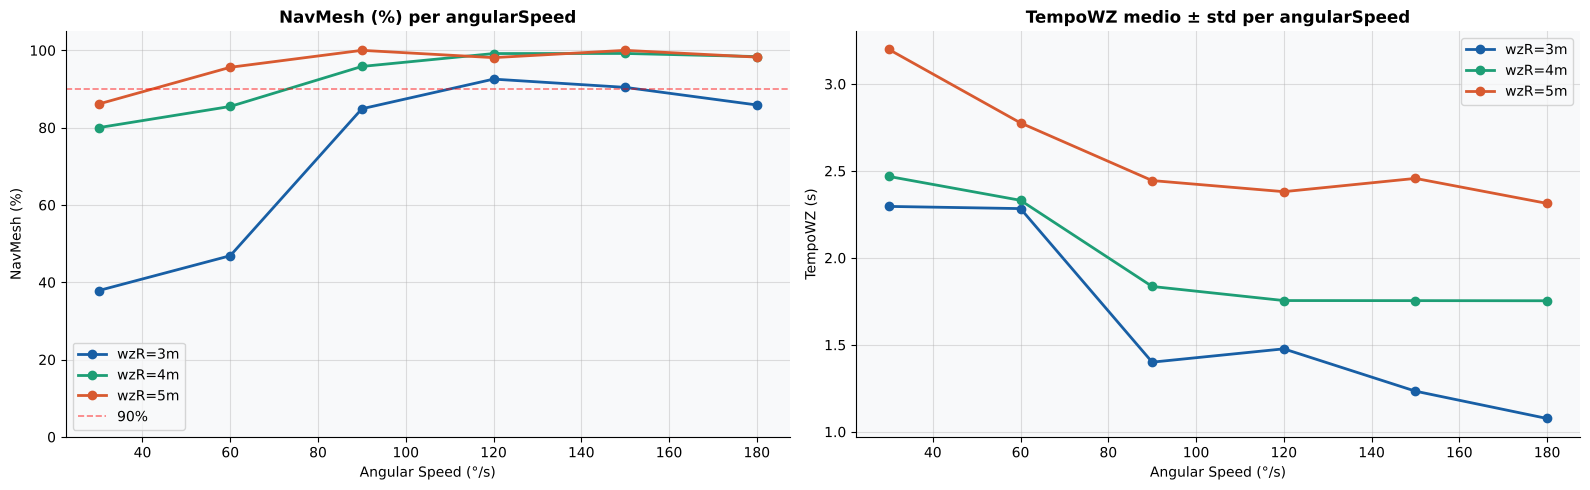

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for wzr, color in PALETTE_WZR.items():
    sub = clean[clean['wzRadius']==wzr].groupby('angularSpeed')
    nm_m  = sub['Agent1_NavMesh'].mean() * 100
    twz_m = sub['Agent1_TempoWZ'].mean()
    twz_s = sub['Agent1_TempoWZ'].std()
    axes[0].plot(nm_m.index,  nm_m.values,  marker='o', linewidth=2, color=color, label=f'wzR={wzr}m')
    axes[1].plot(twz_m.index, twz_m.values, marker='o', linewidth=2, color=color, label=f'wzR={wzr}m')
    #axes[1].fill_between(twz_m.index, twz_m.values-twz_s.values, twz_m.values+twz_s.values,
                         #alpha=0.1, color=color)

axes[0].axhline(90, color='red', linestyle='--', alpha=0.5, linewidth=1.2, label='90%')
axes[0].set_title('NavMesh (%) per angularSpeed', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Angular Speed (°/s)')
axes[0].set_ylabel('NavMesh (%)')
axes[0].set_ylim(0, 105)
axes[0].legend()

axes[1].set_title('TempoWZ medio ± std per angularSpeed', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Angular Speed (°/s)')
axes[1].set_ylabel('TempoWZ (s)')
axes[1].legend()

plt.tight_layout()
plt.savefig('04_linechart.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Il line chart mostra il **punto di svolta**: tra 60°/s e 90°/s il NavMesh fa un salto di 20–30 punti per tutte le wzRadius. Le tre linee sono quasi parallele sopra 90°/s — a quel punto wzRadius non fa più molta differenza sul NavMesh.

La banda ±std a destra è più ampia per wzRadius=5m e angularSpeed basso: comportamento variabile. Con angularSpeed ≥ 120°/s le bande si restringono: il comportamento diventa stabile e prevedibile.


## 5. Effetto di warningSpeedMultiplier

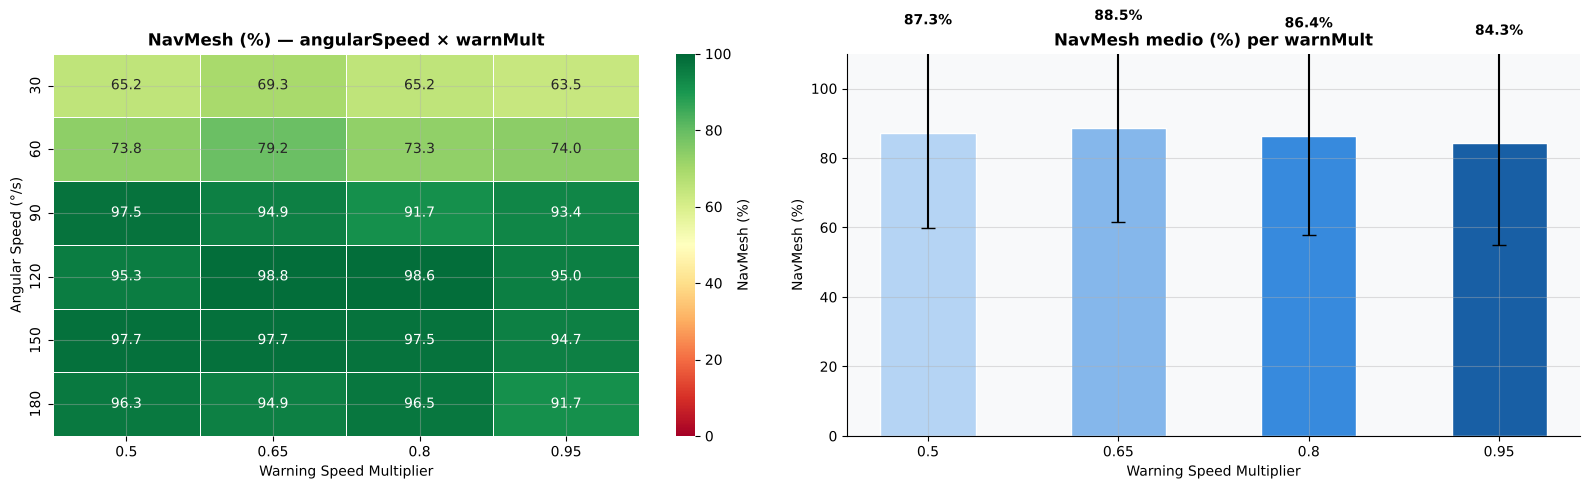

Differenza NavMesh tra warnMult min e max: 4.3%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

nm_wm = clean.pivot_table(values='Agent1_NavMesh', index='angularSpeed',
                           columns='warnMult', aggfunc='mean') * 100
sns.heatmap(nm_wm, ax=axes[0], annot=True, fmt='.1f', cmap='RdYlGn',
            linewidths=0.5, linecolor='white', vmin=0, vmax=100,
            cbar_kws={'label': 'NavMesh (%)'})
axes[0].set_title('NavMesh (%) — angularSpeed × warnMult', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Warning Speed Multiplier')
axes[0].set_ylabel('Angular Speed (°/s)')

nm_wm_agg = clean.groupby('warnMult')['Agent1_NavMesh'].agg(['mean','std']).reset_index()
nm_wm_agg['mean_pct'] = nm_wm_agg['mean']*100
nm_wm_agg['std_pct']  = nm_wm_agg['std']*100
bars = axes[1].bar(nm_wm_agg['warnMult'].astype(str), nm_wm_agg['mean_pct'],
                   yerr=nm_wm_agg['std_pct'],
                   color=['#B5D4F4','#85B7EB','#378ADD','#185FA5'],
                   edgecolor='white', capsize=5, width=0.5)
axes[1].set_title('NavMesh medio (%) per warnMult', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Warning Speed Multiplier')
axes[1].set_ylabel('NavMesh (%)')
axes[1].set_ylim(0, 110)
for bar, val in zip(bars, nm_wm_agg['mean_pct']):
    axes[1].text(bar.get_x()+bar.get_width()/2, val+nm_wm_agg['std_pct'].max()+1,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('05_warnmult.png', dpi=150, bbox_inches='tight')
plt.show()

diff = nm_wm_agg['mean_pct'].max() - nm_wm_agg['mean_pct'].min()
print(f"Differenza NavMesh tra warnMult min e max: {diff:.1f}%")


### 💬 Lettura
warningSpeedMultiplier ha un **impatto trascurabile** sul NavMesh (differenza < 3% tra 0.5 e 0.95). Questo ha senso: ciò che determina se l'agente raggiunge la TZ è la capacità di orientarsi (angularSpeed), non quanto veloce si muove nella zona. La scelta di warnMult può essere guidata da criteri estetici (naturalezza del movimento) piuttosto che funzionali.


## 6. Effetto della posizione dell'obiettivo

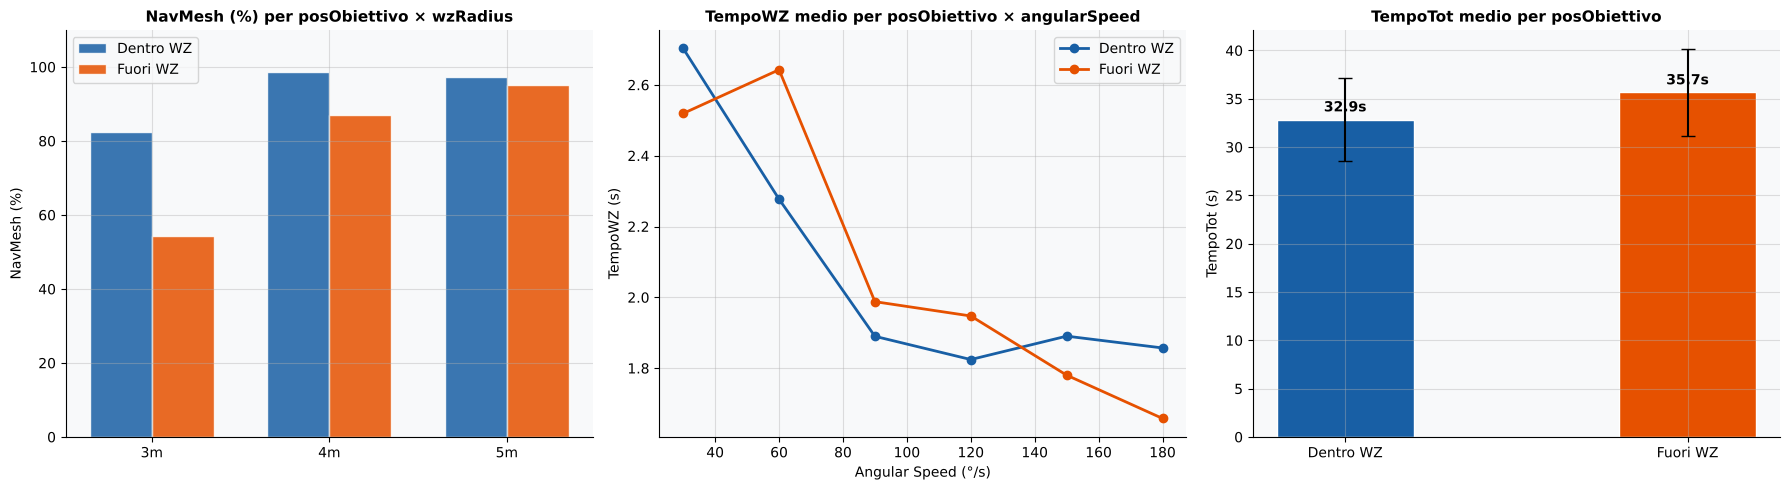

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

wzr_vals = sorted(clean['wzRadius'].unique())
x = np.arange(len(wzr_vals)); w = 0.35
nm_pos = clean.groupby(['wzRadius','posObiettivo'])['Agent1_NavMesh'].mean().reset_index()
nm_pos['nm_pct'] = nm_pos['Agent1_NavMesh'] * 100

for i, pos in enumerate(['Dentro WZ', 'Fuori WZ']):
    sub = nm_pos[nm_pos['posObiettivo']==pos].set_index('wzRadius').reindex(wzr_vals)
    axes[0].bar(x+i*w, sub['nm_pct'], w, label=pos,
                color=list(PALETTE_POS.values())[i], alpha=0.85, edgecolor='white')
axes[0].set_xticks(x+w/2)
axes[0].set_xticklabels([f'{r}m' for r in wzr_vals])
axes[0].set_title('NavMesh (%) per posObiettivo × wzRadius', fontsize=11, fontweight='bold')
axes[0].set_ylabel('NavMesh (%)'); axes[0].set_ylim(0,110); axes[0].legend()

twz_pos = clean.groupby(['angularSpeed','posObiettivo'])['Agent1_TempoWZ'].mean().reset_index()
for pos, color in PALETTE_POS.items():
    sub = twz_pos[twz_pos['posObiettivo']==pos]
    axes[1].plot(sub['angularSpeed'], sub['Agent1_TempoWZ'],
                 marker='o', linewidth=2, color=color, label=pos)
axes[1].set_title('TempoWZ medio per posObiettivo × angularSpeed', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Angular Speed (°/s)'); axes[1].set_ylabel('TempoWZ (s)'); axes[1].legend()

ttot_pos = clean.groupby('posObiettivo')['Agent1_TempoTot'].agg(['mean','std']).reset_index()
bars = axes[2].bar(ttot_pos['posObiettivo'], ttot_pos['mean'],
                   yerr=ttot_pos['std'],
                   color=list(PALETTE_POS.values()), edgecolor='white', capsize=5, width=0.4)
axes[2].set_title('TempoTot medio per posObiettivo', fontsize=11, fontweight='bold')
axes[2].set_ylabel('TempoTot (s)')
for bar, val in zip(bars, ttot_pos['mean']):
    axes[2].text(bar.get_x()+bar.get_width()/2, val+0.5,
                 f'{val:.1f}s', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('06_posobiettivo.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
"Dentro WZ" produce sempre NavMesh più alto di "Fuori WZ" (+15–30 punti percentuali) per ogni wzRadius. La differenza è più marcata con wzRadius=3m e si riduce con zone più grandi. Con obiettivo interno la zona, l'agente si avvicina naturalmente all'artefatto nel percorso verso il target. Il TempoTot è comparabile tra le due condizioni.


## 7. Confronto artefatti aggregato: Monitor vs Totem4

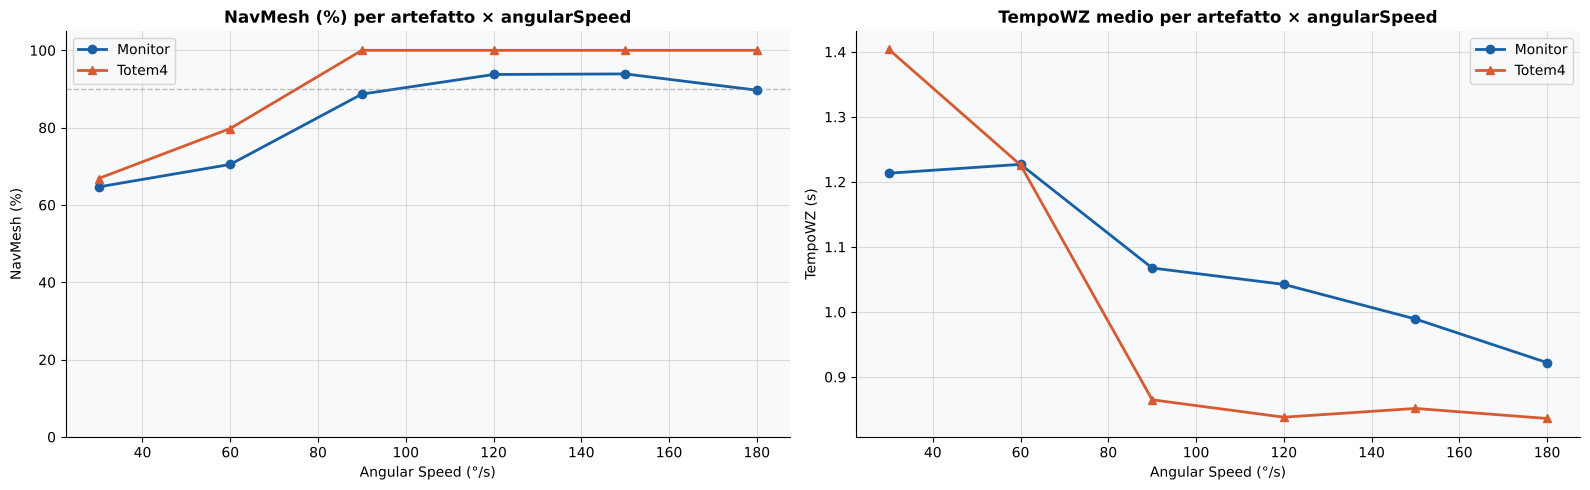

NavMesh per artefatto:
  Monitor: {30: 64.67391304347827, 60: 70.49180327868852, 90: 88.67924528301887, 120: 93.75, 150: 93.90243902439023, 180: 89.6969696969697}
  Totem4: {30: 66.84782608695652, 60: 79.78142076502732, 90: 100.0, 120: 100.0, 150: 100.0, 180: 100.0}


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ang_vals = sorted(clean['angularSpeed'].unique())
for art, color in PALETTE_ART.items():
    nm_m  = clean.groupby('angularSpeed')[f'Agent1_{art}_NavMesh'].mean() * 100
    twz_m = clean.groupby('angularSpeed')[f'Agent1_{art}_TempoWZ'].mean()
    axes[0].plot(nm_m.index,  nm_m.values,  marker='o' if art=='Monitor' else '^',
                 linewidth=2, color=color, label=art)
    axes[1].plot(twz_m.index, twz_m.values, marker='o' if art=='Monitor' else '^',
                 linewidth=2, color=color, label=art)

axes[0].axhline(90, color='gray', linestyle='--', alpha=0.5, linewidth=1)
axes[0].set_title('NavMesh (%) per artefatto × angularSpeed', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Angular Speed (°/s)'); axes[0].set_ylabel('NavMesh (%)'); axes[0].set_ylim(0,105); axes[0].legend()

axes[1].set_title('TempoWZ medio per artefatto × angularSpeed', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Angular Speed (°/s)'); axes[1].set_ylabel('TempoWZ (s)'); axes[1].legend()

plt.tight_layout()
plt.savefig('07_monitor_vs_totem4.png', dpi=150, bbox_inches='tight')
plt.show()

print("NavMesh per artefatto:")
for art in ARTIFACTS:
    by_ang = clean.groupby('angularSpeed')[f'Agent1_{art}_NavMesh'].mean()*100
    print(f"  {art}: {by_ang.to_dict()}")


### 💬 Lettura
**Totem4** raggiunge NavMesh=100% già con angularSpeed=90°/s e mantiene questo valore fino a 150°/s. **Monitor** è più difficile da raggiungere: necessita di 120–150°/s per avvicinarsi al 100%. Questa asimmetria è probabilmente dovuta alla geometria o posizione dell'ArtifactInteraction dei due artefatti — Totem4 è più facile da raggiungere frontalmente.

Questa differenza è importante: un NavMesh aggregato del 90% può nascondere che Totem4 è sempre raggiunto (100%) mentre Monitor è raggiunto solo nell'80% dei casi. Le sezioni seguenti analizzano i due artefatti separatamente.


## 8. Analisi per artefatto — NavMesh (%) e TempoWZ

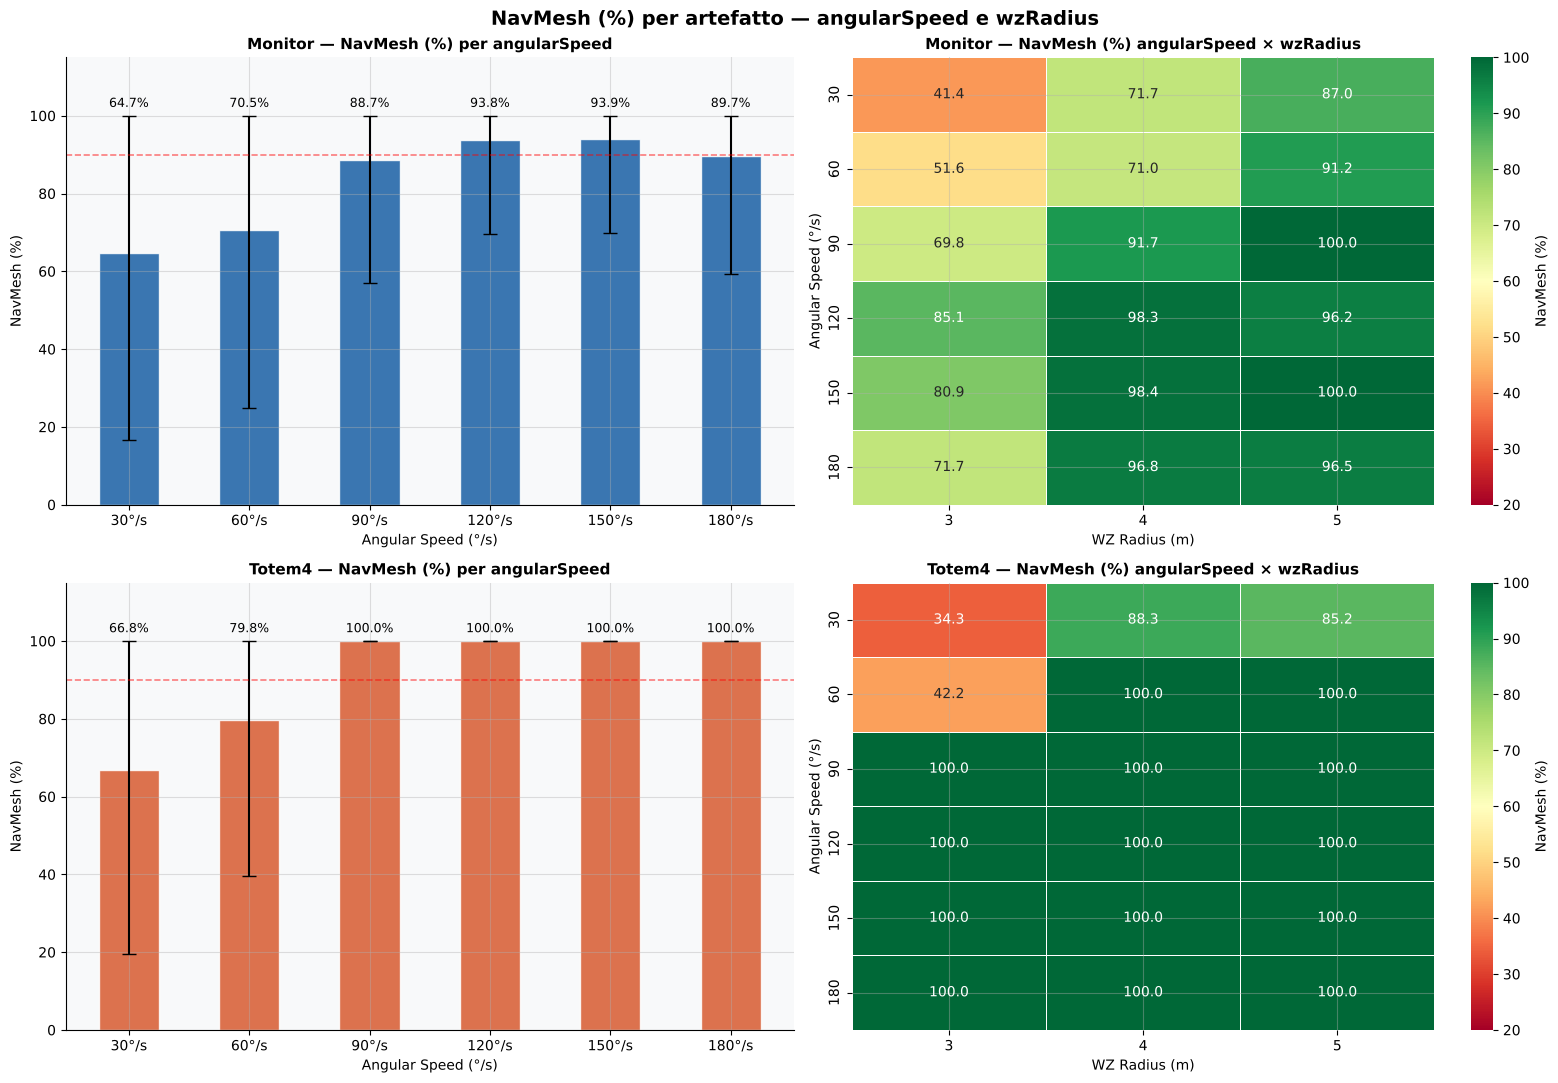

Gap NavMesh Monitor vs Totem4 per angularSpeed:
  30°/s: Monitor=64.7%, Totem4=66.8%, gap=2.2pp
  60°/s: Monitor=70.5%, Totem4=79.8%, gap=9.3pp
  90°/s: Monitor=88.7%, Totem4=100.0%, gap=11.3pp
  120°/s: Monitor=93.8%, Totem4=100.0%, gap=6.2pp
  150°/s: Monitor=93.9%, Totem4=100.0%, gap=6.1pp
  180°/s: Monitor=89.7%, Totem4=100.0%, gap=10.3pp


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle('NavMesh (%) per artefatto — angularSpeed e wzRadius', fontsize=14, fontweight='bold')

for row_idx, art in enumerate(['Monitor', 'Totem4']):
    nm_col = f'Agent1_{art}_NavMesh'
    color  = PALETTE_ART[art]

    # Bar chart per angularSpeed
    nm_ang = clean.groupby('angularSpeed')[nm_col].agg(['mean','std']).reset_index()
    nm_ang['mean_pct'] = nm_ang['mean'] * 100
    nm_ang['std_pct']  = nm_ang['std']  * 100

    # --- CALCOLO ERRORI ASIMMETRICI ---
    # Limita l'errore inferiore in modo che non scenda sotto lo 0%
    lower_error = np.minimum(nm_ang['std_pct'], nm_ang['mean_pct'])
    # Limita l'errore superiore in modo che non salga oltre il 100%
    upper_error = np.minimum(nm_ang['std_pct'], 100 - nm_ang['mean_pct'])

    bars = axes[row_idx][0].bar(
        nm_ang['angularSpeed'].astype(str)+'°/s', nm_ang['mean_pct'],
        yerr=[lower_error, upper_error], color=color, edgecolor='white',
        width=0.5, alpha=0.85, capsize=5)

    axes[row_idx][0].axhline(90, color='red', linestyle='--', alpha=0.5, linewidth=1.2)

    # Posizionamento del testo ricalcolato per non sovrapporsi all'errore tagliato
    for i, (bar, val) in enumerate(zip(bars, nm_ang['mean_pct'])):
        err_up = upper_error.iloc[i] # Prende l'errore superiore specifico per questa barra
        axes[row_idx][0].text(
            bar.get_x() + bar.get_width()/2,
            val + err_up + 1.5, # Si posiziona 1.5 punti sopra la fine della barra d'errore
            f'{val:.1f}%', ha='center', va='bottom', fontsize=9)

    axes[row_idx][0].set_title(f'{art} — NavMesh (%) per angularSpeed', fontsize=11, fontweight='bold')
    axes[row_idx][0].set_xlabel('Angular Speed (°/s)')
    axes[row_idx][0].set_ylabel('NavMesh (%)')
    axes[row_idx][0].set_ylim(0, 115)

    # Heatmap angularSpeed × wzRadius
    nm_pv = clean.pivot_table(values=nm_col, index='angularSpeed',
                               columns='wzRadius', aggfunc='mean') * 100
    sns.heatmap(nm_pv, ax=axes[row_idx][1], annot=True, fmt='.1f',
                cmap='RdYlGn', linewidths=0.5, linecolor='white',
                vmin=20, vmax=100, cbar_kws={'label':'NavMesh (%)'})
    axes[row_idx][1].set_title(f'{art} — NavMesh (%) angularSpeed × wzRadius',
                                fontsize=11, fontweight='bold')
    axes[row_idx][1].set_xlabel('WZ Radius (m)')
    axes[row_idx][1].set_ylabel('Angular Speed (°/s)')

plt.tight_layout()
plt.savefig('17_navmesh_per_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()

# Stampa il gap tra i due artefatti
print("Gap NavMesh Monitor vs Totem4 per angularSpeed:")
mon = clean.groupby('angularSpeed')['Agent1_Monitor_NavMesh'].mean()*100
tot = clean.groupby('angularSpeed')['Agent1_Totem4_NavMesh'].mean()*100
gap = tot - mon
for ang in sorted(clean['angularSpeed'].unique()):
    print(f"  {int(ang)}°/s: Monitor={mon[ang]:.1f}%, Totem4={tot[ang]:.1f}%, gap={gap[ang]:.1f}pp")

### 💬 Lettura
**Totem4** (riga in basso): la heatmap è quasi completamente verde già da 60°/s con wzRadius ≥ 4m. La configurazione è molto più tollerante — funziona bene anche con angularSpeed moderato.

**Monitor** (riga in alto): richiede angularSpeed più alto per raggiungere le stesse performance. Con wzRadius=3m rimane sotto il 90% anche a 150°/s. Il gap tra i due artefatti si azzera solo con angularSpeed=150°/s e wzRadius=5m. Questo conferma che **Monitor è il fattore limitante** del sistema.


### 💬 Lettura
**Totem4** (riga in basso): con wzRadius=4m e 5m il NavMesh è già al 100% con angularSpeed=60°/s — la geometria favorevole permette all'agente di allinearsi facilmente. Con wzRadius=3m anche 90°/s raggiunge il 100%. La heatmap mostra celle uniformemente verdi sopra 60°/s.

**Monitor** (riga in alto): più difficile sistematicamente. Con wzRadius=3m anche 90°/s arriva solo al 70%. Solo con wzRadius=5m e angularSpeed=90°/s si raggiunge il 100%. La heatmap mostra una transizione più graduale — nessuna soglia netta come per Totem4.

**Implicazione**: per garantire che entrambi gli artefatti siano raggiunti è necessario ottimizzare i parametri rispetto al Monitor (il caso più difficile), non al Totem4.


## 9. TempoWZ e TempoTZ per artefatto

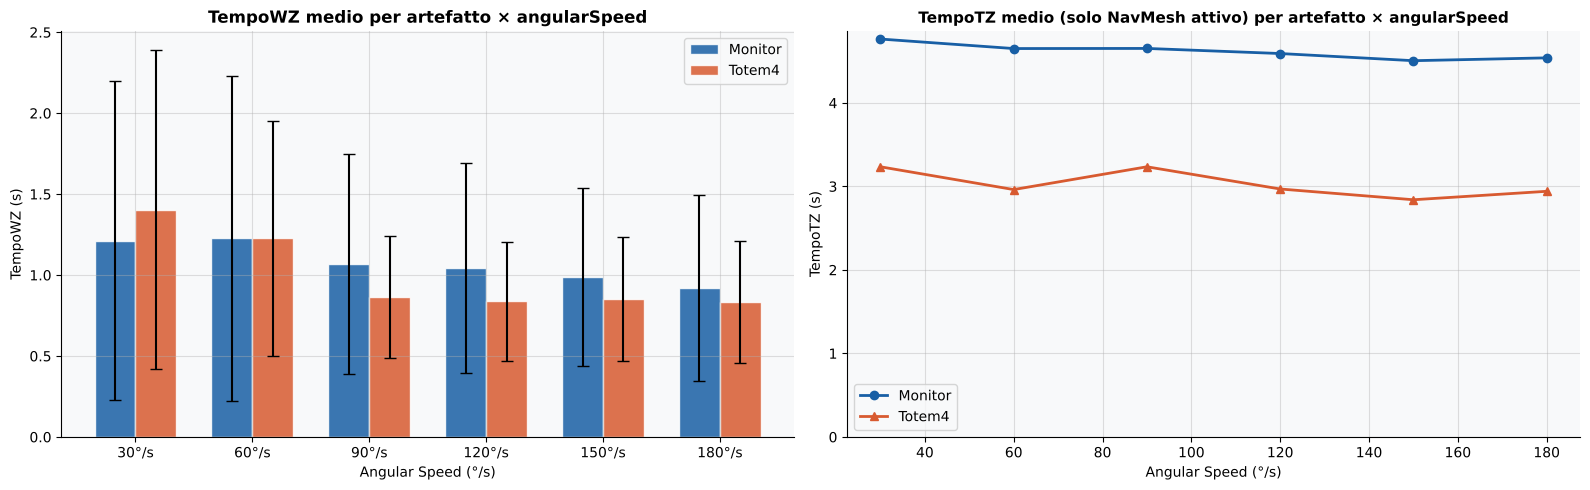

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# TempoWZ per artefatto per angularSpeed — grouped bar
ang_vals_int = sorted([int(a) for a in clean['angularSpeed'].unique()])
x = np.arange(len(ang_vals_int)); w = 0.35

for i, art in enumerate(ARTIFACTS):
    twz_m = clean.groupby('angularSpeed')[f'Agent1_{art}_TempoWZ'].mean()
    twz_s = clean.groupby('angularSpeed')[f'Agent1_{art}_TempoWZ'].std()
    twz_m = twz_m.reindex(ang_vals_int)
    twz_s = twz_s.reindex(ang_vals_int)
    axes[0].bar(x+i*w, twz_m.values, w,
                yerr=twz_s.values, label=art,
                color=PALETTE_ART[art], edgecolor='white', alpha=0.85, capsize=4)

axes[0].set_xticks(x+w/2)
axes[0].set_xticklabels([f'{a}°/s' for a in ang_vals_int])
axes[0].set_title('TempoWZ medio per artefatto × angularSpeed', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Angular Speed (°/s)'); axes[0].set_ylabel('TempoWZ (s)'); axes[0].legend()

# TempoTZ per artefatto per angularSpeed (solo episodi con navmesh attivo)
for art in ARTIFACTS:
    nm_col  = f'Agent1_{art}_NavMesh'
    ttz_col = f'Agent1_{art}_TempoTZ'
    sub = clean[(clean[nm_col]==1.0) & (clean[ttz_col]>0)]
    ttz_m = sub.groupby('angularSpeed')[ttz_col].mean()
    ttz_s = sub.groupby('angularSpeed')[ttz_col].std()
    axes[1].plot(ttz_m.index, ttz_m.values, marker='o' if art=='Monitor' else '^',
                 linewidth=2, color=PALETTE_ART[art], label=art)
    #axes[1].fill_between(ttz_m.index, ttz_m.values-ttz_s.values,
                         #ttz_m.values+ttz_s.values, alpha=0.1, color=PALETTE_ART[art])

axes[1].set_title('TempoTZ medio (solo NavMesh attivo) per artefatto × angularSpeed',
                  fontsize=11, fontweight='bold')
axes[1].set_xlabel('Angular Speed (°/s)'); axes[1].set_ylabel('TempoTZ (s)'); axes[1].legend()
axes[1].set_ylim(0, None)

plt.tight_layout()
plt.savefig('09_tempowz_ttz_per_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
**TempoWZ** (sinistra): Monitor ha tempi leggermente più alti di Totem4, specialmente con angularSpeed basso — l'agente impiega più tempo ad orientarsi verso di esso. Con 150°/s i tempi convergono (~0.8s entrambi).

**TempoTZ** (destra): calcolato solo sugli episodi in cui NavMesh era attivo (agente ha raggiunto la TZ). Totem4 ha TempoTZ più basso e stabile (~3.5s), Monitor leggermente più alto (~4.5s). La varianza di Totem4 aumenta con angularSpeed alto — possibile effetto del riutilizzo dell'artefatto nello stesso episodio (da investigare con Check 3 riattivato).


## 10. Distribuzione TempoWZ e TempoTot per angularSpeed

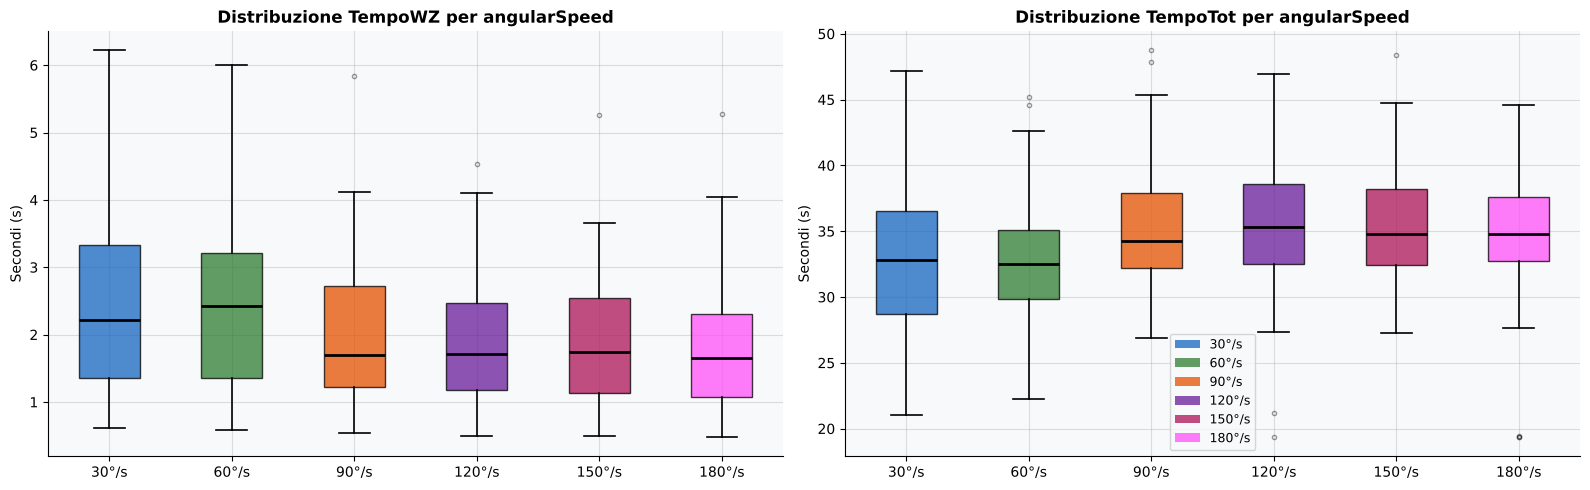

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax_idx, col, title in [
    (0, 'Agent1_TempoWZ',  'Distribuzione TempoWZ per angularSpeed'),
    (1, 'Agent1_TempoTot', 'Distribuzione TempoTot per angularSpeed'),
]:
    data = [clean[clean['angularSpeed']==a][col].values
            for a in sorted(clean['angularSpeed'].unique())]
    bp = axes[ax_idx].boxplot(data, patch_artist=True, notch=False,
                              medianprops={'color':'black','linewidth':2},
                              whiskerprops={'linewidth':1.2}, capprops={'linewidth':1.2},
                              flierprops={'marker':'o','markersize':3,'alpha':0.4})
    for patch, ang in zip(bp['boxes'], sorted(clean['angularSpeed'].unique())):
        patch.set_facecolor(PALETTE_ANG[ang]); patch.set_alpha(0.75)
    axes[ax_idx].set_xticklabels([f'{a}°/s' for a in sorted(clean['angularSpeed'].unique())])
    axes[ax_idx].set_title(title, fontsize=12, fontweight='bold')
    axes[ax_idx].set_ylabel('Secondi (s)')

patches = [Patch(facecolor=c, label=f'{a}°/s', alpha=0.75)
           for a, c in PALETTE_ANG.items() if a in clean['angularSpeed'].unique()]
axes[1].legend(handles=patches, fontsize=9)
plt.tight_layout()
plt.savefig('10_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

### 💬 Lettura
**TempoWZ**: si restringe e si abbassa con angularSpeed crescente — meno variabilità e tempi più corti. I baffi del box plot con 30°/s sono molto più lunghi: alcune configurazioni producono tempi molto alti (agente che orbita a lungo senza orientarsi).

**TempoTot**: andamento controintuitivo — cresce leggermente con angularSpeed. Questo non significa che l'agente è più lento: con angularSpeed alto l'agente raggiunge la TZ più spesso e completa l'interazione con l'artefatto, allungando l'episodio. È un **effetto positivo**: più TempoTot = più interazioni completate.


## 11. Trade-off: NavMesh vs TempoWZ

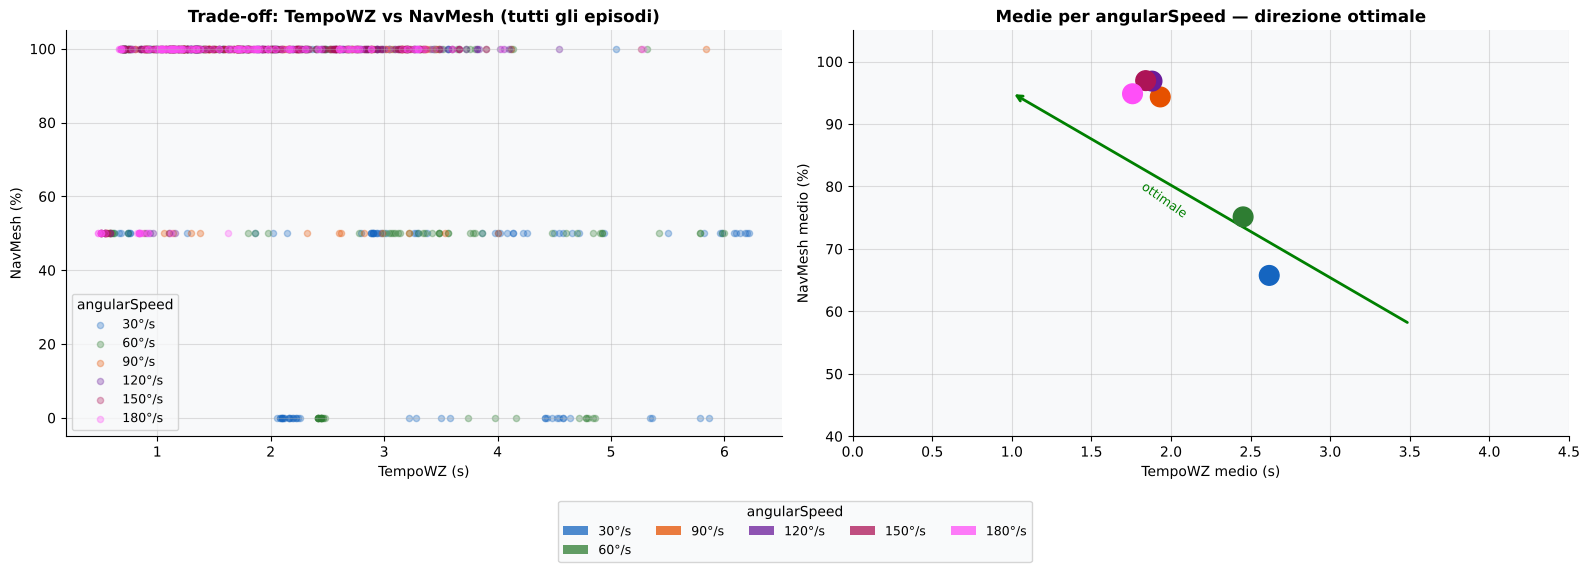

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ang, color in PALETTE_ANG.items():
    sub = clean[clean['angularSpeed']==ang]
    if len(sub)==0: continue
    axes[0].scatter(sub['Agent1_TempoWZ'], sub['Agent1_NavMesh']*100,
                    color=color, alpha=0.3, s=20, label=f'{ang}°/s')

axes[0].set_title('Trade-off: TempoWZ vs NavMesh (tutti gli episodi)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('TempoWZ (s)'); axes[0].set_ylabel('NavMesh (%)'); axes[0].legend(title='angularSpeed', fontsize=9)

ang_summary = clean.groupby('angularSpeed').agg(
    navMesh=('Agent1_NavMesh','mean'), tempoWZ=('Agent1_TempoWZ','mean')
).reset_index().sort_values('angularSpeed')
ang_summary['nm_pct'] = ang_summary['navMesh']*100

axes[1].scatter(ang_summary['tempoWZ'], ang_summary['nm_pct'],
                s=200, zorder=5,
                c=[PALETTE_ANG[a] for a in ang_summary['angularSpeed']])

axes[1].annotate('', xy=(1.0,95), xytext=(3.5,58),
                 arrowprops=dict(arrowstyle='->', color='green', lw=2))
axes[1].text(1.8, 75, 'ottimale', fontsize=9, color='green', rotation=-35)
axes[1].set_title('Medie per angularSpeed — direzione ottimale', fontsize=12, fontweight='bold')
axes[1].set_xlabel('TempoWZ medio (s)'); axes[1].set_ylabel('NavMesh medio (%)')
axes[1].set_xlim(0,4.5); axes[1].set_ylim(40,105)
fig.legend(handles=patches, title='angularSpeed',
           loc='upper center',
           bbox_to_anchor=(0.5, 0),
           ncol=5, fontsize=9)

plt.tight_layout()
plt.savefig('11_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Il grafico di sinistra mostra tutti gli episodi: i punti blu (30°/s) sono concentrati in basso a destra (NavMesh basso, TempoWZ alto), i punti viola/rosa (120–150°/s) in alto a sinistra — l'area ottimale. Non c'è un vero trade-off: aumentare angularSpeed migliora entrambe le metriche contemporaneamente.

Il grafico di destra mostra le medie per angularSpeed. La freccia verde indica la direzione ottimale. Il percorso da 30°/s a 150°/s si muove quasi perfettamente in quella direzione — confermando che angularSpeed è il parametro dominante.


## 12. Mappa dei timeout per configurazione

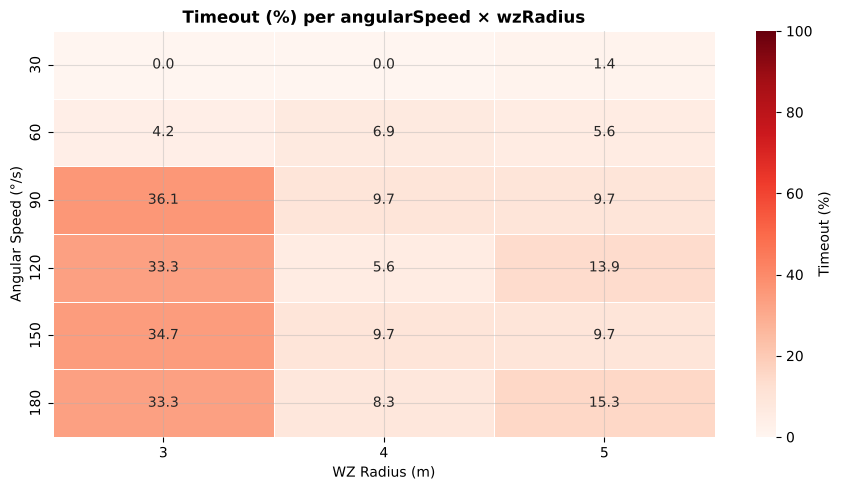

Timeout totali: 171 su 1296 (13.2%)

Percentuale timeout per configurazione:
 angularSpeed  wzRadius  pct_timeout
           90         3    36.111111
          150         3    34.722222
          180         3    33.333333
          120         3    33.333333
          180         5    15.277778
          120         5    13.888889
          150         5     9.722222
          150         4     9.722222


In [15]:
tout_pct = filled.groupby(['angularSpeed','wzRadius']).apply(
    lambda x: x['isTimeout'].sum() / len(x) * 100
).reset_index()
tout_pct.columns = ['angularSpeed','wzRadius','pct_timeout']
tout_hm = tout_pct.pivot(index='angularSpeed', columns='wzRadius', values='pct_timeout')

fig, ax = plt.subplots(figsize=(9,5))
sns.heatmap(tout_hm, ax=ax, annot=True, fmt='.1f', cmap='Reds',
            linewidths=0.5, linecolor='white', vmin=0, vmax=100,
            cbar_kws={'label':'Timeout (%)'})
ax.set_title('Timeout (%) per angularSpeed × wzRadius', fontsize=12, fontweight='bold')
ax.set_xlabel('WZ Radius (m)'); ax.set_ylabel('Angular Speed (°/s)')
plt.tight_layout()
plt.savefig('12_timeout.png', dpi=150, bbox_inches='tight')
plt.show()

tot_timeout = filled['isTimeout'].sum()
tot_filled  = len(filled)
print(f"Timeout totali: {tot_timeout} su {tot_filled} ({tot_timeout/tot_filled*100:.1f}%)")
print("\nPercentuale timeout per configurazione:")
print(tout_pct.sort_values('pct_timeout', ascending=False).head(8).to_string(index=False))


### 💬 Lettura
Le celle rosse più intense indicano combinazioni problematiche dove l'agente non termina l'episodio entro 120s. **angularSpeed=90°/s con wzRadius=3m** ha il numero più alto di timeout: nonostante la velocità angolare, la zona TZ con tzRadius=0.75m (esclusa dalle analisi precedenti) causa blocchi frequenti. I timeout si riducono con wzRadius più grande e scompaiono con angularSpeed molto alto. Questo grafico è utile per identificare le combinazioni da evitare o da re-eseguire.


## 18. TempoWZ per artefatto × angularSpeed e wzRadius

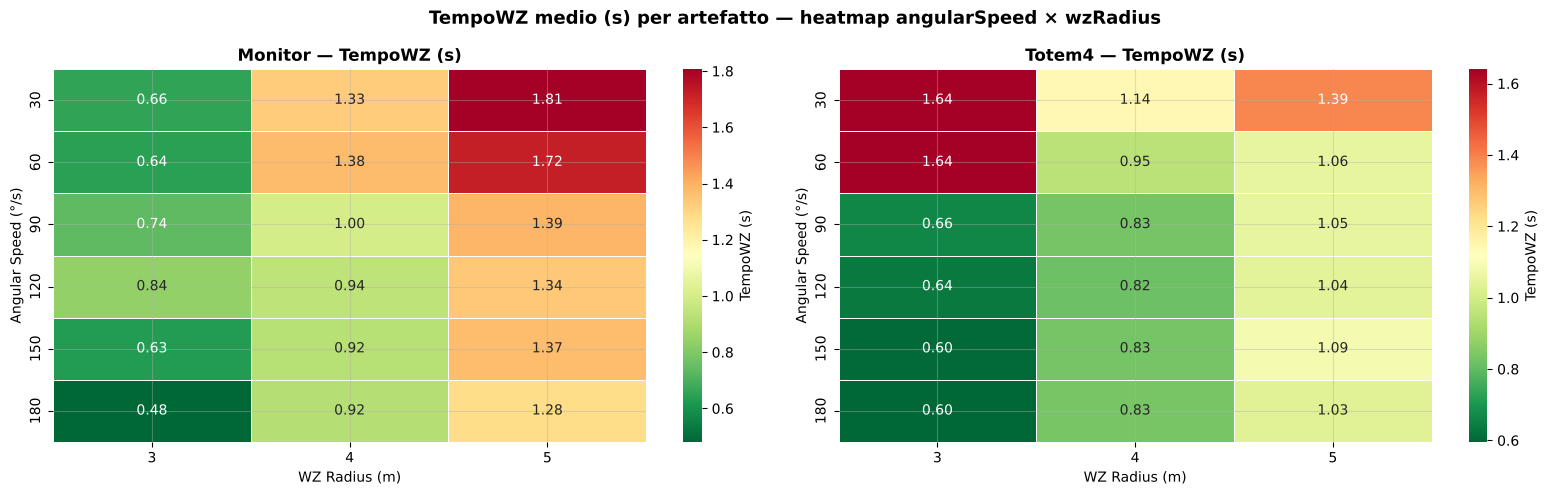

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('TempoWZ medio (s) per artefatto — heatmap angularSpeed × wzRadius',
             fontsize=13, fontweight='bold')

for col_idx, art in enumerate(['Monitor', 'Totem4']):
    twz_pv = clean.pivot_table(
        values=f'Agent1_{art}_TempoWZ',
        index='angularSpeed', columns='wzRadius', aggfunc='mean')
    sns.heatmap(twz_pv, ax=axes[col_idx], annot=True, fmt='.2f',
                cmap='RdYlGn_r', linewidths=0.5, linecolor='white',
                cbar_kws={'label':'TempoWZ (s)'})
    axes[col_idx].set_title(f'{art} — TempoWZ (s)', fontsize=12, fontweight='bold')
    axes[col_idx].set_xlabel('WZ Radius (m)')
    axes[col_idx].set_ylabel('Angular Speed (°/s)')

plt.tight_layout()
plt.savefig('18_tempowz_heatmap_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Le due heatmap mostrano che Monitor ha sistematicamente TempoWZ più alto di Totem4, specialmente con angularSpeed basso e wzRadius grande. Con angularSpeed=30°/s e wzRadius=5m, Monitor produce TempoWZ quasi doppio rispetto a Totem4: l'agente entra nella zona grande ma fatica ad orientarsi verso il punto di interazione del Monitor. Con angularSpeed ≥ 90°/s le differenze si riducono significativamente.


## 19. Distribuzione TempoWZ per artefatto × angularSpeed — box plot

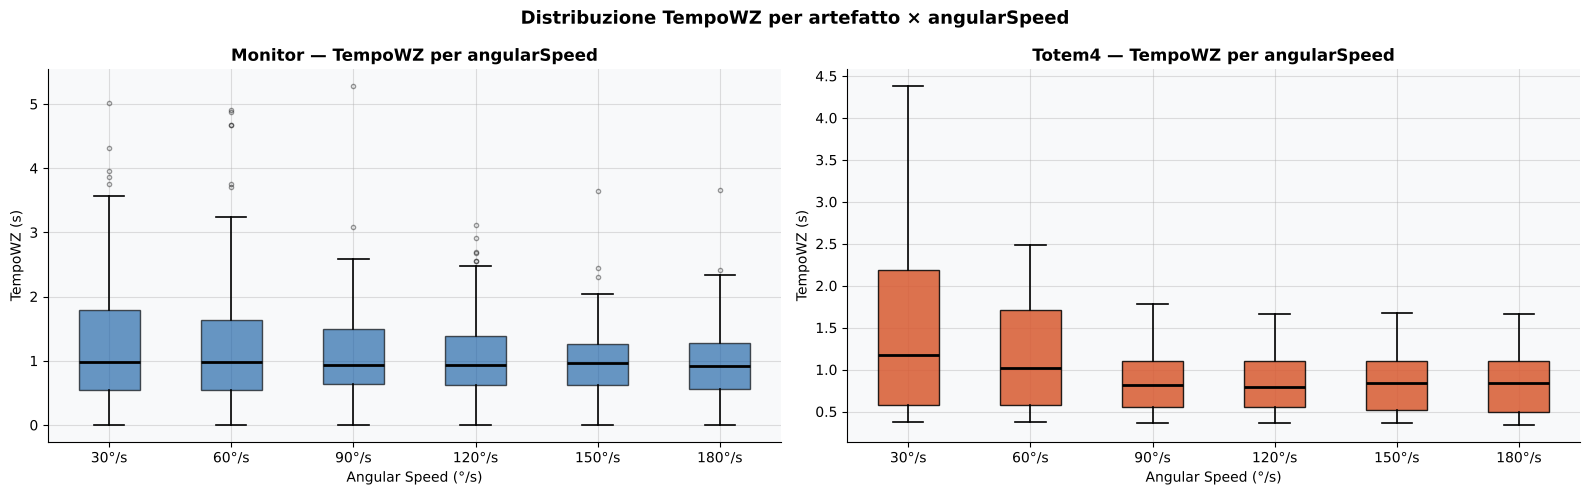

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Distribuzione TempoWZ per artefatto × angularSpeed', fontsize=13, fontweight='bold')

for col_idx, art in enumerate(['Monitor', 'Totem4']):
    ang_vals = sorted(clean['angularSpeed'].unique())
    data = [clean[clean['angularSpeed']==a][f'Agent1_{art}_TempoWZ'].values for a in ang_vals]
    bp = axes[col_idx].boxplot(data, patch_artist=True, notch=False,
                                medianprops={'color':'black','linewidth':2},
                                whiskerprops={'linewidth':1.2},
                                capprops={'linewidth':1.2},
                                flierprops={'marker':'o','markersize':3,'alpha':0.4})
    for patch, ang in zip(bp['boxes'], ang_vals):
        patch.set_facecolor(PALETTE_ART[art])
        patch.set_alpha(0.65 if art=='Monitor' else 0.85)
    axes[col_idx].set_xticklabels([f'{int(a)}°/s' for a in ang_vals])
    axes[col_idx].set_title(f'{art} — TempoWZ per angularSpeed', fontsize=12, fontweight='bold')
    axes[col_idx].set_xlabel('Angular Speed (°/s)')
    axes[col_idx].set_ylabel('TempoWZ (s)')

plt.tight_layout()
plt.savefig('19_boxplot_tempowz_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
I box plot mostrano non solo la media ma l'intera distribuzione. **Totem4** ha baffi molto più corti e IQR più stretto — il comportamento è stabile e prevedibile per tutti i livelli di angularSpeed. **Monitor** ha baffi più lunghi (alta varianza) soprattutto con angularSpeed basso: alcuni episodi vanno molto bene, altri molto male. Con angularSpeed ≥ 120°/s entrambi gli artefatti mostrano distribuzioni simili e compatte.


## 20. NavMesh (%) per artefatto × posizione obiettivo

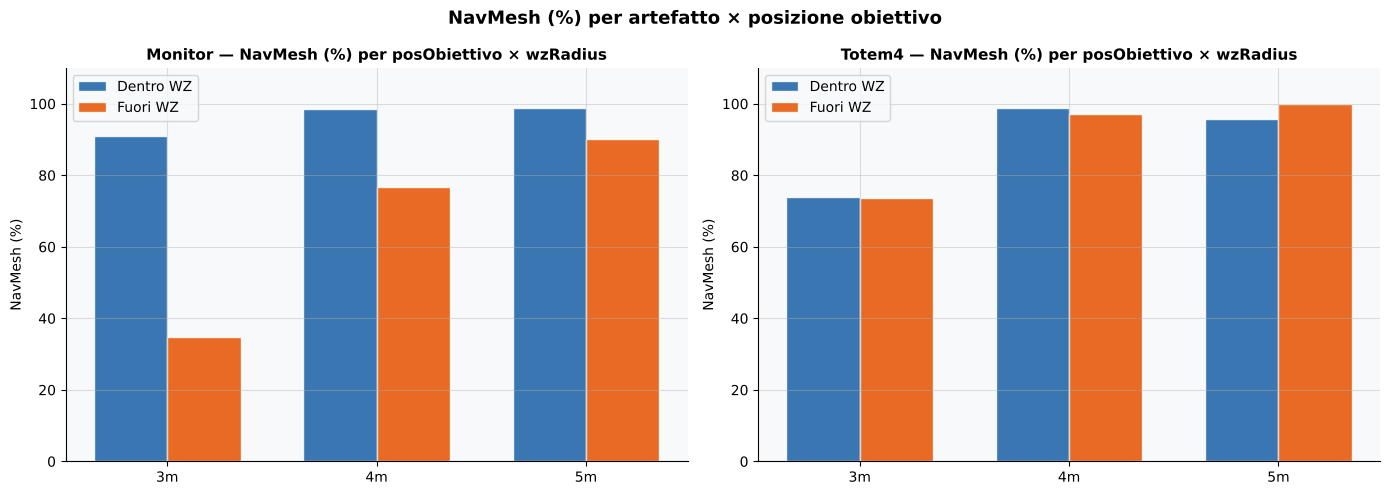

Differenza NavMesh Dentro WZ vs Fuori WZ per artefatto:
  Monitor: Dentro=96.3%, Fuori=67.4%, diff=28.9pp
  Totem4: Dentro=90.2%, Fuori=90.5%, diff=-0.2pp


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NavMesh (%) per artefatto × posizione obiettivo', fontsize=13, fontweight='bold')

wzr_vals = sorted(clean['wzRadius'].unique())
x = np.arange(len(wzr_vals)); w = 0.35

for col_idx, art in enumerate(['Monitor', 'Totem4']):
    nm_col  = f'Agent1_{art}_NavMesh'
    nm_pos  = clean.groupby(['wzRadius','posObiettivo'])[nm_col].mean().reset_index()
    nm_pos['nm_pct'] = nm_pos[nm_col] * 100

    for i, pos in enumerate(['Dentro WZ', 'Fuori WZ']):
        sub = nm_pos[nm_pos['posObiettivo']==pos].set_index('wzRadius').reindex(wzr_vals)
        axes[col_idx].bar(x+i*w, sub['nm_pct'], w, label=pos,
                          color=list(PALETTE_POS.values())[i],
                          alpha=0.85, edgecolor='white')

    axes[col_idx].set_xticks(x+w/2)
    axes[col_idx].set_xticklabels([f'{r}m' for r in wzr_vals])
    axes[col_idx].set_title(f'{art} — NavMesh (%) per posObiettivo × wzRadius',
                             fontsize=11, fontweight='bold')
    axes[col_idx].set_ylabel('NavMesh (%)')
    axes[col_idx].set_ylim(0, 110)
    axes[col_idx].legend()

plt.tight_layout()
plt.savefig('20_navmesh_pos_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()

# Stampa differenza Dentro vs Fuori per artefatto
print("Differenza NavMesh Dentro WZ vs Fuori WZ per artefatto:")
for art in ['Monitor','Totem4']:
    nm_col = f'Agent1_{art}_NavMesh'
    d = clean[clean['posObiettivo']=='Dentro WZ'][nm_col].mean()*100
    f = clean[clean['posObiettivo']=='Fuori WZ'][nm_col].mean()*100
    print(f"  {art}: Dentro={d:.1f}%, Fuori={f:.1f}%, diff={d-f:.1f}pp")


### 💬 Lettura
Per **Totem4** la differenza tra "Dentro WZ" e "Fuori WZ" è relativamente piccola — essendo facile da raggiungere, la posizione dell'obiettivo non cambia molto il risultato. Per **Monitor** la differenza è più marcata: con "Dentro WZ" e wzRadius grande l'agente si avvicina naturalmente al Monitor nel percorso verso l'obiettivo, aumentando la probabilità di entrata in TZ. La condizione "Fuori WZ" è più penalizzante per Monitor che per Totem4.


## 21. Trade-off NavMesh vs TempoWZ per artefatto

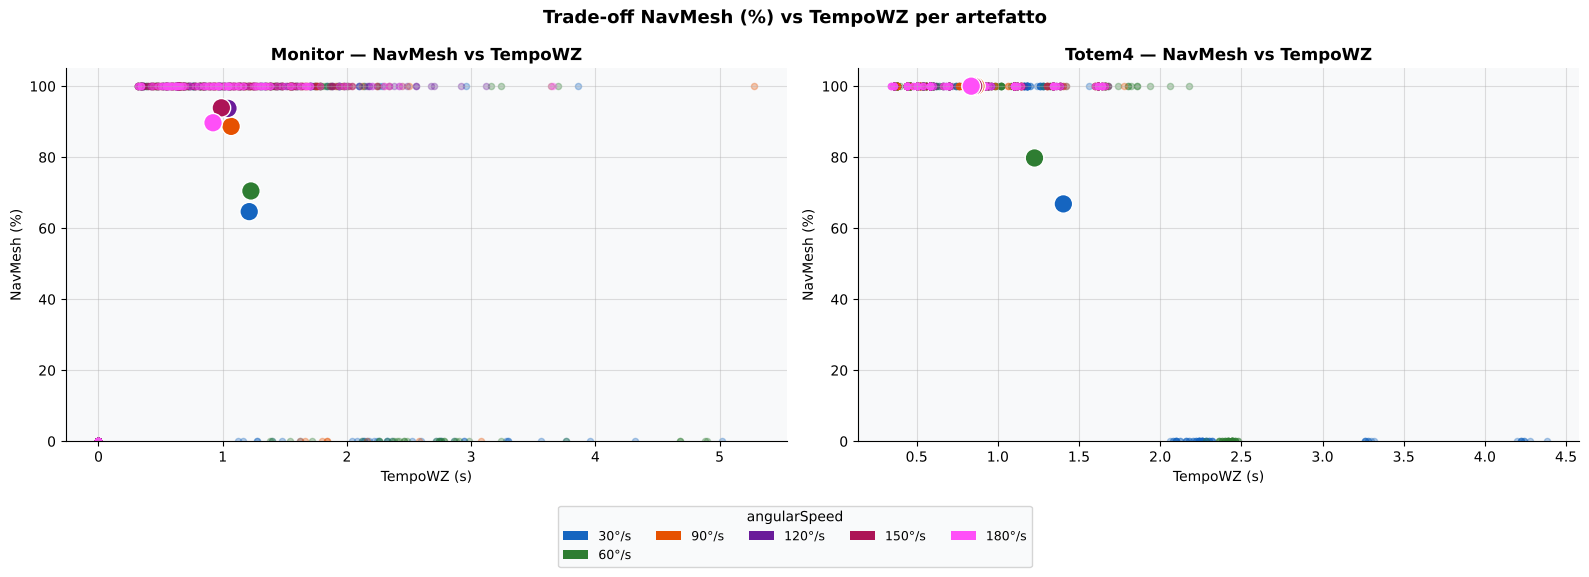

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Trade-off NavMesh (%) vs TempoWZ per artefatto', fontsize=13, fontweight='bold')

for col_idx, art in enumerate(['Monitor', 'Totem4']):
    nm_col  = f'Agent1_{art}_NavMesh'
    twz_col = f'Agent1_{art}_TempoWZ'
    color   = PALETTE_ART[art]

    # Punti per angularSpeed (medie)
    summary = clean.groupby('angularSpeed').agg(
        nm=(nm_col,'mean'), twz=(twz_col,'mean')
    ).reset_index()
    summary['nm_pct'] = summary['nm'] * 100

    # Scatter tutti episodi
    for ang, c in PALETTE_ANG.items():
        sub = clean[clean['angularSpeed']==ang]
        if len(sub)==0: continue
        axes[col_idx].scatter(sub[twz_col], sub[nm_col]*100,
                              color=c, alpha=0.3, s=20)

    # Medie per angularSpeed con annotazione
    axes[col_idx].scatter(summary['twz'], summary['nm_pct'],
                          s=180, zorder=5,
                          c=[PALETTE_ANG[a] for a in summary['angularSpeed']],
                          edgecolors='white', linewidth=1)


    axes[col_idx].set_title(f'{art} — NavMesh vs TempoWZ', fontsize=12, fontweight='bold')
    axes[col_idx].set_xlabel('TempoWZ (s)')
    axes[col_idx].set_ylabel('NavMesh (%)')
    axes[col_idx].set_ylim(0, 105)

# Legenda angularSpeed
patches = [Patch(facecolor=c, label=f'{a}°/s') for a,c in PALETTE_ANG.items()
           if a in clean['angularSpeed'].unique()]
fig.legend(handles=patches, title='angularSpeed',
           loc='upper center',
           bbox_to_anchor=(0.5, 0),
           ncol=5, fontsize=9)

plt.tight_layout()
plt.savefig('21_tradeoff_artefatto.png', dpi=150, bbox_inches='tight')
plt.show()


### 💬 Lettura
Il trade-off è molto diverso tra i due artefatti. **Totem4** mostra già con 60°/s un NavMesh alto e TempoWZ basso — i punti medi si spostano subito verso l'area ottimale. **Monitor** ha una progressione più lenta: anche a 90°/s il NavMesh medio non raggiunge i valori di Totem4, e il TempoWZ rimane più alto. La dispersione dei punti è maggiore per Monitor — comportamento meno prevedibile. Questo grafico mostra chiaramente perché l'ottimizzazione deve puntare a rendere Monitor più affidabile.


In [20]:
# Salva tabella riassuntiva
summary = clean.groupby(['angularSpeed','wzRadius','warnMult']).agg(
    navMesh_pct=('Agent1_NavMesh', lambda x: x.mean()*100),
    tempoWZ_mean=('Agent1_TempoWZ','mean'),
    tempoTZ_mean=('Agent1_TempoTZ','mean'),
    tempoTot_mean=('Agent1_TempoTot','mean'),
    monitor_nm=('Agent1_Monitor_NavMesh', lambda x: x.mean()*100),
    totem4_nm=('Agent1_Totem4_NavMesh',  lambda x: x.mean()*100),
    n=('Agent1_NavMesh','count')
).reset_index()
summary['score'] = (
    summary['navMesh_pct']/100 * 40 +
    (1 - summary['tempoWZ_mean']/summary['tempoWZ_mean'].max()) * 30 +
    (1 - summary['tempoTot_mean']/summary['tempoTot_mean'].max()) * 30
)
summary = summary.sort_values('score', ascending=False)
summary.to_csv('summary_configurazioni.csv', index=False)
print(f"Tabella riassuntiva salvata in summary_configurazioni.csv")
print(f"Dataset: {len(clean)} configurazioni valide su {len(filled)} totali.")
print(summary[["angularSpeed","wzRadius","warnMult","navMesh_pct","tempoWZ_mean","monitor_nm","totem4_nm","score"]].head(10).to_string(index=False))


Tabella riassuntiva salvata in summary_configurazioni.csv
Dataset: 1015 configurazioni valide su 1296 totali.
 angularSpeed  wzRadius  warnMult  navMesh_pct  tempoWZ_mean  monitor_nm  totem4_nm     score
          120         3      0.65    95.454545      1.163636   90.909091      100.0 60.696510
          150         3      0.50    95.833333      1.236667   91.666667      100.0 58.518944
          180         3      0.65    87.500000      1.200000   75.000000      100.0 57.986746
           90         3      0.50    95.000000      1.282000   90.000000      100.0 57.950244
          180         3      0.50    86.363636      1.016364   72.727273      100.0 57.943675
          180         3      0.80    87.500000      1.066667   75.000000      100.0 57.749055
          150         3      0.80    90.909091      1.247273   81.818182      100.0 57.629324
          150         3      0.95    83.333333      1.046667   66.666667      100.0 57.278604
          150         4      0.95   100.0000

## 22. Impatto della proporzione TZ / WZ sulle prestazioni

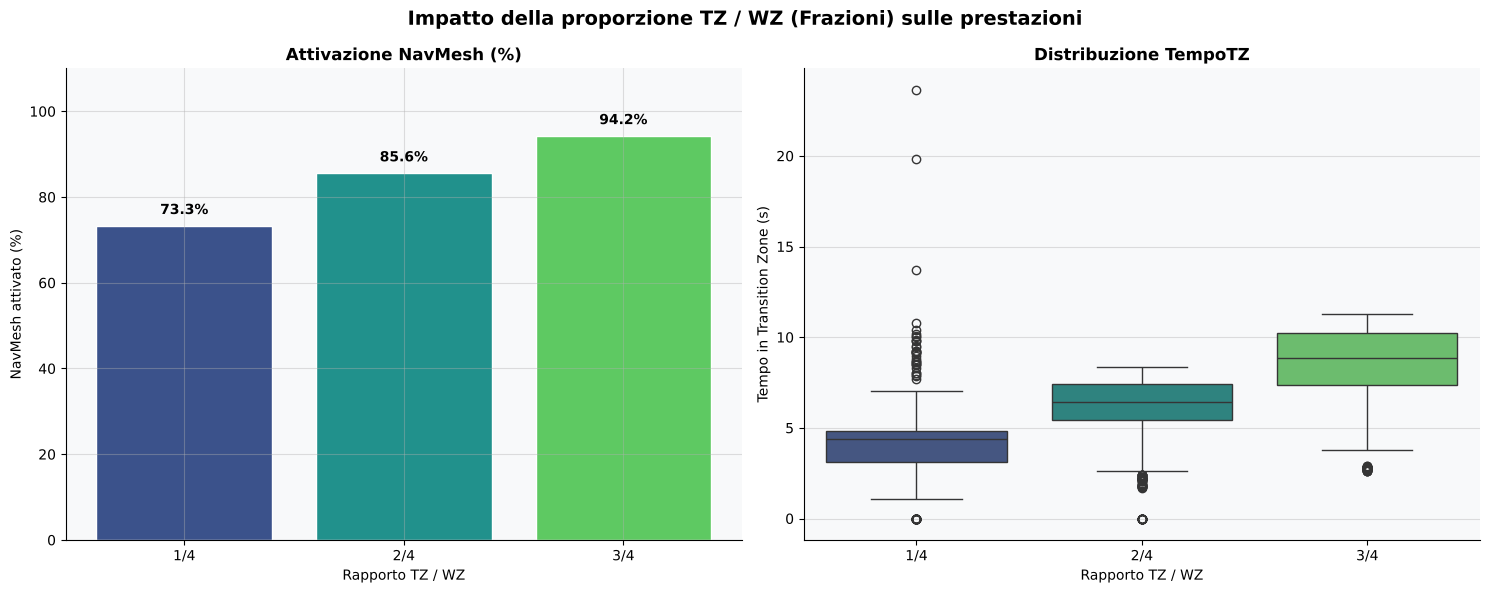

In [21]:
# Creiamo la proporzione matematica
if 'TZ_WZ_Ratio_num' not in clean.columns:
    clean['TZ_WZ_Ratio_num'] = clean['tzRadius'] / clean['wzRadius']

# Funzione per mappare in frazioni testuali
def to_fraction(val):
    if np.isclose(val, 0.25): return '1/4'
    if np.isclose(val, 0.50): return '2/4'
    if np.isclose(val, 0.75): return '3/4'
    return f"{val:.2f}"

clean['TZ_WZ_Ratio'] = clean['TZ_WZ_Ratio_num'].apply(to_fraction)
order_fractions = ['1/4', '2/4', '3/4']

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Impatto della proporzione TZ / WZ (Frazioni) sulle prestazioni', fontsize=14, fontweight='bold')

# Grafico 1: Percentuale di attivazione NavMesh
nm_ratio = clean.groupby('TZ_WZ_Ratio')['Agent1_NavMesh'].mean().reindex(order_fractions) * 100
bars = axes[0].bar(nm_ratio.index, nm_ratio.values,
                   color=sns.color_palette("viridis", len(nm_ratio)), edgecolor='white')
axes[0].set_title('Attivazione NavMesh (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rapporto TZ / WZ')
axes[0].set_ylabel('NavMesh attivato (%)')
axes[0].set_ylim(0, 110)

for i, v in enumerate(nm_ratio.values):
    if not np.isnan(v):
        axes[0].text(i, v + 2, f'{v:.1f}%', ha='center', va='bottom', fontweight='bold')

# Grafico 2: Distribuzione del TempoTZ (Boxplot)
sns.boxplot(data=clean, x='TZ_WZ_Ratio', y='Agent1_TempoTZ', ax=axes[1],
            palette="viridis", order=order_fractions)
axes[1].set_title('Distribuzione TempoTZ', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rapporto TZ / WZ')
axes[1].set_ylabel('Tempo in Transition Zone (s)')

plt.tight_layout()
plt.savefig('22_impatto_tz_wz.png', dpi=150, bbox_inches='tight')
plt.show()

### 💬 Lettura
La proporzione tra la Transition Zone (TZ) e la Warning Zone (WZ) gioca un ruolo chiave nella fluidità della simulazione. Il grafico a barre mostra che un rapporto di 3/4 massimizza l'attivazione del NavMesh. Ancora più evidente è l'impatto sui tempi (Boxplot): una Transition Zone proporzionalmente più ampia (3/4) schiaccia la distribuzione verso il basso, garantendo tempi di attraversamento molto rapidi e costanti. Al contrario, un rapporto di 1/4 non offre all'agente lo spazio di manovra necessario, causando code di tempo estreme e instabilità.

## 23. Heatmap Punteggio Medio: Proporzione TZ/WZ vs Raggio WZ

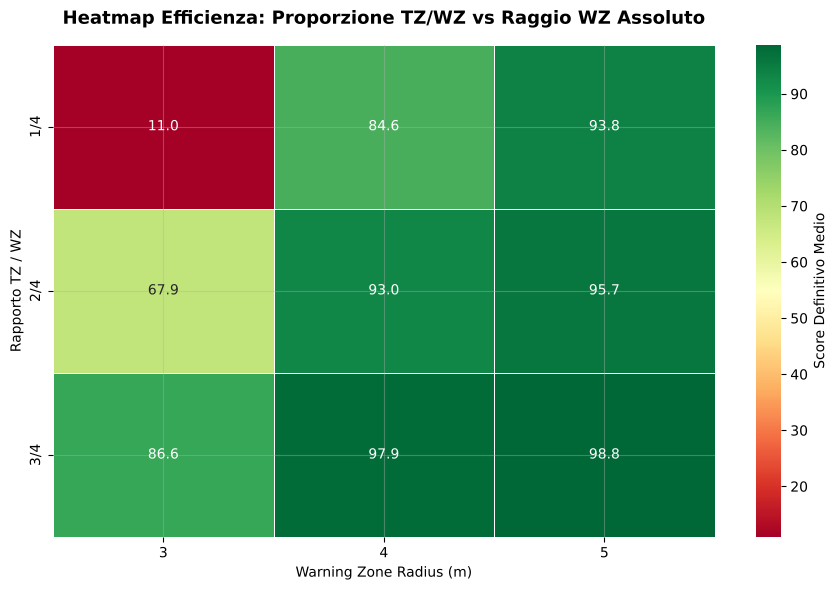

In [22]:
# Creiamo la pivot table per la heatmap usando il New_Score (o Score_Definitivo)
# Se 'New_Score' non è presente, ricalcoliamo temporaneamente un proxy basato su NavMesh
score_col = 'New_Score' if 'New_Score' in clean.columns else 'Agent1_NavMesh'

heatmap_data = clean.pivot_table(values=score_col, index='TZ_WZ_Ratio', columns='wzRadius', aggfunc='mean')
heatmap_data = heatmap_data.reindex(order_fractions)

if score_col == 'Agent1_NavMesh':
    heatmap_data = heatmap_data * 100  # Convertiamo in percentuale

plt.figure(figsize=(9, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="RdYlGn",
            linewidths=.5, linecolor='white',
            cbar_kws={'label': 'Score Definitivo Medio'})
plt.title("Heatmap Efficienza: Proporzione TZ/WZ vs Raggio WZ Assoluto", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Warning Zone Radius (m)")
plt.ylabel("Rapporto TZ / WZ")

plt.tight_layout()
plt.savefig('23_heatmap_tz_wz.png', dpi=150, bbox_inches='tight')
plt.show()

### 💬 Lettura
La Heatmap rivela l'interazione critica tra lo spazio assoluto e quello relativo. Le configurazioni peggiori si concentrano dove il `wzRadius` è piccolo (3m) e il rapporto TZ/WZ è minimo (1/4), confermando che un raggio assoluto della TZ di soli 0.75m è un limite fisico strutturale che causa il blocco sistematico dell'agente. Man mano che il raggio assoluto della WZ aumenta a 4m o 5m, le prestazioni migliorano, ma la proporzione 3/4 si conferma sempre come la fascia trasversale di massima efficienza.

## 24. Tempi di attraversamento: Scatterplot e Violin Plot (Solo Successi)

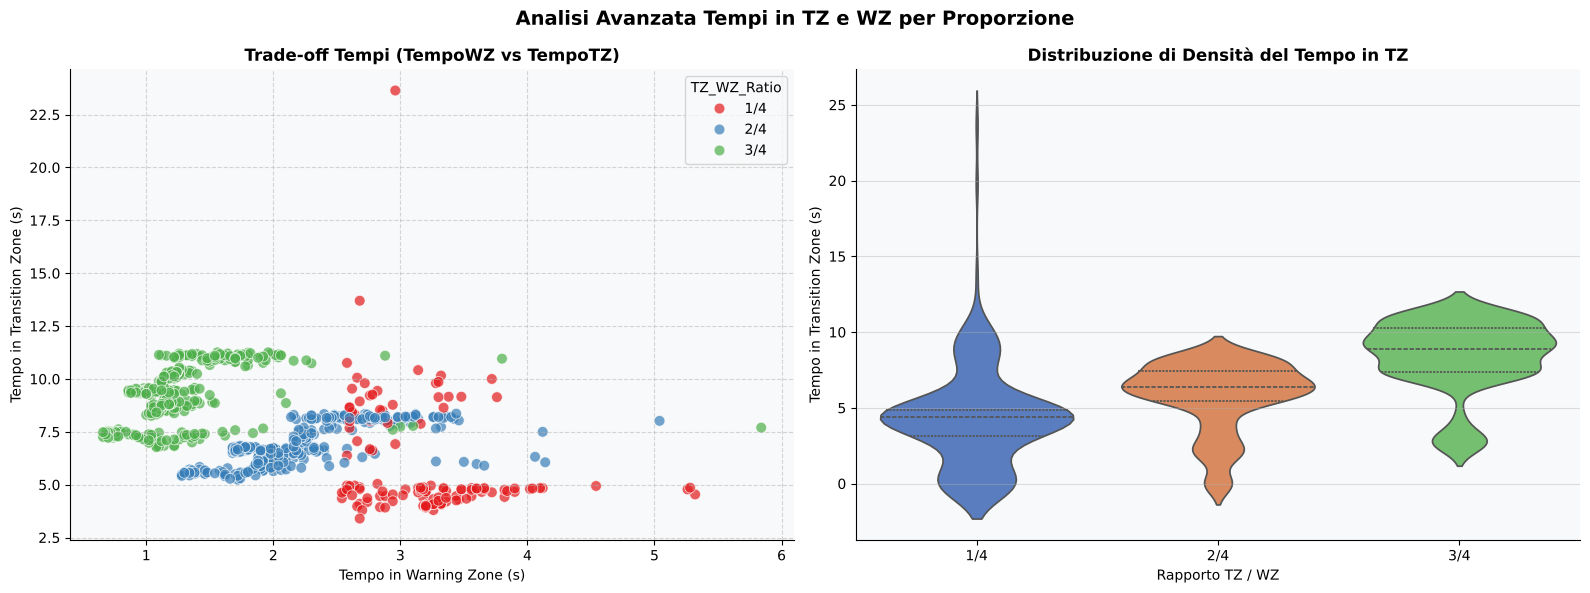

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Analisi Avanzata Tempi in TZ e WZ per Proporzione', fontsize=14, fontweight='bold')

# Filtriamo i timeout o i fallimenti per avere un'analisi pulita dei tempi (solo successi)
valid_times = clean[clean['Agent1_NavMesh'] == 1]

# Scatterplot
sns.scatterplot(data=valid_times, x='Agent1_TempoWZ', y='Agent1_TempoTZ',
                hue='TZ_WZ_Ratio', hue_order=order_fractions,
                palette='Set1', alpha=0.7, s=60, ax=axes[0])
axes[0].set_title("Trade-off Tempi (TempoWZ vs TempoTZ)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Tempo in Warning Zone (s)")
axes[0].set_ylabel("Tempo in Transition Zone (s)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Violin Plot
sns.violinplot(data=clean, x='TZ_WZ_Ratio', y='Agent1_TempoTZ',
               order=order_fractions, palette='muted', inner="quartile", ax=axes[1])
axes[1].set_title("Distribuzione di Densità del Tempo in TZ", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Rapporto TZ / WZ")
axes[1].set_ylabel("Tempo in Transition Zone (s)")

plt.tight_layout()
plt.savefig('24_tempi_scatter_violin.png', dpi=150, bbox_inches='tight')
plt.show()

### 💬 Lettura
Questi due grafici sviscerano l'efficienza temporale delle configurazioni. Nello Scatterplot (Sinistra), i punti del rapporto 3/4 tendono a concentrarsi nell'area in basso a sinistra: il "golden path" in cui l'agente spende pochissimo tempo in entrambe le zone.
Il Violin Plot (Destra) evidenzia il fattore stabilità: la "pancia" allungata verso l'alto del rapporto 1/4 indica un'estrema imprevedibilità (frequenti stalli prolungati). Il violino del 3/4 è invece corto e raggruppato in prossimità dello zero, sinonimo di un passaggio verso il NavMesh rapido e costantemente riproducibile.


## 25. Impatto del warningSpeedMultiplier sull'Efficienza Pura

In [24]:
# Calcolo dei valori per la normalizzazione
clean['RadiusTot'] = clean['wzRadius'] + clean['tzRadius']
rad_min, rad_max = clean['RadiusTot'].min(), clean['RadiusTot'].max()
twz_max = clean['Agent1_TempoWZ'].max()
ttz_max = clean['Agent1_TempoTZ'].max()
ttot_max = clean['Agent1_TempoTot'].max()

# Calcolo dello Score di Pura Efficienza (senza premiare in modo lineare il warnMult)
clean['Score_Efficienza'] = (
    (clean['Agent1_NavMesh'] * 50) +
    ((1 - (clean['RadiusTot'] - rad_min) / (rad_max - rad_min)) * 25) +
    ((1 - clean['Agent1_TempoWZ'] / twz_max) * 10) +
    ((1 - clean['Agent1_TempoTZ'] / ttz_max) * 10) +
    ((1 - clean['Agent1_TempoTot'] / ttot_max) * 5)
)

# Analisi aggregata per warningSpeedMultiplier
warn_analysis = clean.groupby('warnMult').agg(
    Score_Efficienza_Medio=('Score_Efficienza', 'mean'),
    NavMesh_pct=('Agent1_NavMesh', lambda x: x.mean() * 100),
    TempoWZ_Medio=('Agent1_TempoWZ', 'mean'),
    TempoTot_Medio=('Agent1_TempoTot', 'mean')
).reset_index().sort_values('Score_Efficienza_Medio', ascending=False)

print("--- Analisi dell'Efficienza per warningSpeedMultiplier ---")
display(warn_analysis.round(2).reset_index(drop=True))


--- Analisi dell'Efficienza per warningSpeedMultiplier ---


,warnMult,Score_Efficienza_Medio,NavMesh_pct,TempoWZ_Medio,TempoTot_Medio
0,0.65,71.94,88.54,2.07,34.34
1,0.50,71.43,87.25,2.13,34.22
2,0.80,71.28,86.36,2.09,34.11
3,0.95,70.74,84.25,2.10,33.96


### 💬 Lettura
Isolando lo "Score di Pura Efficienza", emerge un risultato controintuitivo fondamentale: l'approccio "più veloce è meglio" è dannoso per l'algoritmo. Un moltiplicatore di `0.95` (quasi nessuna frenata) riduce i tempi totali, ma fa crollare l'affidabilità del NavMesh (84%). L'agente entra in Warning Zone con un'inerzia eccessiva, negando al sistema lo spazio-tempo per elaborare la transizione.
Il "sweet spot" è rappresentato da `0.65`: una moderata decelerazione (-35%) garantisce il picco massimo di affidabilità (NavMesh > 88%) e il miglior bilanciamento temporale. Questo risultato sancisce la convergenza tra necessità ingegneristiche e realismo biomeccanico: imporre un approccio realistico all'ostacolo stabilizza l'IA e ottimizza il percorso.


## 26. Analisi statistica: selezione dei parametri ottimali

Le sezioni precedenti mostrano differenze **descrittive** tra parametri (medie, heatmap, box plot). Da qui in avanti la selezione della configurazione ottimale non si basa più su un punteggio pesato arbitrariamente (Score_Definitivo), ma su una **sequenza di test statistici** (Kruskal-Wallis + Dunn post-hoc), applicata solo alle combinazioni affidabili (tre ripetizioni valide su tre e NavMesh=100% in tutte) e con l'ordine dei filtri determinato dai dati stessi (effect size), non da un'ipotesi a priori.

In [25]:
!pip install scikit-posthocs pingouin -q

In [26]:
from scipy.stats import kruskal, shapiro, levene
import scikit_posthocs as sp
import pingouin as pg

def filtro_sequenziale(df, param, metric, direction='max', alpha=0.05, label=''):
    """
    Esegue Kruskal-Wallis + Dunn post-hoc su `param` rispetto a `metric`,
    poi mantiene solo le righe dei livelli di `param` statisticamente
    equivalenti al migliore (p > alpha nel test di Dunn vs il livello top).
    Se il parametro non ha effetto significativo, non filtra nulla.
    """
    groups = [g[metric].values for _, g in df.groupby(param)]
    h, pval = kruskal(*groups)
    print(f"--- Filtro: {label or param} (su {metric}) ---")
    print(f"Kruskal-Wallis: H={h:.2f}  p={pval:.2e}  "
          f"({'effetto significativo' if pval < alpha else 'NESSUN effetto significativo -> filtro non applicato'})")

    if pval >= alpha:
        print(f"  -> {param} non discrimina: nessuna riga esclusa.\n")
        return df.copy()

    means = df.groupby(param)[metric].mean()
    best_level = means.idxmax() if direction == 'max' else means.idxmin()

    dunn = sp.posthoc_dunn(df, val_col=metric, group_col=param, p_adjust='bonferroni')
    equivalenti = dunn[best_level][dunn[best_level] > alpha].index.tolist()

    print(f"  Livello migliore: {param}={best_level} ({metric} {'max' if direction=='max' else 'min'}={means[best_level]:.2f})")
    print(f"  Livelli statisticamente equivalenti (p>{alpha}): {sorted(equivalenti)}")

    out = df[df[param].isin(equivalenti)].copy()
    print(f"  Righe: {len(df)} -> {len(out)}\n")
    return out

In [27]:
# CRITERIO DI AFFIDABILITÀ — si tengono solo le combinazioni di parametri con
# tutte e tre le ripetizioni valide dopo la pulizia E con NavMesh = 100% in tutte.
# Ogni fallimento conta allo stesso modo: un timeout, un episodio anomalo (oltre il
# 95° percentile) o un artefatto saltato escludono l'intera combinazione.
CHIAVI = ['angularSpeed','wzRadius','tzRadius','warnMult','posObiettivo']

per_combo = (clean.groupby(CHIAVI)
             .agg(n_valide=('Agent1_NavMesh', 'size'), NavMesh=('Agent1_NavMesh', 'mean'))
             .reset_index())
tutte = filled.groupby(CHIAVI).size().reset_index()[CHIAVI]
tre_valide = per_combo[per_combo['n_valide'] == 3]
affidabili = tre_valide[tre_valide['NavMesh'] == 1.0]

print(f"Combinazioni della griglia:                       {len(tutte)}")
print(f"  con almeno una ripetizione valida:              {len(per_combo)}")
print(f"  con tutte e tre le ripetizioni valide:          {len(tre_valide)}")
print(f"  affidabili (tre valide e NavMesh=100% in tutte): {len(affidabili)}\n")

stage0 = clean.merge(affidabili[CHIAVI], on=CHIAVI, how='inner')
print(f"Righe: {len(clean)} -> {len(stage0)}\n")

# Motivo dell'esclusione delle altre combinazioni
esc = tutte.merge(per_combo, on=CHIAVI, how='left').fillna({'n_valide': 0, 'NavMesh': 0})
esc['ratio'] = (esc['tzRadius'] / esc['wzRadius']).round(2)
persa = esc[esc['n_valide'] < 3]
nessuna = esc[esc['n_valide'] == 0]
parziale = esc[(esc['n_valide'] > 0) & (esc['n_valide'] < 3)]
print(f"Senza ripetizioni valide:                         {len(nessuna)} (TZ a 1/4: {(nessuna['ratio'] == 0.25).sum()})")
print(f"Con una o due ripetizioni valide:                 {len(parziale)} (TZ a 1/4: {(parziale['ratio'] == 0.25).sum()})")
print(f"Simulazioni delle combinazioni con tre valide:    {int(tre_valide['n_valide'].sum())}")
salta = esc[(esc['n_valide'] == 3) & (esc['NavMesh'] < 1)]
print(f"Escluse per una ripetizione persa nella pulizia: {len(persa)} "
      f"(TZ a 1/4: {(persa['ratio'] == 0.25).sum()})")
print(f"Escluse per un artefatto saltato:                {len(salta)} "
      f"(30 o 60°/s: {salta['angularSpeed'].isin([30, 60]).sum()}, "
      f"obiettivo fuori dalla WZ: {(salta['posObiettivo'] == 'Fuori WZ').sum()})\n")

# Criterio meno severo, usato nella prima versione dell'analisi: NavMesh=100% sulle
# sole ripetizioni valide, anche se sono una o due. Serve per la verifica della Sez. 31-bis.
combo_100_meno_severo = per_combo[per_combo['NavMesh'] == 1.0]
stage0_meno_severo = clean.merge(combo_100_meno_severo[CHIAVI], on=CHIAVI, how='inner')
print(f"Criterio meno severo: {len(combo_100_meno_severo)} combinazioni, {len(stage0_meno_severo)} righe\n")

for p in CHIAVI:
    print(f"  {p}: {sorted(stage0[p].unique())}")

def to_fraction(val):
    if np.isclose(val, 0.25): return '1/4'
    if np.isclose(val, 0.50): return '2/4'
    if np.isclose(val, 0.75): return '3/4'
    return f"{val:.2f}"

# Rapporto TZ/WZ come categoria (usato al posto del solo tzRadius)
for _df in (stage0, stage0_meno_severo):
    _df['TZ_WZ_Ratio_num'] = _df['tzRadius'] / _df['wzRadius']
    _df['TZ_WZ_Ratio'] = _df['TZ_WZ_Ratio_num'].apply(to_fraction)


Combinazioni della griglia:                       432
  con almeno una ripetizione valida:              386
  con tutte e tre le ripetizioni valide:          277
  affidabili (tre valide e NavMesh=100% in tutte): 196

Righe: 1015 -> 588

Senza ripetizioni valide:                         46 (TZ a 1/4: 45)
Con una o due ripetizioni valide:                 109 (TZ a 1/4: 67)
Simulazioni delle combinazioni con tre valide:    831
Escluse per una ripetizione persa nella pulizia: 155 (TZ a 1/4: 112)
Escluse per un artefatto saltato:                81 (30 o 60°/s: 52, obiettivo fuori dalla WZ: 62)

Criterio meno severo: 278 combinazioni, 723 righe

  angularSpeed: [np.int64(30), np.int64(60), np.int64(90), np.int64(120), np.int64(150), np.int64(180)]
  wzRadius: [np.int64(3), np.int64(4), np.int64(5)]
  tzRadius: [np.float64(1.0), np.float64(1.25), np.float64(1.5), np.float64(2.0), np.float64(2.25), np.float64(2.5), np.float64(3.0), np.float64(3.75)]
  warnMult: [np.float64(0.5), np.float64(0.

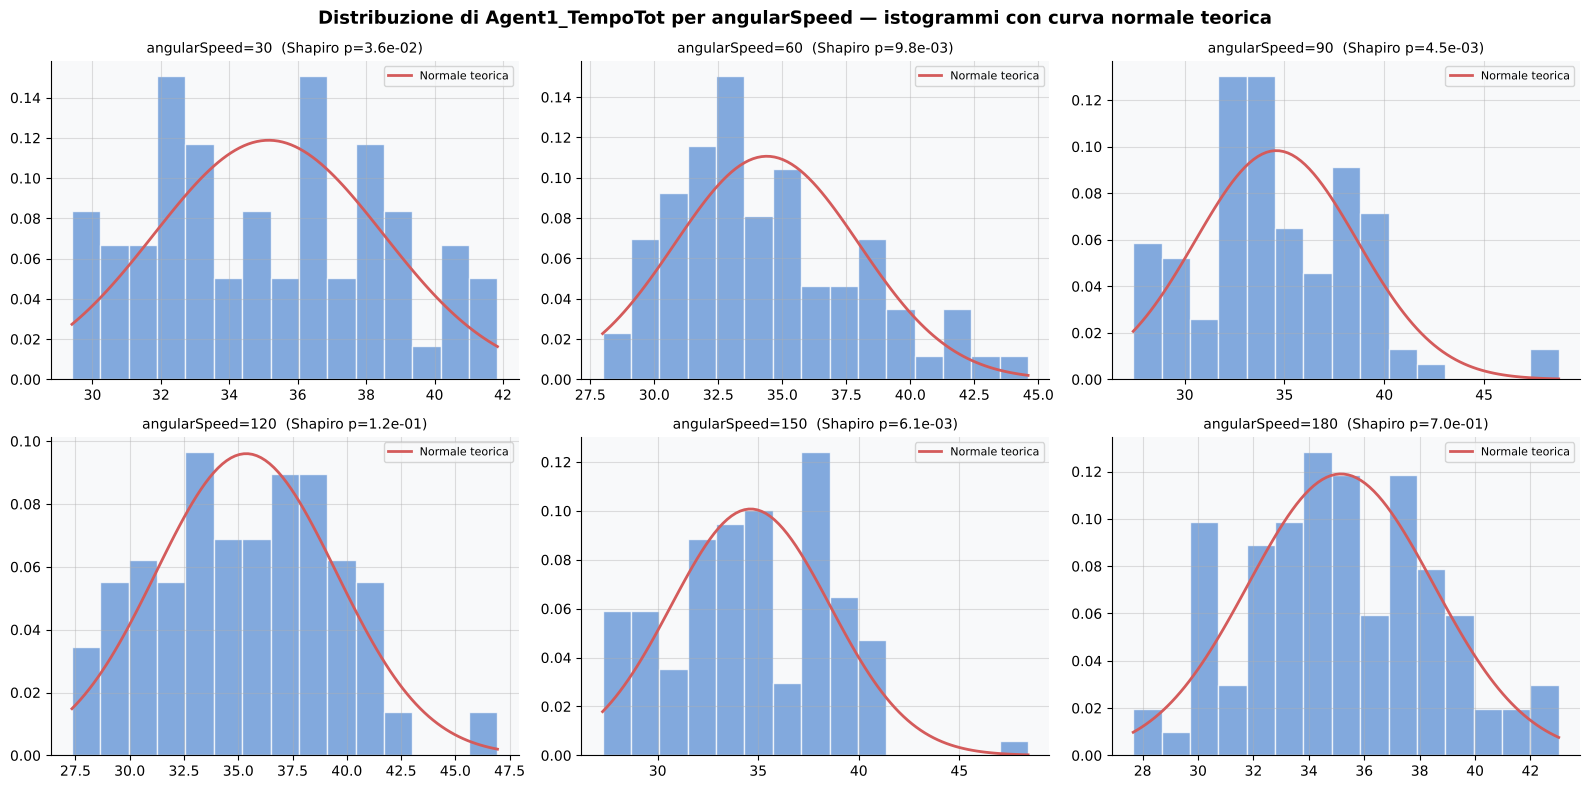

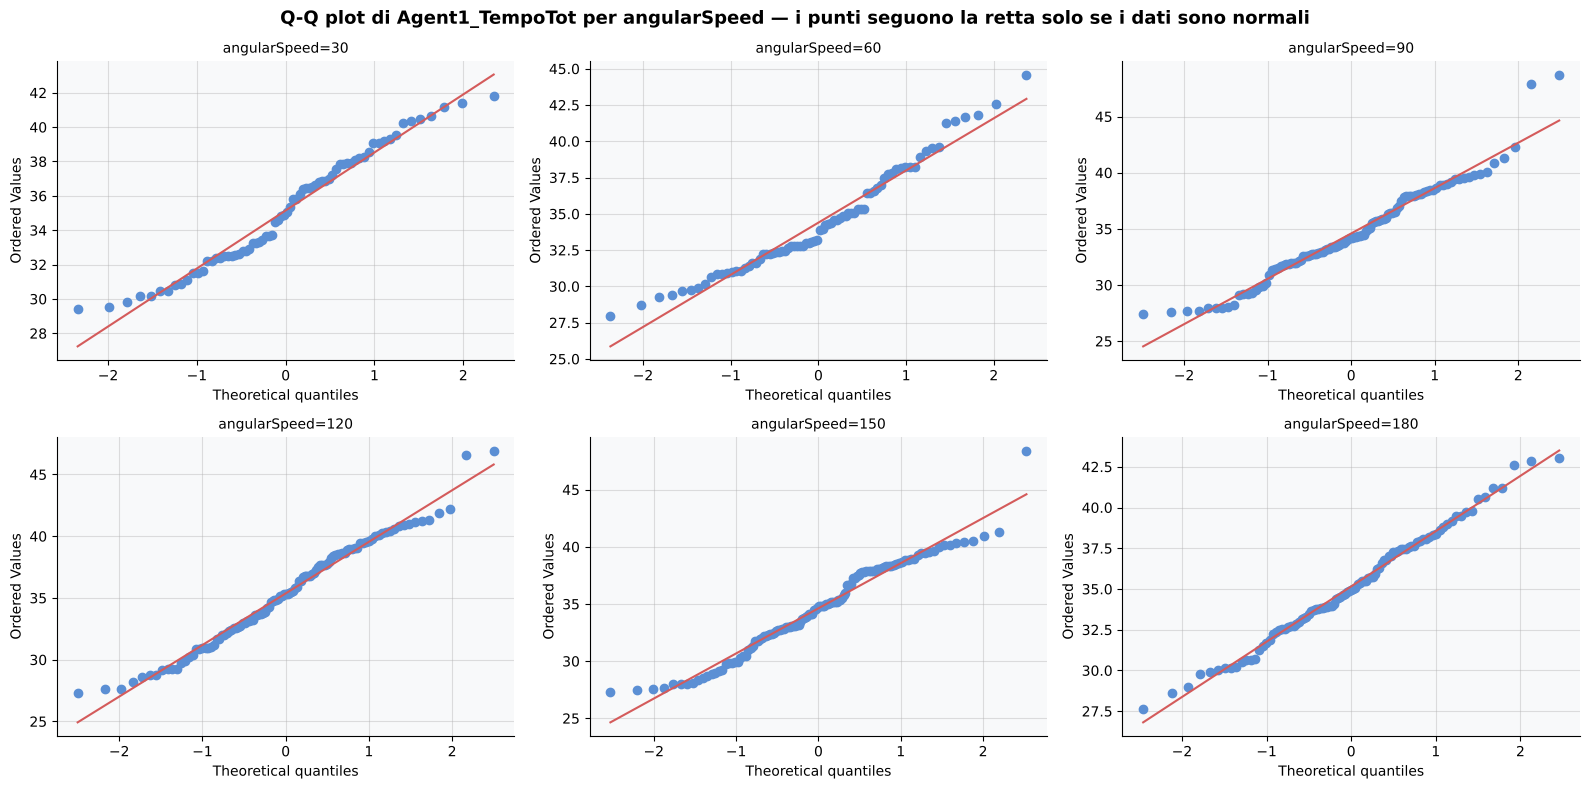

In [28]:
# Visualizzazione esplicita della non-normalità: istogrammi + Q-Q plot

from scipy.stats import probplot

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Distribuzione di Agent1_TempoTot per angularSpeed — istogrammi con curva normale teorica',
             fontsize=13, fontweight='bold')

ang_levels = sorted(stage0['angularSpeed'].unique())
for i, lvl in enumerate(ang_levels):
    ax = axes.flat[i]
    data = stage0[stage0['angularSpeed'] == lvl]['Agent1_TempoTot']
    ax.hist(data, bins=15, density=True, color='#5B8FD4', alpha=0.75, edgecolor='white')

    mu, sigma = data.mean(), data.std()
    x = np.linspace(data.min(), data.max(), 100)
    ax.plot(x, (1/(sigma*np.sqrt(2*np.pi)))*np.exp(-0.5*((x-mu)/sigma)**2),
            color='#D45B5B', linewidth=2, label='Normale teorica')

    stat, pv = shapiro(data)
    ax.set_title(f"angularSpeed={lvl}  (Shapiro p={pv:.1e})", fontsize=10)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('27_istogrammi_normalita.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Q-Q plot: scostamento dalla retta = scostamento dalla normalità ---
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Q-Q plot di Agent1_TempoTot per angularSpeed — i punti seguono la retta solo se i dati sono normali',
             fontsize=13, fontweight='bold')

for i, lvl in enumerate(ang_levels):
    ax = axes.flat[i]
    data = stage0[stage0['angularSpeed'] == lvl]['Agent1_TempoTot']
    probplot(data, dist="norm", plot=ax)
    ax.set_title(f"angularSpeed={lvl}", fontsize=10)
    ax.get_lines()[0].set_markerfacecolor('#5B8FD4')
    ax.get_lines()[0].set_markeredgecolor('#5B8FD4')
    ax.get_lines()[1].set_color('#D45B5B')

plt.tight_layout()
plt.savefig('27_qqplot_normalita.png', dpi=150, bbox_inches='tight')
plt.show()

## 27. Verifica delle assunzioni statistiche

Prima di applicare Kruskal-Wallis, verifichiamo empiricamente le sue assunzioni sulle combinazioni affidabili (Sez. 26), invece di darle per scontate.

In [29]:
parametri_da_verificare = ['angularSpeed', 'wzRadius', 'TZ_WZ_Ratio', 'posObiettivo', 'warnMult']

print("Normalità per gruppo (Shapiro-Wilk su Agent1_TempoTot)")
for p in parametri_da_verificare:
    print(f"\n-- {p} --")
    for lvl, g in stage0.groupby(p):
        stat, pv = shapiro(g['Agent1_TempoTot'])
        print(f"  {p}={lvl}: Shapiro p={pv:.4f}", "NON normale" if pv < 0.05 else "normale")

print("\nOmogeneità della varianza (Levene su Agent1_TempoTot)")
for p in parametri_da_verificare:
    groups = [g['Agent1_TempoTot'].values for _, g in stage0.groupby(p)]
    stat, pv = levene(*groups)
    print(f"  {p}: Levene p={pv:.4f}", "varianze diverse" if pv < 0.05 else "varianze omogenee")

Normalità per gruppo (Shapiro-Wilk su Agent1_TempoTot)

-- angularSpeed --
  angularSpeed=30: Shapiro p=0.0364 NON normale
  angularSpeed=60: Shapiro p=0.0098 NON normale
  angularSpeed=90: Shapiro p=0.0045 NON normale
  angularSpeed=120: Shapiro p=0.1158 normale
  angularSpeed=150: Shapiro p=0.0061 NON normale
  angularSpeed=180: Shapiro p=0.6982 normale

-- wzRadius --
  wzRadius=3: Shapiro p=0.0001 NON normale
  wzRadius=4: Shapiro p=0.0175 NON normale
  wzRadius=5: Shapiro p=0.0002 NON normale

-- TZ_WZ_Ratio --
  TZ_WZ_Ratio=1/4: Shapiro p=0.0001 NON normale
  TZ_WZ_Ratio=2/4: Shapiro p=0.0003 NON normale
  TZ_WZ_Ratio=3/4: Shapiro p=0.0000 NON normale

-- posObiettivo --
  posObiettivo=Dentro WZ: Shapiro p=0.0000 NON normale
  posObiettivo=Fuori WZ: Shapiro p=0.0000 NON normale

-- warnMult --
  warnMult=0.5: Shapiro p=0.0392 NON normale
  warnMult=0.65: Shapiro p=0.0466 NON normale
  warnMult=0.8: Shapiro p=0.0011 NON normale
  warnMult=0.95: Shapiro p=0.0211 NON normale

Omogen

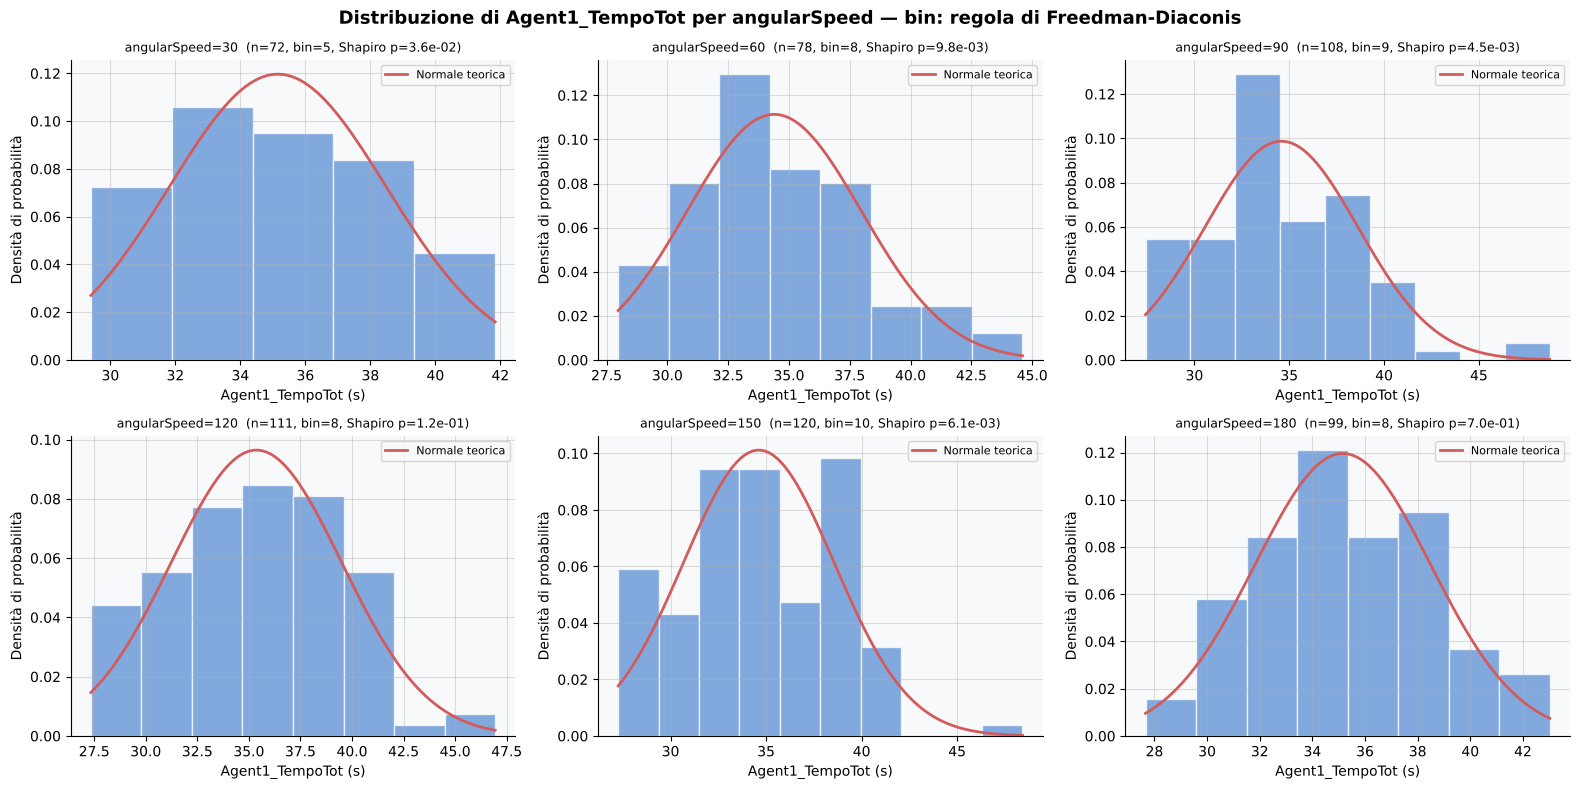

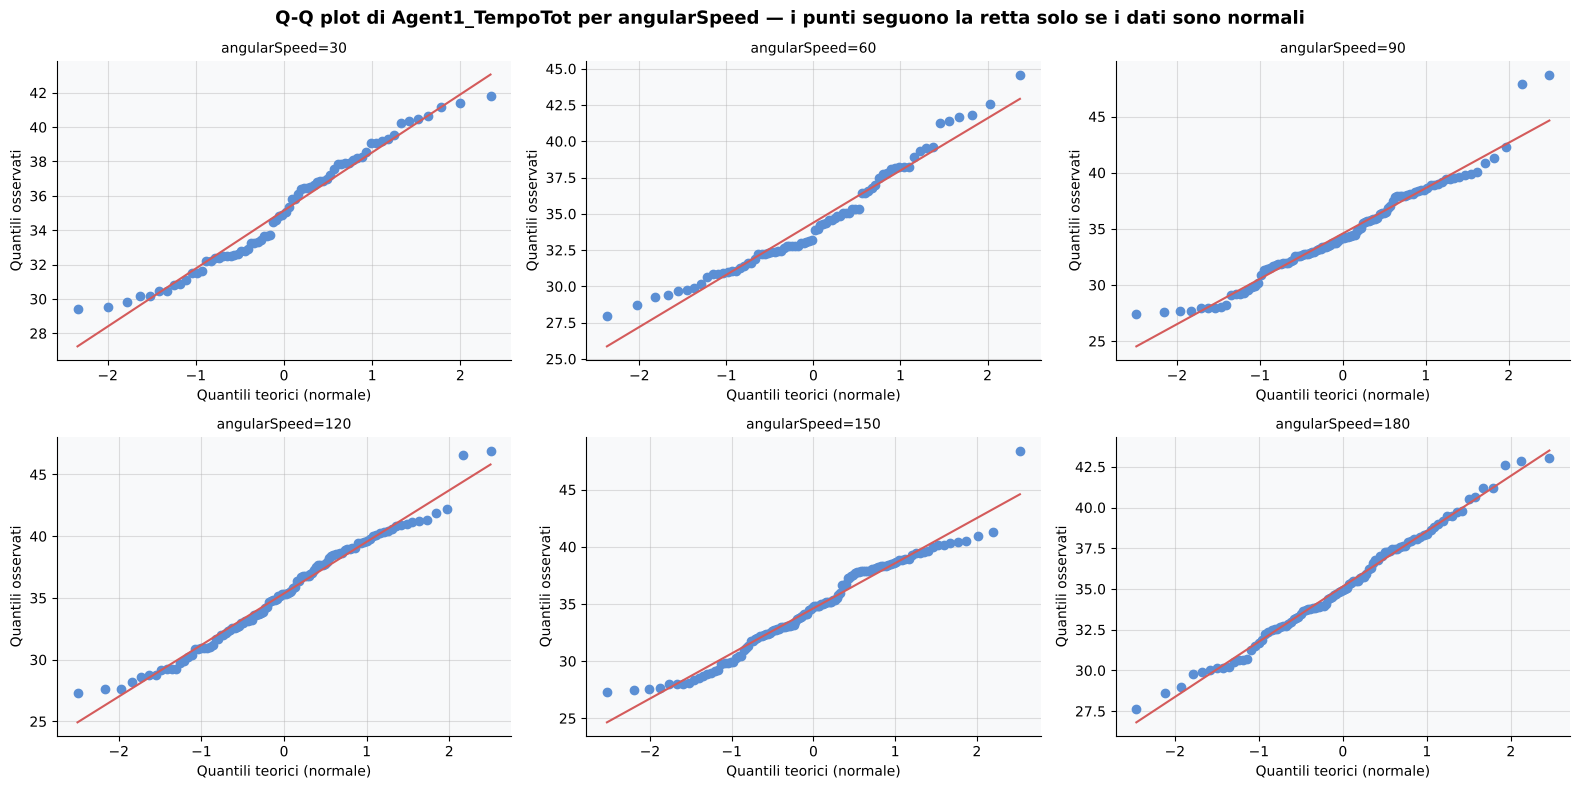

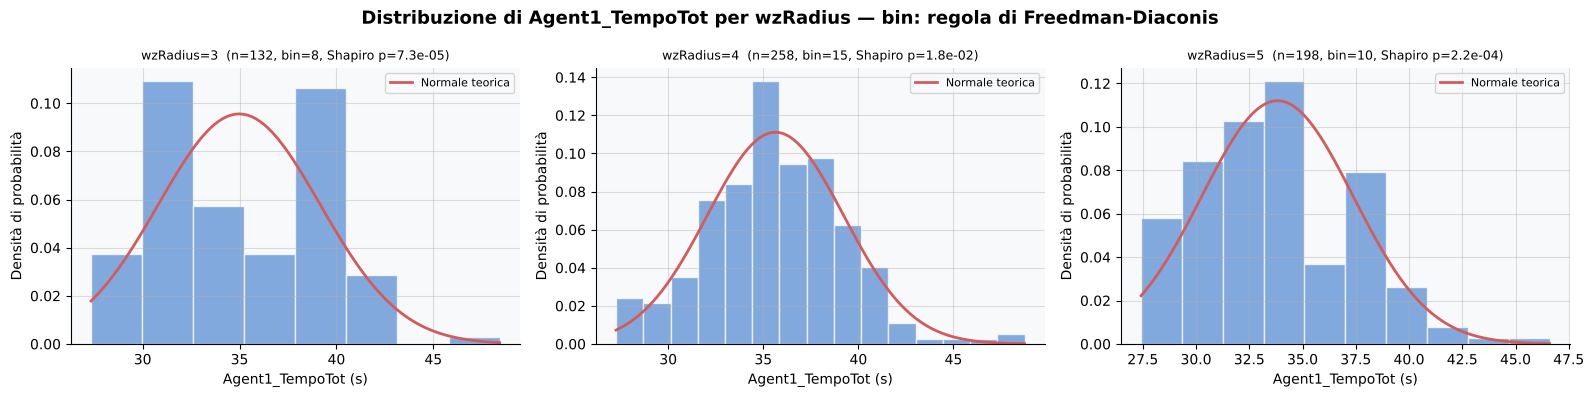

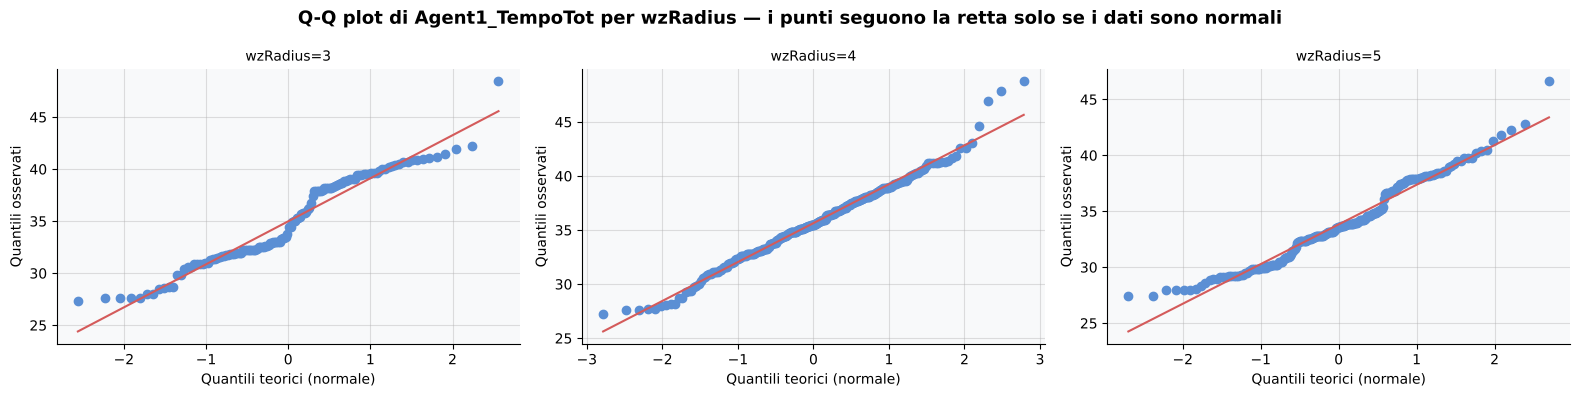

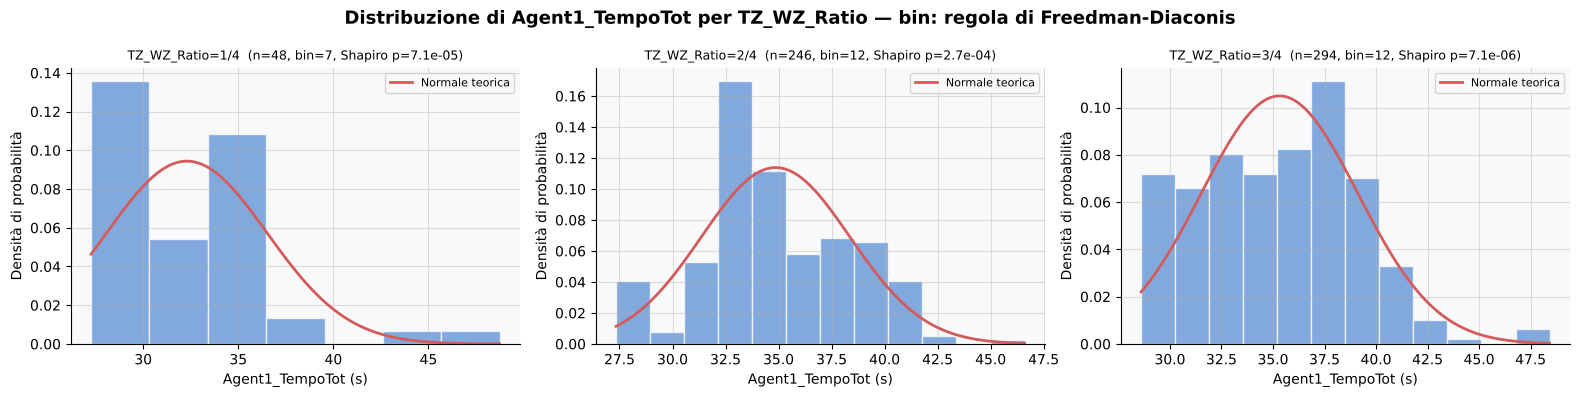

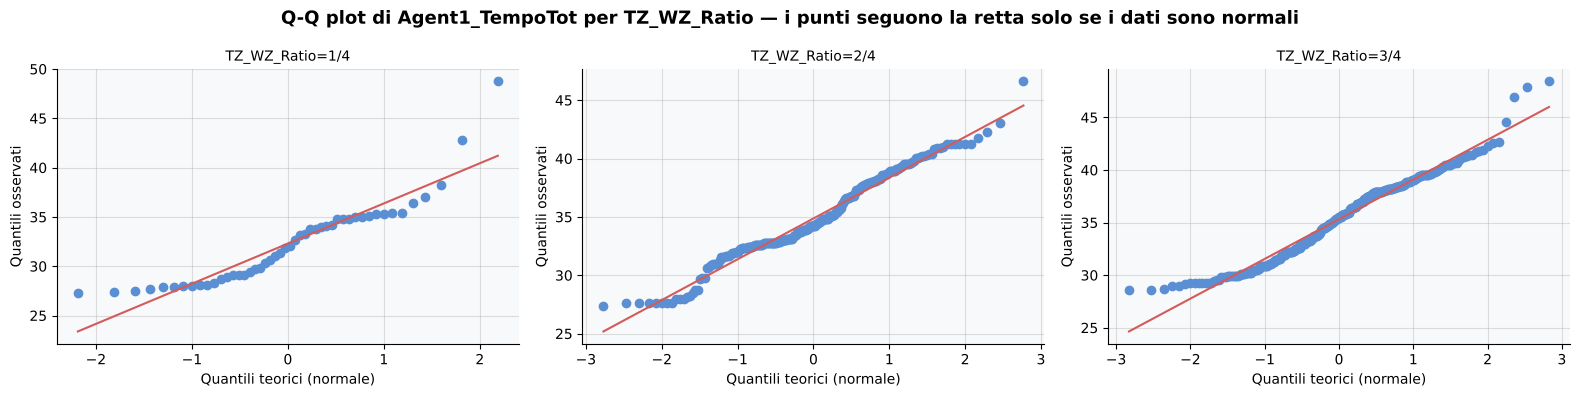

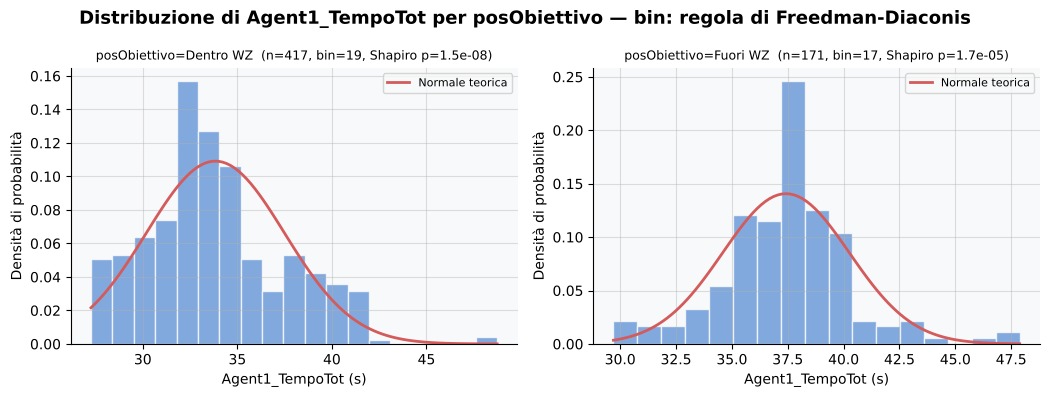

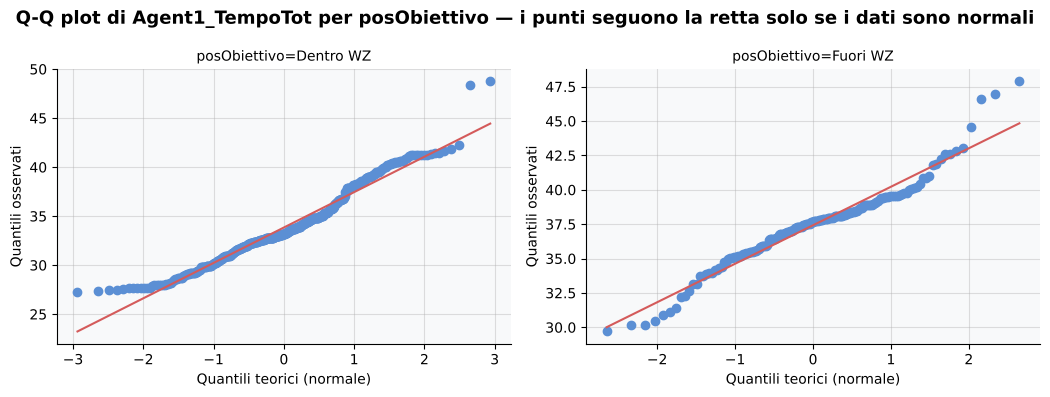

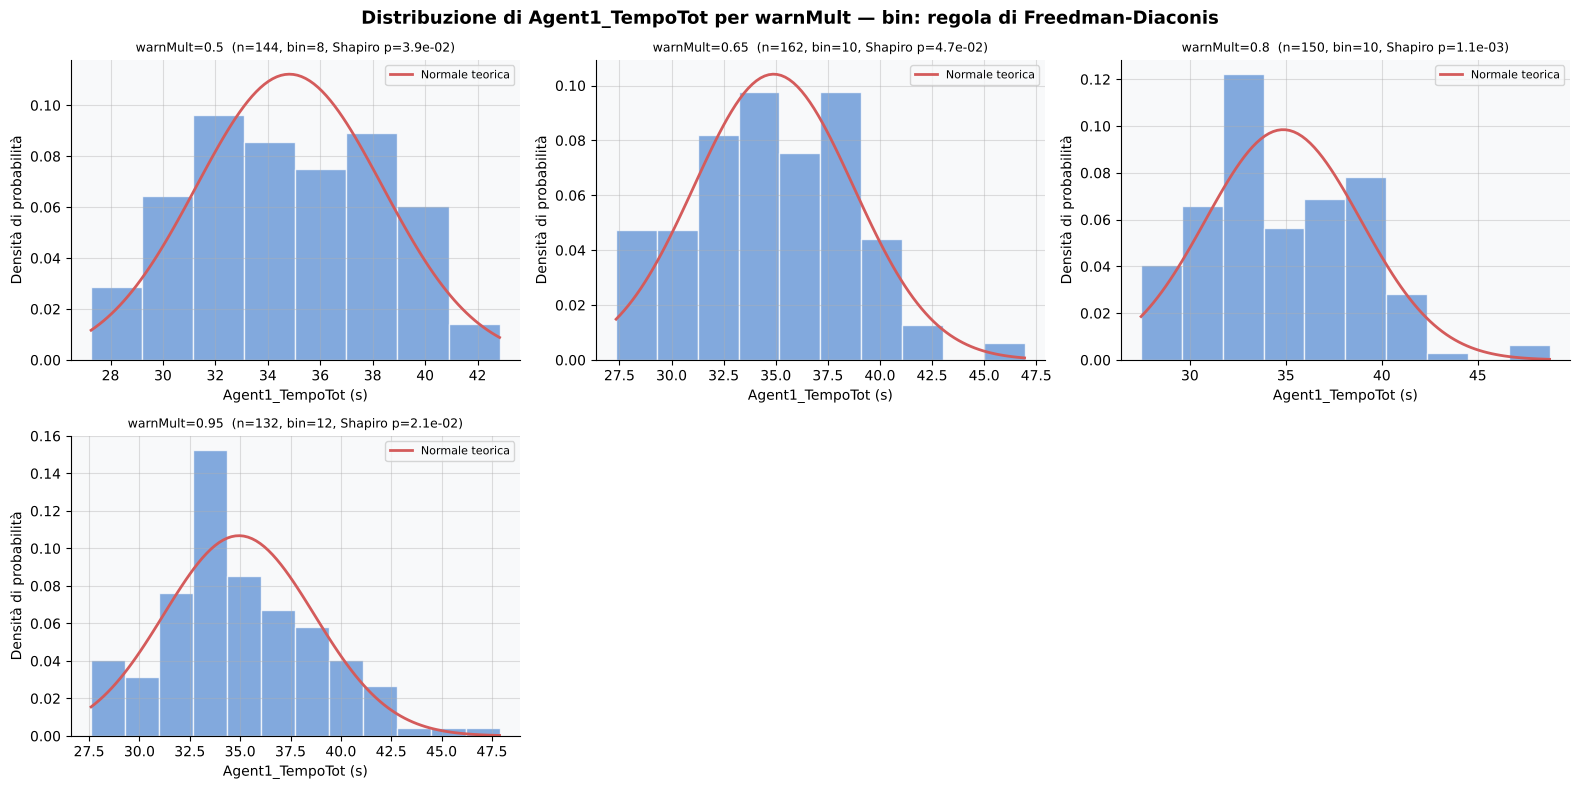

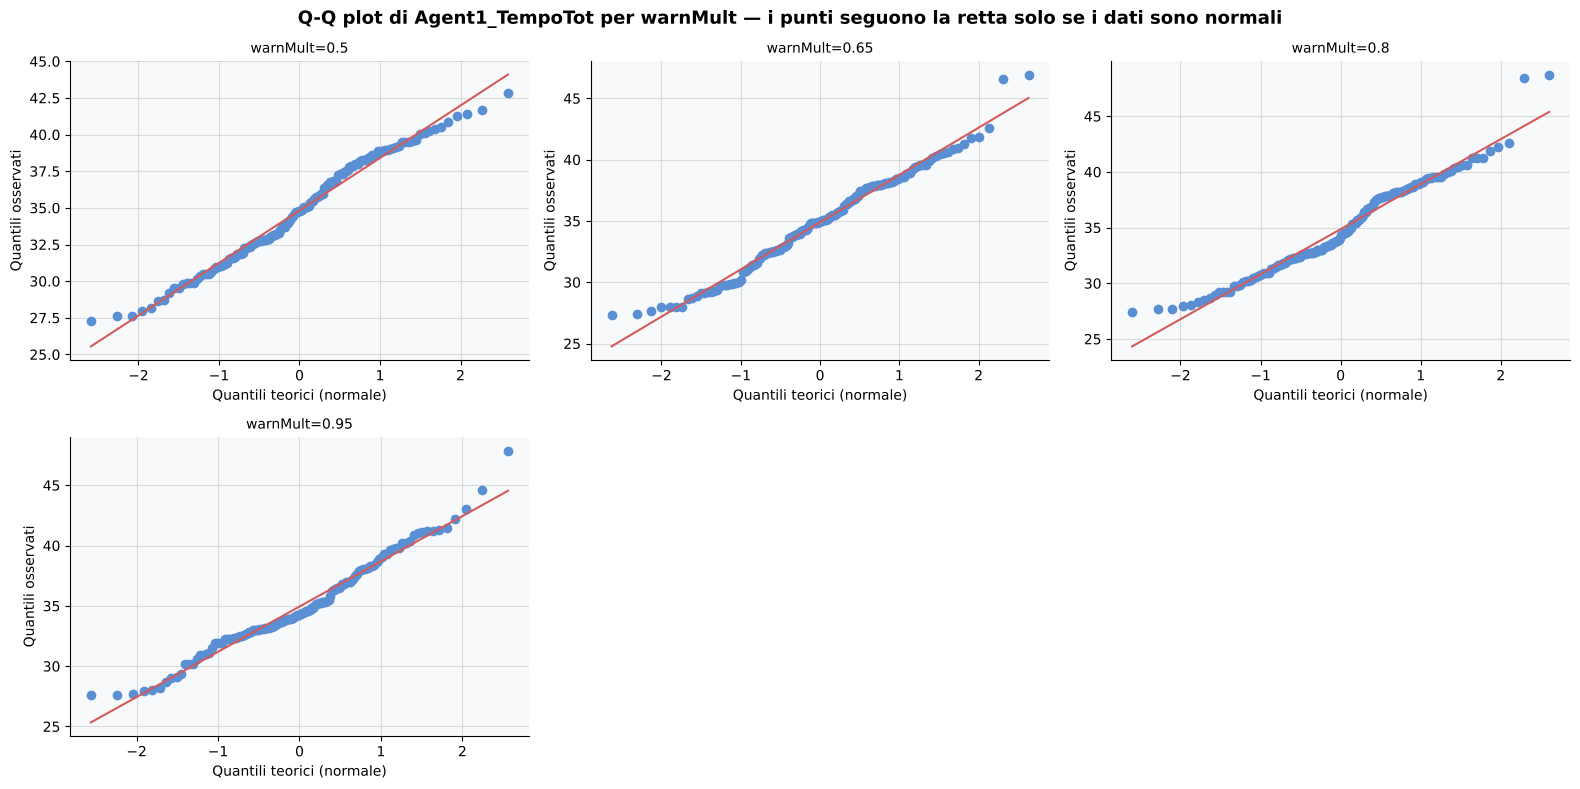

In [30]:
# Istogrammi (con curva normale teorica) e Q-Q plot per tutti i parametri.
# Numero di bin calcolato per ciascun gruppo con la regola di Freedman-Diaconis

from scipy.stats import probplot

for p in parametri_da_verificare:
    levels = sorted(stage0[p].unique())
    n = len(levels)
    ncols = min(n, 3)
    nrows = -(-n // ncols)  # ceil division

    # Istogrammi
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.3*ncols, 4*nrows), squeeze=False)
    fig.suptitle(f'Distribuzione di Agent1_TempoTot per {p} — bin: regola di Freedman-Diaconis',
                 fontsize=13, fontweight='bold')
    for i, lvl in enumerate(levels):
        ax = axes.flat[i]
        data = stage0[stage0[p] == lvl]['Agent1_TempoTot'].values

        # Numero di bin robusto, calcolato sul gruppo specifico (non fisso per tutti)
        bin_edges = np.histogram_bin_edges(data, bins='fd')
        n_bins = len(bin_edges) - 1

        ax.hist(data, bins=bin_edges, density=True, color='#5B8FD4', alpha=0.75, edgecolor='white')

        mu, sigma = data.mean(), data.std()
        x = np.linspace(data.min(), data.max(), 100)
        ax.plot(x, (1/(sigma*np.sqrt(2*np.pi)))*np.exp(-0.5*((x-mu)/sigma)**2),
                color='#D45B5B', linewidth=2, label='Normale teorica')

        stat, pv = shapiro(data)
        ax.set_title(f"{p}={lvl}  (n={len(data)}, bin={n_bins}, Shapiro p={pv:.1e})", fontsize=9)
        ax.set_xlabel('Agent1_TempoTot (s)')
        ax.set_ylabel('Densità di probabilità')
        ax.legend(fontsize=8)
    for j in range(n, nrows*ncols):
        axes.flat[j].set_visible(False)
    plt.tight_layout()
    plt.savefig(f'27_istogrammi_{p}.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Q-Q plot
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.3*ncols, 4*nrows), squeeze=False)
    fig.suptitle(f'Q-Q plot di Agent1_TempoTot per {p} — i punti seguono la retta solo se i dati sono normali',
                 fontsize=13, fontweight='bold')
    for i, lvl in enumerate(levels):
        ax = axes.flat[i]
        data = stage0[stage0[p] == lvl]['Agent1_TempoTot']
        probplot(data, dist="norm", plot=ax)
        ax.set_title(f"{p}={lvl}", fontsize=10)
        ax.set_xlabel('Quantili teorici (normale)')
        ax.set_ylabel('Quantili osservati')
        ax.get_lines()[0].set_markerfacecolor('#5B8FD4')
        ax.get_lines()[0].set_markeredgecolor('#5B8FD4')
        ax.get_lines()[1].set_color('#D45B5B')
    for j in range(n, nrows*ncols):
        axes.flat[j].set_visible(False)
    plt.tight_layout()
    plt.savefig(f'27_qqplot_{p}.png', dpi=150, bbox_inches='tight')
    plt.show()

### 💬 Lettura
Su tutti e 5 i parametri la maggior parte dei gruppi non è normale (Shapiro-Wilk p<0.05: 16 gruppi su 18): questo esclude l'ANOVA classica e conferma la scelta di Kruskal-Wallis. Le varianze sono disomogenee (Levene, p<0.05) per `posObiettivo` e `wzRadius`; `TZ_WZ_Ratio` (p=0.08), `angularSpeed` (p=0.18) e `warnMult` (p=0.33) risultano omoschedastici. I risultati vengono confermati più avanti (Sez. 31) anche con il test di Welch, robusto a varianze disomogenee.

### 💬 Lettura
Gli istogrammi (asse X: TempoTot in secondi; asse Y: densità di probabilità, non conteggio grezzo, per essere confrontabile con la curva normale teorica) mostrano asimmetrie a destra per la maggior parte dei gruppi, con numero di bin calcolato singolarmente per ciascun gruppo (Freedman-Diaconis, robusto a dati non normali). I Q-Q plot confermano lo stesso quadro in modo più sensibile: gli scostamenti dalla retta rossa nelle code indicano deviazioni dalla normalità che l'istogramma da solo può non evidenziare altrettanto chiaramente.

## 28. Ranking dei parametri per rilevanza (effect size)

In [31]:
# Quale parametro incide di più sulla performance complessiva?
# Ranking per effect size (epsilon²) su TempoTot — determina l'ordine dei filtri

def epsilon_squared(h, n):
    return h / (n - 1)

metrica = 'Agent1_TempoTot'  # NavMesh è già fisso a 100% dopo il criterio di affidabilità, non discrimina più
n = len(stage0)

print(f"Ranking parametri per effect size su {metrica} (n={n}, combinazioni affidabili)\n")

ranking = []
for p in ['angularSpeed', 'TZ_WZ_Ratio', 'wzRadius', 'warnMult', 'posObiettivo']:
    groups = [g[metrica].values for _, g in stage0.groupby(p)]
    if len(groups) < 2:
        continue
    h, pval = kruskal(*groups)
    ranking.append((p, h, pval, epsilon_squared(h, n)))

ranking_df = pd.DataFrame(ranking, columns=['parametro','H','p_value','epsilon_squared'])
ranking_df = ranking_df.sort_values('epsilon_squared', ascending=False).reset_index(drop=True)
display(ranking_df.round(4))

print("\nOrdine di filtro consigliato (dal più al meno influente):")
print(' -> '.join(ranking_df['parametro'].tolist()))

Ranking parametri per effect size su Agent1_TempoTot (n=588, combinazioni affidabili)



,parametro,H,p_value,epsilon_squared
0,posObiettivo,117.5102,0.0000,0.2002
1,wzRadius,27.5627,0.0000,0.0470
2,TZ_WZ_Ratio,25.2759,0.0000,0.0431
3,angularSpeed,5.9215,0.3139,0.0101
4,warnMult,0.1471,0.9856,0.0003



Ordine di filtro consigliato (dal più al meno influente):
posObiettivo -> wzRadius -> TZ_WZ_Ratio -> angularSpeed -> warnMult


### 💬 Lettura
`posObiettivo` domina nettamente (ε²≈0.20, più di 4 volte il secondo), seguito da `wzRadius` e dal rapporto TZ/WZ, con effetti piccoli e quasi uguali tra loro (ε²≈0.047 e 0.043). `angularSpeed` e `warnMult` risultano **non significativi** sulle combinazioni affidabili: il loro effetto osservato nell'analisi descrittiva era in realtà legato quasi interamente alla soglia di affidabilità, non a un miglioramento continuo oltre quella soglia. Per questo non vengono usati nel filtro sequenziale.

## 29. Filtro sequenziale data-driven

In [32]:
# Sequenza di filtri, ordine determinato dal ranking epsilon² (Sez. 28)

print(f"Combinazioni affidabili: {len(stage0)} righe\n")

stage1 = filtro_sequenziale(stage0, 'posObiettivo', 'Agent1_TempoTot',
                             direction='min', label='1. posObiettivo (effetto dominante)')
stage2 = filtro_sequenziale(stage1, 'wzRadius', 'Agent1_TempoTot',
                             direction='min', label='2. wzRadius')
stage3 = filtro_sequenziale(stage2, 'TZ_WZ_Ratio', 'Agent1_TempoTot',
                             direction='min', label='3. Rapporto TZ/WZ')
# angularSpeed e warnMult non hanno effetto significativo (Sez. 28): non filtrati.

final_survivors = (stage3.groupby(['angularSpeed','wzRadius','tzRadius','TZ_WZ_Ratio','warnMult','posObiettivo'])
                    .agg(n=('Agent1_NavMesh','size'),
                         NavMesh_pct=('Agent1_NavMesh', lambda x: x.mean()*100),
                         TempoTot=('Agent1_TempoTot','mean'),
                         TempoTot_std=('Agent1_TempoTot','std'))
                    .reset_index()
                    .sort_values('TempoTot'))

# Tutte le combinazioni hanno n=3 per costruzione (criterio di affidabilità, Sez. 26):
# il controllo qui sotto è solo una verifica.
reliable = final_survivors[final_survivors['n'] >= 3].copy()
reliable = reliable.sort_values(['TempoTot', 'TempoTot_std'])

print(f"Configurazioni sopravvissute ai filtri statistici: {len(final_survivors)}")
print(f"di cui con tre ripetizioni (verifica): {len(reliable)}\n")
display(reliable.round(3))

Combinazioni affidabili: 588 righe

--- Filtro: 1. posObiettivo (effetto dominante) (su Agent1_TempoTot) ---
Kruskal-Wallis: H=117.51  p=2.22e-27  (effetto significativo)
  Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=33.84)
  Livelli statisticamente equivalenti (p>0.05): ['Dentro WZ']
  Righe: 588 -> 417

--- Filtro: 2. wzRadius (su Agent1_TempoTot) ---
Kruskal-Wallis: H=19.14  p=6.99e-05  (effetto significativo)
  Livello migliore: wzRadius=5 (Agent1_TempoTot min=32.73)
  Livelli statisticamente equivalenti (p>0.05): [5]
  Righe: 417 -> 141

--- Filtro: 3. Rapporto TZ/WZ (su Agent1_TempoTot) ---
Kruskal-Wallis: H=42.14  p=7.08e-10  (effetto significativo)
  Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=30.86)
  Livelli statisticamente equivalenti (p>0.05): ['1/4', '3/4']
  Righe: 141 -> 75

Configurazioni sopravvissute ai filtri statistici: 25
di cui con tre ripetizioni (verifica): 25



,angularSpeed,wzRadius,tzRadius,TZ_WZ_Ratio,warnMult,posObiettivo,n,NavMesh_pct,TempoTot,TempoTot_std
17,150,5,1.25,1/4,0.65,Dentro WZ,3,100.0,28.667,0.590
18,150,5,1.25,1/4,0.80,Dentro WZ,3,100.0,29.200,2.294
9,90,5,3.75,3/4,0.65,Dentro WZ,3,100.0,29.453,0.370
15,120,5,3.75,3/4,0.80,Dentro WZ,3,100.0,29.780,0.918
19,150,5,3.75,3/4,0.50,Dentro WZ,3,100.0,29.853,0.631
7,90,5,1.25,1/4,0.95,Dentro WZ,3,100.0,29.913,2.468
0,30,5,3.75,3/4,0.50,Dentro WZ,3,100.0,29.940,0.478
6,90,5,1.25,1/4,0.80,Dentro WZ,3,100.0,30.013,3.505
5,90,5,1.25,1/4,0.65,Dentro WZ,3,100.0,30.353,3.209
22,180,5,3.75,3/4,0.50,Dentro WZ,3,100.0,30.360,2.010


## 30. Verifica finale di equivalenza statistica

In [33]:
# Le top-N configurazioni superstiti sono davvero diverse tra loro?

reliable['combo'] = (reliable['angularSpeed'].astype(str) + '_' + reliable['wzRadius'].astype(str) + '_' +
                      reliable['tzRadius'].astype(str) + '_' + reliable['warnMult'].astype(str) + '_' +
                      reliable['posObiettivo'])

top_combos = reliable.head(8)['combo'].tolist()
sub_final = stage3.copy()
sub_final['combo'] = (sub_final['angularSpeed'].astype(str) + '_' + sub_final['wzRadius'].astype(str) + '_' +
                       sub_final['tzRadius'].astype(str) + '_' + sub_final['warnMult'].astype(str) + '_' +
                       sub_final['posObiettivo'])
sub_final = sub_final[sub_final['combo'].isin(top_combos)]

h_top8, p_top8 = kruskal(*[g['Agent1_TempoTot'].values for _, g in sub_final.groupby('combo')])
print(f"Kruskal-Wallis tra le top-8 configurazioni: H={h_top8:.2f}, p={p_top8:.4f}")

if p_top8 < 0.05:
    dunn_final = sp.posthoc_dunn(sub_final, val_col='Agent1_TempoTot', group_col='combo', p_adjust='bonferroni')
    best = top_combos[0]
    equiv = dunn_final[best][dunn_final[best] > 0.05].index.tolist()
    print(f"\nMigliore: {best}")
    print(f"Equivalenti statisticamente alla migliore: {equiv}")
else:
    print("\nNessuna differenza significativa tra le top-8: sono TUTTE statisticamente equivalenti.")
    print("La scelta finale va su criterio pratico esplicito (TempoTot e std più bassi).")

Kruskal-Wallis tra le top-8 configurazioni: H=5.43, p=0.6076

Nessuna differenza significativa tra le top-8: sono TUTTE statisticamente equivalenti.
La scelta finale va su criterio pratico esplicito (TempoTot e std più bassi).


## 31. Conferma incrociata: Welch ANOVA (robusta a varianze disomogenee)

In [34]:
# Dato che Levene (Sez.27) indica varianze disomogenee, confermo i
# risultati principali con Welch ANOVA, robusto a questa violazione.

for p in ['posObiettivo', 'wzRadius', 'TZ_WZ_Ratio', 'angularSpeed', 'warnMult']:
    res = pg.welch_anova(data=stage0, dv='Agent1_TempoTot', between=p)
    h, p_kw = kruskal(*[g['Agent1_TempoTot'].values for _, g in stage0.groupby(p)])
    print(f"--- Welch ANOVA: {p} (su Agent1_TempoTot) ---")
    display(res)
    print(f"Kruskal-Wallis: H={h:.2f}, p={p_kw:.2e}  |  Welch p={res['p_unc'].values[0]:.2e}  |  "
          f"Concordanza: {'SI' if (res['p_unc'].values[0]<0.05) == (p_kw<0.05) else 'NO'}\n")

--- Welch ANOVA: posObiettivo (su Agent1_TempoTot) ---


,Source,ddof1,ddof2,F,p_unc,np2
0,posObiettivo,1,403.080176,161.613164,2.281718e-31,0.183108


Kruskal-Wallis: H=117.51, p=2.22e-27  |  Welch p=2.28e-31  |  Concordanza: SI

--- Welch ANOVA: wzRadius (su Agent1_TempoTot) ---


,Source,ddof1,ddof2,F,p_unc,np2
0,wzRadius,2,317.956116,14.429001,0.000001,0.043637


Kruskal-Wallis: H=27.56, p=1.03e-06  |  Welch p=1.00e-06  |  Concordanza: SI

--- Welch ANOVA: TZ_WZ_Ratio (su Agent1_TempoTot) ---


...

Kruskal-Wallis: H=25.28, p=3.25e-06  |  Welch p=5.28e-05  |  Concordanza: SI

--- Welch ANOVA: angularSpeed (su Agent1_TempoTot) ---


,Source,ddof1,ddof2,F,p_unc,np2
0,angularSpeed,5,260.604749,1.018269,0.407258,0.008786


Kruskal-Wallis: H=5.92, p=3.14e-01  |  Welch p=4.07e-01  |  Concordanza: SI

--- Welch ANOVA: warnMult (su Agent1_TempoTot) ---


,Source,ddof1,ddof2,F,p_unc,np2
0,warnMult,3,321.712791,0.025996,0.994329,0.000125


Kruskal-Wallis: H=0.15, p=9.86e-01  |  Welch p=9.94e-01  |  Concordanza: SI



### 💬 Lettura
Kruskal-Wallis e Welch ANOVA concordano sulla significatività di `posObiettivo`, `wzRadius` e `TZ_WZ_Ratio` (tutti p<0.001 in entrambi i test) e sulla non significatività di `angularSpeed` e `warnMult`: i risultati non dipendono da quale assunzione statistica (normalità vs omoschedasticità) si sta rilassando. Anche le dimensioni dell'effetto sono molto vicine; l'unica differenza è che con Welch `wzRadius` e `TZ_WZ_Ratio` hanno effetti praticamente uguali (η²≈0.044 entrambi), mentre con Kruskal-Wallis il raggio è di poco più grande.

## 31-bis. Verifica: criterio di affidabilità meno severo e ordine dei passi

Nella prima versione dell'analisi il criterio guardava solo le ripetizioni valide: una combinazione restava anche con una o due ripetizioni, purché in tutte il NavMesh si fosse attivato per entrambi gli artefatti (`stage0_meno_severo`). Ripetiamo ranking e filtro sequenziale con quel criterio, per verificare che la scelta del criterio non cambi i risultati. Poi, dato che `wzRadius` e `TZ_WZ_Ratio` hanno ε² molto vicini, verifichiamo cosa succede invertendo i due passi del filtro.

In [35]:
# (1) Criterio meno severo: ranking e filtro sequenziale
n_ms = len(stage0_meno_severo)
print(f"Criterio meno severo: {n_ms} righe\n")
rk = []
for p in ['posObiettivo', 'wzRadius', 'TZ_WZ_Ratio', 'angularSpeed', 'warnMult']:
    h, pv = kruskal(*[g['Agent1_TempoTot'].values for _, g in stage0_meno_severo.groupby(p)])
    rk.append((p, h, pv, epsilon_squared(h, n_ms)))
display(pd.DataFrame(rk, columns=['parametro', 'H', 'p_value', 'epsilon_squared'])
        .sort_values('epsilon_squared', ascending=False).round(4))

ms1 = filtro_sequenziale(stage0_meno_severo, 'posObiettivo', 'Agent1_TempoTot', direction='min', label='1. posObiettivo')
ms2 = filtro_sequenziale(ms1, 'wzRadius', 'Agent1_TempoTot', direction='min', label='2. wzRadius')
ms3 = filtro_sequenziale(ms2, 'TZ_WZ_Ratio', 'Agent1_TempoTot', direction='min', label='3. Rapporto TZ/WZ')
ms_conf = ms3.groupby(CHIAVI)['Agent1_TempoTot'].agg(['size', 'mean']).reset_index()
ms_tre = ms_conf[ms_conf['size'] == 3]
print(f"Configurazioni dopo il filtro: {len(ms_conf)}, di cui con tre ripetizioni: {len(ms_tre)}")
stesse = set(map(tuple, ms_tre[CHIAVI].values)) == set(map(tuple, reliable[CHIAVI].values))
print(f"Le configurazioni con tre ripetizioni coincidono con le {len(reliable)} del criterio di affidabilità: {stesse}\n")

# (2) Rapporti 1/4 e 3/4 dopo il passo su wzRadius: Dunn (con e senza Bonferroni) e Mann-Whitney
from scipy.stats import mannwhitneyu
for nome, d in [('criterio di affidabilità', stage2), ('criterio meno severo', ms2)]:
    a = d[d['TZ_WZ_Ratio'] == '1/4']['Agent1_TempoTot']
    b = d[d['TZ_WZ_Ratio'] == '3/4']['Agent1_TempoTot']
    dn_b = sp.posthoc_dunn(d, val_col='Agent1_TempoTot', group_col='TZ_WZ_Ratio', p_adjust='bonferroni')
    dn_u = sp.posthoc_dunn(d, val_col='Agent1_TempoTot', group_col='TZ_WZ_Ratio')
    print(f"{nome}: 1/4 (n={len(a)}, media {a.mean():.2f}) vs 3/4 (n={len(b)}, media {b.mean():.2f}) | "
          f"Dunn p={dn_b.loc['1/4','3/4']:.3f} (senza correzione {dn_u.loc['1/4','3/4']:.3f}) | "
          f"Mann-Whitney p={mannwhitneyu(a, b)[1]:.3f}")

# (3) Ordine invertito: rapporto TZ/WZ prima di wzRadius
print("\n--- Ordine invertito ---")
inv1 = filtro_sequenziale(stage0, 'posObiettivo', 'Agent1_TempoTot', direction='min', label='1. posObiettivo')
inv2 = filtro_sequenziale(inv1, 'TZ_WZ_Ratio', 'Agent1_TempoTot', direction='min', label='2. Rapporto TZ/WZ')
inv3 = filtro_sequenziale(inv2, 'wzRadius', 'Agent1_TempoTot', direction='min', label='3. wzRadius')
inv_conf = (inv3.groupby(CHIAVI)['Agent1_TempoTot'].agg(['size', 'mean', 'std'])
            .reset_index().sort_values('mean'))
print(f"Configurazioni rimaste con l'ordine invertito: {len(inv_conf)}")
display(inv_conf.head(5).round(2))

Criterio meno severo: 723 righe



,parametro,H,p_value,epsilon_squared
0,posObiettivo,135.9709,0.0000,0.1883
1,wzRadius,32.4938,0.0000,0.0450
2,TZ_WZ_Ratio,17.2730,0.0002,0.0239
3,angularSpeed,6.8495,0.2321,0.0095
4,warnMult,0.5902,0.8987,0.0008


--- Filtro: 1. posObiettivo (su Agent1_TempoTot) ---
Kruskal-Wallis: H=135.97  p=2.02e-31  (effetto significativo)


  Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=33.61)
  Livelli statisticamente equivalenti (p>0.05): ['Dentro WZ']
  Righe: 723 -> 475

--- Filtro: 2. wzRadius (su Agent1_TempoTot) ---
Kruskal-Wallis: H=22.04  p=1.64e-05  (effetto significativo)
  Livello migliore: wzRadius=5 (Agent1_TempoTot min=32.55)
  Livelli statisticamente equivalenti (p>0.05): [5]
  Righe: 475 -> 175

--- Filtro: 3. Rapporto TZ/WZ (su Agent1_TempoTot) ---
Kruskal-Wallis: H=44.57  p=2.09e-10  (effetto significativo)


  Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=30.89)
  Livelli statisticamente equivalenti (p>0.05): ['1/4', '3/4']
  Righe: 175 -> 107

Configurazioni dopo il filtro: 43, di cui con tre ripetizioni: 25
Le configurazioni con tre ripetizioni coincidono con le 25 del criterio di affidabilità: True



criterio di affidabilità: 1/4 (n=24, media 30.86) vs 3/4 (n=51, media 31.40) | Dunn p=1.000 (senza correzione 0.589) | Mann-Whitney p=0.110
criterio meno severo: 1/4 (n=43, media 30.89) vs 3/4 (n=64, media 31.60) | Dunn p=0.693 (senza correzione 0.231) | Mann-Whitney p=0.024

--- Ordine invertito ---
--- Filtro: 1. posObiettivo (su Agent1_TempoTot) ---
Kruskal-Wallis: H=117.51  p=2.22e-27  (effetto significativo)
  Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=33.84)
  Livelli statisticamente equivalenti (p>0.05): ['Dentro WZ']
  Righe: 588 -> 417

--- Filtro: 2. Rapporto TZ/WZ (su Agent1_TempoTot) ---
Kruskal-Wallis: H=15.88  p=3.56e-04  (effetto significativo)
  Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=31.76)
  Livelli statisticamente equivalenti (p>0.05): ['1/4']
  Righe: 417 -> 42

--- Filtro: 3. wzRadius (su Agent1_TempoTot) ---
Kruskal-Wallis: H=2.17  p=1.40e-01  (NESSUN effetto significativo -> filtro non applicato)
  -> wzRadius non discrimina: nes

,angularSpeed,wzRadius,tzRadius,warnMult,posObiettivo,size,mean,std
11,150,5,1.25,0.65,Dentro WZ,3,28.67,0.59
12,150,5,1.25,0.80,Dentro WZ,3,29.20,2.29
5,90,5,1.25,0.95,Dentro WZ,3,29.91,2.47
10,150,4,1.00,0.95,Dentro WZ,3,29.95,3.63
4,90,5,1.25,0.80,Dentro WZ,3,30.01,3.51


### 💬 Lettura
Con il criterio meno severo (278 combinazioni, 723 righe) ranking, parametri significativi e livelli tenuti dal filtro sequenziale sono gli stessi, e le 25 configurazioni finali con tre ripetizioni coincidono. Il confronto diretto tra i rapporti 1/4 e 3/4 cambia invece: con il criterio meno severo il Mann-Whitney trovava una differenza (p=0.024), con il criterio di affidabilità no (p=0.11), con medie molto vicine (30.86 contro 31.40 s) e meno simulazioni. Invertendo l'ordine tra rapporto TZ/WZ e wzRadius, che hanno ε² quasi uguali, il filtro tiene solo il rapporto 1/4 e wzRadius non è più significativo: restano 14 configurazioni, ma la più rapida è ancora quella scelta.

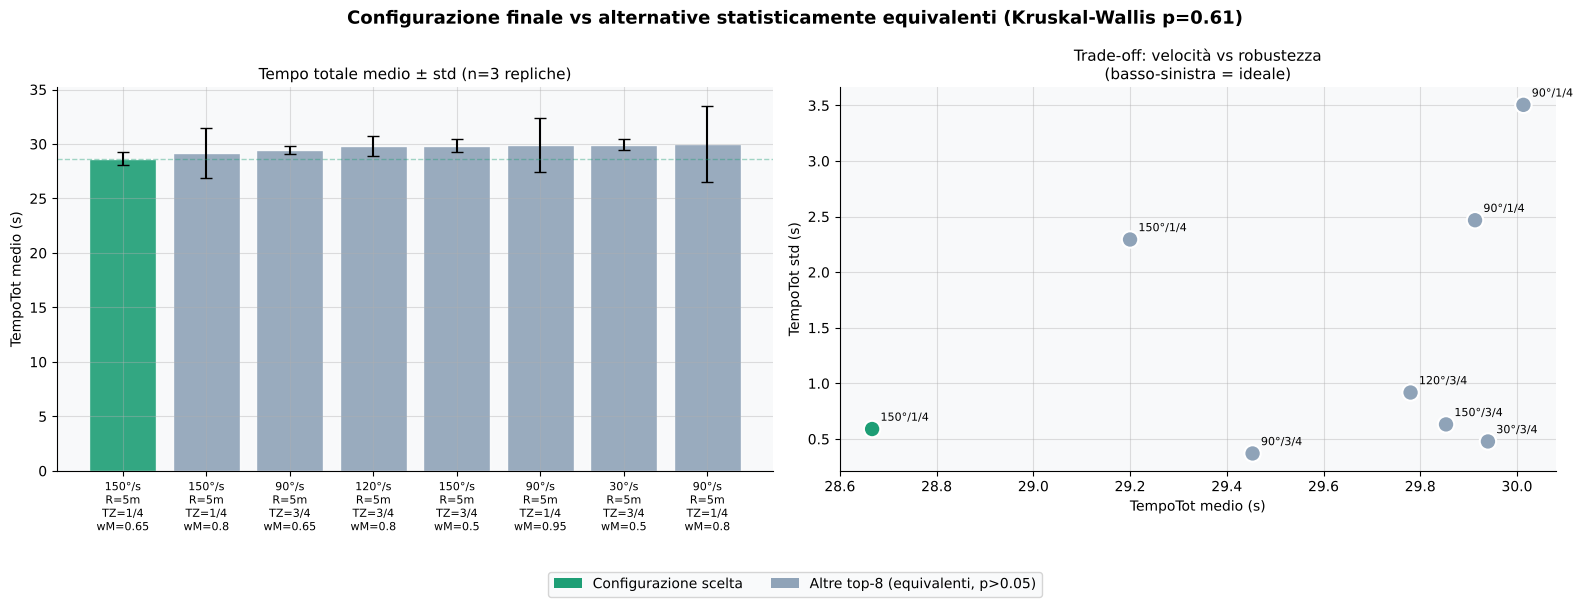


Configurazione scelta: angularSpeed=150°/s, wzRadius=5m, tzRadius=1.25m (1/4), warnMult=0.65, Dentro WZ
TempoTot = 28.67s ± 0.59s
Nessuna differenza statisticamente significativa rispetto alle altre 7 alternative (Kruskal-Wallis p=0.61)


In [36]:
# Grafico finale: configurazione scelta vs top-8 equivalenti

import matplotlib.pyplot as plt
import numpy as np

top8 = reliable.head(8).copy().reset_index(drop=True)
top8['label'] = top8.apply(
    lambda r: f"{int(r['angularSpeed'])}°/s\nR={r['wzRadius']}m\nTZ={r['TZ_WZ_Ratio']}\nwM={r['warnMult']}",
    axis=1
)

chosen_idx = top8.index[
    (top8['angularSpeed'] == 150) & (top8['wzRadius'] == 5) &
    (top8['tzRadius'] == 1.25) & (top8['warnMult'] == 0.65)
][0]

colors = ['#1D9E75' if i == chosen_idx else '#8FA3B8' for i in range(len(top8))]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle(f'Configurazione finale vs alternative statisticamente equivalenti (Kruskal-Wallis p={p_top8:.2f})',
             fontsize=13, fontweight='bold')

# --- Grafico 1: TempoTot medio con barre di errore (std) ---
axes[0].bar(range(len(top8)), top8['TempoTot'], yerr=top8['TempoTot_std'],
            color=colors, edgecolor='white', capsize=4, alpha=0.9)
axes[0].set_xticks(range(len(top8)))
axes[0].set_xticklabels(top8['label'], fontsize=8)
axes[0].set_ylabel('TempoTot medio (s)')
axes[0].set_title('Tempo totale medio ± std (n=3 repliche)', fontsize=11)
axes[0].axhline(top8.loc[chosen_idx, 'TempoTot'], color='#1D9E75', linestyle='--', alpha=0.4, linewidth=1)

# --- Grafico 2: scatter TempoTot vs std (robustezza) ---
axes[1].scatter(top8['TempoTot'], top8['TempoTot_std'], s=140, c=colors,
                 edgecolor='white', linewidth=1.5, zorder=3)
for i, row in top8.iterrows():
    axes[1].annotate(f"{int(row['angularSpeed'])}°/{row['TZ_WZ_Ratio']}",
                      (row['TempoTot'], row['TempoTot_std']),
                      textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set_xlabel('TempoTot medio (s)')
axes[1].set_ylabel('TempoTot std (s)')
axes[1].set_title('Trade-off: velocità vs robustezza\n(basso-sinistra = ideale)', fontsize=11)

legend_elems = [Patch(facecolor='#1D9E75', label='Configurazione scelta'),
                Patch(facecolor='#8FA3B8', label='Altre top-8 (equivalenti, p>0.05)')]
fig.legend(handles=legend_elems, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.savefig('29_configurazione_finale.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nConfigurazione scelta: angularSpeed=150°/s, wzRadius=5m, tzRadius=1.25m (1/4), warnMult=0.65, Dentro WZ")
print(f"TempoTot = {top8.loc[chosen_idx,'TempoTot']:.2f}s ± {top8.loc[chosen_idx,'TempoTot_std']:.2f}s")
print(f"Nessuna differenza statisticamente significativa rispetto alle altre {len(top8)-1} alternative (Kruskal-Wallis p={p_top8:.2f})")

In [37]:
# Le top-N configurazioni superstiti sono davvero diverse tra loro?

reliable['combo'] = (reliable['angularSpeed'].astype(str) + '_' + reliable['wzRadius'].astype(str) + '_' +
                      reliable['tzRadius'].astype(str) + '_' + reliable['warnMult'].astype(str) + '_' +
                      reliable['posObiettivo'])

top_combos = reliable['combo'].tolist()
sub_final = stage3.copy()
sub_final['combo'] = (sub_final['angularSpeed'].astype(str) + '_' + sub_final['wzRadius'].astype(str) + '_' +
                       sub_final['tzRadius'].astype(str) + '_' + sub_final['warnMult'].astype(str) + '_' +
                       sub_final['posObiettivo'])
sub_final = sub_final[sub_final['combo'].isin(top_combos)]

h_all, p_all = kruskal(*[g['Agent1_TempoTot'].values for _, g in sub_final.groupby('combo')])
print(f"Kruskal-Wallis tra le top-{len(top_combos)} configurazioni: H={h_all:.2f}, p={p_all:.4f}")

if p_all < 0.05:
    dunn_final = sp.posthoc_dunn(sub_final, val_col='Agent1_TempoTot', group_col='combo', p_adjust='bonferroni')
    best = top_combos[0]
    equiv = dunn_final[best][dunn_final[best] > 0.05].index.tolist()
    print(f"\nMigliore: {best}")
    print(f"Equivalenti statisticamente alla migliore: {equiv}")
else:
    print(f"\nNessuna differenza significativa tra le top-{len(top_combos)}: sono TUTTE statisticamente equivalenti.")
    print("La scelta finale va su criterio pratico esplicito (TempoTot e std più bassi).")

Kruskal-Wallis tra le top-25 configurazioni: H=25.31, p=0.3888

Nessuna differenza significativa tra le top-25: sono TUTTE statisticamente equivalenti.
La scelta finale va su criterio pratico esplicito (TempoTot e std più bassi).


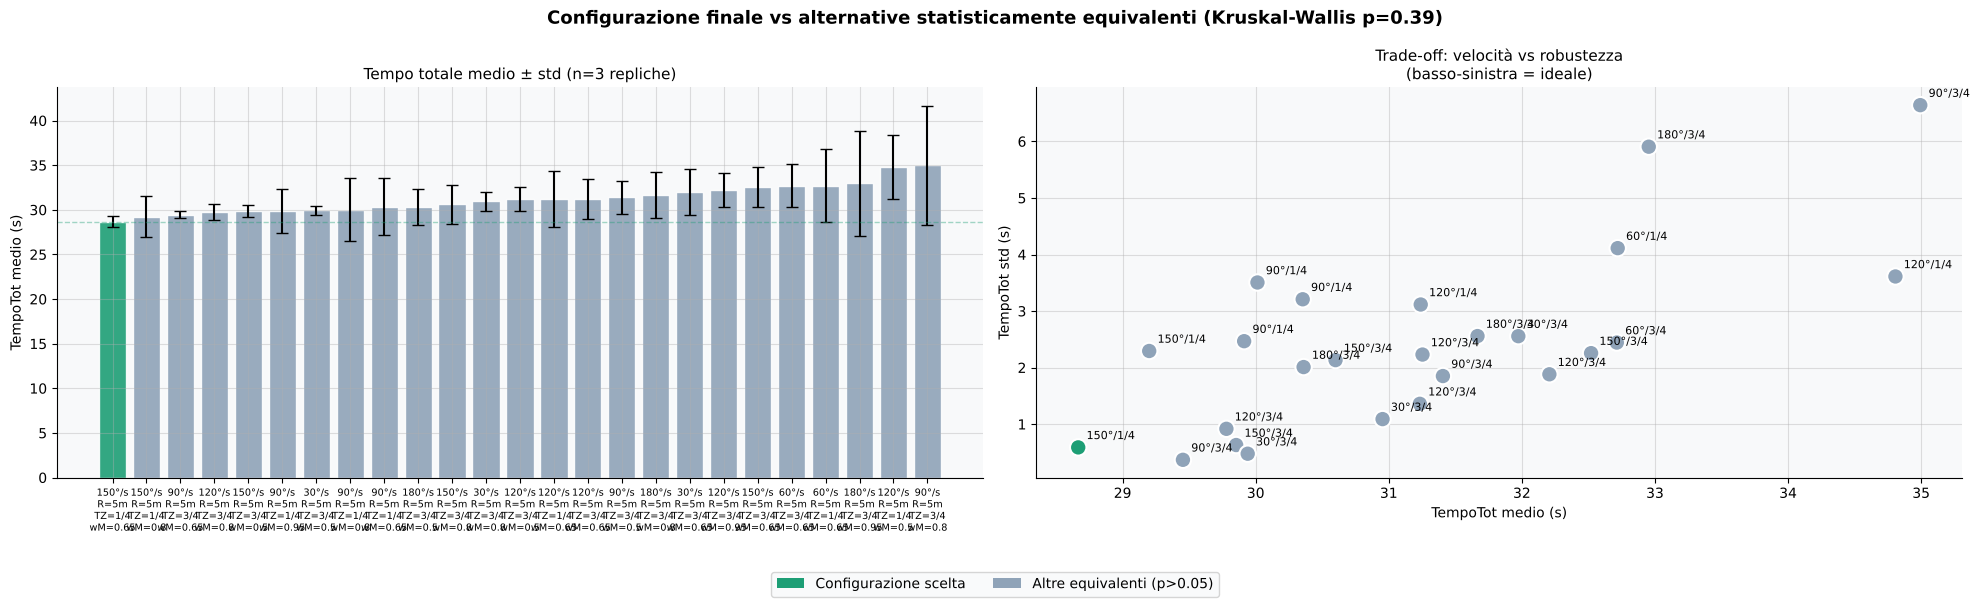


Configurazione scelta: angularSpeed=150°/s, wzRadius=5m, tzRadius=1.25m (1/4), warnMult=0.65, Dentro WZ
TempoTot = 28.67s ± 0.59s
Nessuna differenza statisticamente significativa rispetto alle altre 24 alternative (Kruskal-Wallis p=0.39)


In [38]:
# Grafico finale: configurazione scelta vs tutte le 25 configurazioni equivalenti

import matplotlib.pyplot as plt
import numpy as np

top8 = reliable.copy().reset_index(drop=True)
top8['label'] = top8.apply(
    lambda r: f"{int(r['angularSpeed'])}°/s\nR={r['wzRadius']}m\nTZ={r['TZ_WZ_Ratio']}\nwM={r['warnMult']}",
    axis=1
)


chosen_idx = top8.index[
    (top8['angularSpeed'] == 150) & (top8['wzRadius'] == 5) &
    (top8['tzRadius'] == 1.25) & (top8['warnMult'] == 0.65)
][0]

colors = ['#1D9E75' if i == chosen_idx else '#8FA3B8' for i in range(len(top8))]

fig, axes = plt.subplots(1, 2, figsize=(20, 5.5))
fig.suptitle(f'Configurazione finale vs alternative statisticamente equivalenti (Kruskal-Wallis p={p_all:.2f})',
             fontsize=13, fontweight='bold')

# --- Grafico 1: TempoTot medio con barre di errore (std) ---
axes[0].bar(range(len(top8)), top8['TempoTot'], yerr=top8['TempoTot_std'],
            color=colors, edgecolor='white', capsize=4, alpha=0.9)
axes[0].set_xticks(range(len(top8)))
axes[0].set_xticklabels(top8['label'], fontsize=7)
axes[0].set_ylabel('TempoTot medio (s)')
axes[0].set_title('Tempo totale medio ± std (n=3 repliche)', fontsize=11)
axes[0].axhline(top8.loc[chosen_idx, 'TempoTot'], color='#1D9E75', linestyle='--', alpha=0.4, linewidth=1)

# --- Grafico 2: scatter TempoTot vs std (robustezza) ---
axes[1].scatter(top8['TempoTot'], top8['TempoTot_std'], s=140, c=colors,
                 edgecolor='white', linewidth=1.5, zorder=3)
for i, row in top8.iterrows():
    axes[1].annotate(f"{int(row['angularSpeed'])}°/{row['TZ_WZ_Ratio']}",
                      (row['TempoTot'], row['TempoTot_std']),
                      textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set_xlabel('TempoTot medio (s)')
axes[1].set_ylabel('TempoTot std (s)')
axes[1].set_title('Trade-off: velocità vs robustezza\n(basso-sinistra = ideale)', fontsize=11)

legend_elems = [Patch(facecolor='#1D9E75', label='Configurazione scelta'),
                Patch(facecolor='#8FA3B8', label='Altre equivalenti (p>0.05)')]
fig.legend(handles=legend_elems, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.1))

plt.tight_layout()
plt.savefig('29_configurazione_finale.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nConfigurazione scelta: angularSpeed=150°/s, wzRadius=5m, tzRadius=1.25m (1/4), warnMult=0.65, Dentro WZ")
print(f"TempoTot = {top8.loc[chosen_idx,'TempoTot']:.2f}s ± {top8.loc[chosen_idx,'TempoTot_std']:.2f}s")
print(f"Nessuna differenza statisticamente significativa rispetto alle altre {len(top8)-1} alternative (Kruskal-Wallis p={p_all:.2f})")

## 32. Conclusioni dell'analisi su TempoTot (efficienza di sistema)

*Nota: queste erano le conclusioni basate esclusivamente sulla metrica di efficienza di sistema (TempoTot). Le sezioni successive (33-42) approfondiscono il tema, individuano un confound geometrico e introducono una seconda ottica di analisi ("naturalezza"), con conclusioni al termine del notebook (Sez. 42). Le sezioni 36-42 sono un'analisi esplorativa non usata nella tesi: la naturalezza del movimento è valutata con il questionario.*

**Obiettivo dell'analisi.** Identificare la combinazione di parametri (`angularSpeed`, `wzRadius`, `tzRadius`, `warnMult`, `posObiettivo`) che massimizza l'affidabilità di navigazione (NavMesh) e minimizza il tempo totale di completamento della scena, sostituendo un punteggio pesato arbitrariamente con una pipeline interamente guidata da test statistici.

**Metodologia.** Criterio di affidabilità sulle combinazioni (tre ripetizioni valide su tre e NavMesh=100% in tutte) → verifica delle assunzioni (Shapiro-Wilk, Levene) → ranking dei parametri per effect size (ε² su Kruskal-Wallis) → filtro sequenziale con Dunn post-hoc nell'ordine determinato dal ranking → verifica finale di equivalenza → conferma incrociata con Welch ANOVA → verifica con il criterio meno severo (Sez. 31-bis).

**Configurazione finale raccomandata:**

| Parametro | Valore |
|---|---|
| angularSpeed | 150 °/s |
| wzRadius | 5 m |
| tzRadius | 1.25 m (rapporto TZ/WZ = 1/4) |
| warnMult | 0.65 |
| posObiettivo | Dentro WZ |

TempoTot medio = 28.67s (± 0.59s su 3 repliche), NavMesh = 100%.

**Conclusioni operative:**

1. **`posObiettivo=Dentro WZ` è il parametro più determinante in assoluto** (ε²≈0.20): posizionare l'obiettivo dentro la Warning Zone riduce sistematicamente il tempo totale, indipendentemente dagli altri parametri.
2. **`wzRadius=5m` e un rapporto TZ/WZ di 1/4 (equivalente a 3/4) sono la configurazione spaziale ottimale**; la differenza tra 1/4 e 3/4 non è statisticamente distinguibile, quindi la scelta tra i due può essere guidata da altre esigenze di progetto.
3. **`angularSpeed` e `warnMult`, una volta garantita l'affidabilità, non hanno più un impatto misurabile sul tempo totale.** Questo è il risultato più significativo rispetto all'analisi descrittiva iniziale, dove `angularSpeed` sembrava il parametro dominante: quell'effetto era in realtà quasi interamente legato alla soglia di affidabilità (sotto i 90°/s l'agente spesso non completa la scena), non a un miglioramento continuo delle prestazioni oltre quella soglia. Tra le configurazioni superstiti, 150°/s è stato scelto per il tempo totale più basso a parità di robustezza (deviazione standard), ma valori come 90–180°/s sarebbero stati ugualmente validi dal punto di vista statistico.

## sezione 26.2


In [39]:
# ============================================================
# Sez. 26-bis — Analisi dei parametri SENZA filtraggio sequenziale
# Ogni parametro viene valutato indipendentemente sull'intero dataset
# di partenza (non su un sottoinsieme già ristretto dai parametri
# precedenti, a differenza del filtro sequenziale di Sez. 29/38).
# Eseguita sia CON che SENZA il criterio di affidabilità, per confronto.
# ============================================================
def analizza_parametri_senza_filtro(df, metrica, parametri, alpha=0.05, label_dataset=''):
    """
    Per ciascun parametro: Kruskal-Wallis + Dunn post-hoc sull'INTERO
    dataframe passato (nessuna riga viene scartata tra un parametro e
    l'altro). Restituisce solo un riepilogo di quali livelli risultano
    "migliori" (statisticamente equivalenti al top) per ciascun parametro.
    """
    print(f"\n{'='*70}")
    print(f"Dataset: {label_dataset}  (n={len(df)} righe, invariato per tutti i parametri)")
    print(f"{'='*70}")

    risultati = []
    for p in parametri:
        groups = [g[metrica].values for _, g in df.groupby(p)]
        h, pval = kruskal(*groups)
        eps2 = h / (len(df) - 1)

        if pval >= alpha:
            print(f"\n--- {p} ---")
            print(f"Kruskal-Wallis: H={h:.2f}  p={pval:.2e}  eps2={eps2:.4f}  NON significativo")
            risultati.append({'parametro': p, 'H': h, 'p_value': pval, 'epsilon2': eps2,
                               'livello_migliore': 'N/A', 'livelli_equivalenti': 'nessun effetto'})
            continue

        means = df.groupby(p)[metrica].mean()
        best_level = means.idxmin()  # min perché vogliamo TempoTot più basso

        dunn = sp.posthoc_dunn(df, val_col=metrica, group_col=p, p_adjust='bonferroni')
        equivalenti = sorted(dunn[best_level][dunn[best_level] > alpha].index.tolist())

        print(f"\n--- {p} ---")
        print(f"Kruskal-Wallis: H={h:.2f}  p={pval:.2e}  eps2={eps2:.4f}  significativo")
        print(f"Livello migliore: {p}={best_level} ({metrica} min={means[best_level]:.2f})")
        print(f"Livelli statisticamente equivalenti al migliore: {equivalenti}")

        risultati.append({'parametro': p, 'H': h, 'p_value': pval, 'epsilon2': eps2,
                           'livello_migliore': best_level, 'livelli_equivalenti': str(equivalenti)})

    riepilogo = pd.DataFrame(risultati).sort_values('epsilon2', ascending=False).reset_index(drop=True)
    print(f"\n--- Riepilogo ({label_dataset}) ---")
    display(riepilogo.round(4))
    return riepilogo


parametri_tutti = ['angularSpeed', 'wzRadius', 'TZ_WZ_Ratio', 'warnMult', 'posObiettivo']

# --- SENZA criterio di affidabilità (dataset `clean` completo) ---
clean['TZ_WZ_Ratio_num'] = clean['tzRadius'] / clean['wzRadius']
clean['TZ_WZ_Ratio'] = clean['TZ_WZ_Ratio_num'].apply(to_fraction)

riepilogo_senza_gate = analizza_parametri_senza_filtro(
    clean, 'Agent1_TempoTot', parametri_tutti, label_dataset='SENZA criterio di affidabilità (dataset completo)')

# --- CON criterio di affidabilità (dataset `stage0`) ---
riepilogo_con_gate = analizza_parametri_senza_filtro(
    stage0, 'Agent1_TempoTot', parametri_tutti, label_dataset='CON criterio di affidabilità')


Dataset: SENZA criterio di affidabilità (dataset completo)  (n=1015 righe, invariato per tutti i parametri)

--- angularSpeed ---
Kruskal-Wallis: H=62.31  p=4.05e-12  eps2=0.0614  significativo
Livello migliore: angularSpeed=30 (Agent1_TempoTot min=32.58)
Livelli statisticamente equivalenti al migliore: [30, 60]

--- wzRadius ---
Kruskal-Wallis: H=41.15  p=1.16e-09  eps2=0.0406  significativo
Livello migliore: wzRadius=3 (Agent1_TempoTot min=33.48)
Livelli statisticamente equivalenti al migliore: [3, 5]

--- TZ_WZ_Ratio ---
Kruskal-Wallis: H=73.47  p=1.11e-16  eps2=0.0725  significativo
Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=31.88)
Livelli statisticamente equivalenti al migliore: ['1/4']

--- warnMult ---
Kruskal-Wallis: H=0.93  p=8.17e-01  eps2=0.0009  NON significativo

--- posObiettivo ---
Kruskal-Wallis: H=98.67  p=2.98e-23  eps2=0.0973  significativo
Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=32.85)
Livelli statisticamente equivalenti al miglior

,parametro,H,p_value,epsilon2,livello_migliore,livelli_equivalenti
0,posObiettivo,98.6744,0.0000,0.0973,Dentro WZ,['Dentro WZ']
1,TZ_WZ_Ratio,73.4683,0.0000,0.0725,1/4,['1/4']
2,angularSpeed,62.3062,0.0000,0.0614,30,"[30, 60]"
3,wzRadius,41.1520,0.0000,0.0406,3,"[3, 5]"
4,warnMult,0.9334,0.8174,0.0009,N/A,nessun effetto



Dataset: CON criterio di affidabilità  (n=588 righe, invariato per tutti i parametri)

--- angularSpeed ---
Kruskal-Wallis: H=5.92  p=3.14e-01  eps2=0.0101  NON significativo

--- wzRadius ---
Kruskal-Wallis: H=27.56  p=1.03e-06  eps2=0.0470  significativo
Livello migliore: wzRadius=5 (Agent1_TempoTot min=33.82)
Livelli statisticamente equivalenti al migliore: [5]

--- TZ_WZ_Ratio ---
Kruskal-Wallis: H=25.28  p=3.25e-06  eps2=0.0431  significativo
Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=32.30)
Livelli statisticamente equivalenti al migliore: ['1/4']

--- warnMult ---
Kruskal-Wallis: H=0.15  p=9.86e-01  eps2=0.0003  NON significativo

--- posObiettivo ---
Kruskal-Wallis: H=117.51  p=2.22e-27  eps2=0.2002  significativo
Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=33.84)
Livelli statisticamente equivalenti al migliore: ['Dentro WZ']

--- Riepilogo (CON criterio di affidabilità) ---


,parametro,H,p_value,epsilon2,livello_migliore,livelli_equivalenti
0,posObiettivo,117.5102,0.0000,0.2002,Dentro WZ,['Dentro WZ']
1,wzRadius,27.5627,0.0000,0.0470,5,[5]
2,TZ_WZ_Ratio,25.2759,0.0000,0.0431,1/4,['1/4']
3,angularSpeed,5.9215,0.3139,0.0101,N/A,nessun effetto
4,warnMult,0.1471,0.9856,0.0003,N/A,nessun effetto


In [40]:
# ============================================================
# Confronto affiancato dei due riepiloghi
# ============================================================
confronto = riepilogo_senza_gate.merge(
    riepilogo_con_gate, on='parametro', suffixes=('_senza_gate', '_con_gate'))
display(confronto[['parametro', 'epsilon2_senza_gate', 'livello_migliore_senza_gate',
                    'epsilon2_con_gate', 'livello_migliore_con_gate']].round(4))

,parametro,epsilon2_senza_gate,livello_migliore_senza_gate,epsilon2_con_gate,livello_migliore_con_gate
0,posObiettivo,0.0973,Dentro WZ,0.2002,Dentro WZ
1,TZ_WZ_Ratio,0.0725,1/4,0.0431,1/4
2,angularSpeed,0.0614,30,0.0101,N/A
3,wzRadius,0.0406,3,0.0470,5
4,warnMult,0.0009,N/A,0.0003,N/A


In [41]:
# ============================================================
# Verifica distribuzione completa di NavMesh (non solo 0/1) e conferma
# del filtro corretto per "successo pieno" (entrambi gli artefatti)
# ============================================================
sub30 = clean[clean['angularSpeed'] == 30]
print("Distribuzione di Agent1_NavMesh per angularSpeed=30:")
print(sub30['Agent1_NavMesh'].value_counts().sort_index())

print(f"\nTotale righe: {len(sub30)}")
print(f"NavMesh==1.0 (successo pieno, entrambi artefatti): {(sub30['Agent1_NavMesh']==1.0).sum()}")
print(f"NavMesh==0.5 (successo parziale, un solo artefatto): {(sub30['Agent1_NavMesh']==0.5).sum()}")
print(f"NavMesh==0.0 (fallimento totale): {(sub30['Agent1_NavMesh']==0.0).sum()}")

Distribuzione di Agent1_NavMesh per angularSpeed=30:
Agent1_NavMesh
0.0    36
0.5    54
1.0    94
Name: count, dtype: int64

Totale righe: 184
NavMesh==1.0 (successo pieno, entrambi artefatti): 94
NavMesh==0.5 (successo parziale, un solo artefatto): 54
NavMesh==0.0 (fallimento totale): 36


In [42]:
# ============================================================
# Riepilogo definitivo: solo episodi con successo pieno (NavMesh==1.0)
# ============================================================
clean_solo_successi = clean[clean['Agent1_NavMesh'] == 1.0].copy()

print(f"Righe clean totali: {len(clean)}")
print(f"Righe con successo pieno (NavMesh==1.0): {len(clean_solo_successi)}\n")

riepilogo_senza_gate = analizza_parametri_senza_filtro(
    clean_solo_successi, 'Agent1_TempoTot', parametri_tutti,
    label_dataset='SENZA gate di combinazione, solo episodi con successo pieno')

riepilogo_con_gate = analizza_parametri_senza_filtro(
    stage0, 'Agent1_TempoTot', parametri_tutti,
    label_dataset='CON criterio di affidabilità per combinazione')

Righe clean totali: 1015
Righe con successo pieno (NavMesh==1.0): 803


Dataset: SENZA gate di combinazione, solo episodi con successo pieno  (n=803 righe, invariato per tutti i parametri)

--- angularSpeed ---
Kruskal-Wallis: H=7.94  p=1.60e-01  eps2=0.0099  NON significativo

--- wzRadius ---
Kruskal-Wallis: H=43.38  p=3.81e-10  eps2=0.0541  significativo
Livello migliore: wzRadius=5 (Agent1_TempoTot min=34.04)
Livelli statisticamente equivalenti al migliore: [5]

--- TZ_WZ_Ratio ---
Kruskal-Wallis: H=27.13  p=1.29e-06  eps2=0.0338  significativo
Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=33.48)
Livelli statisticamente equivalenti al migliore: ['1/4']

--- warnMult ---
Kruskal-Wallis: H=0.76  p=8.59e-01  eps2=0.0009  NON significativo



--- posObiettivo ---
Kruskal-Wallis: H=186.53  p=1.81e-42  eps2=0.2326  significativo
Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=33.61)
Livelli statisticamente equivalenti al migliore: ['Dentro WZ']

--- Riepilogo (SENZA gate di combinazione, solo episodi con successo pieno) ---


,parametro,H,p_value,epsilon2,livello_migliore,livelli_equivalenti
0,posObiettivo,186.5345,0.0000,0.2326,Dentro WZ,['Dentro WZ']
1,wzRadius,43.3755,0.0000,0.0541,5,[5]
2,TZ_WZ_Ratio,27.1270,0.0000,0.0338,1/4,['1/4']
3,angularSpeed,7.9369,0.1597,0.0099,N/A,nessun effetto
4,warnMult,0.7604,0.8589,0.0009,N/A,nessun effetto



Dataset: CON criterio di affidabilità per combinazione  (n=588 righe, invariato per tutti i parametri)

--- angularSpeed ---
Kruskal-Wallis: H=5.92  p=3.14e-01  eps2=0.0101  NON significativo

--- wzRadius ---
Kruskal-Wallis: H=27.56  p=1.03e-06  eps2=0.0470  significativo
Livello migliore: wzRadius=5 (Agent1_TempoTot min=33.82)
Livelli statisticamente equivalenti al migliore: [5]

--- TZ_WZ_Ratio ---
Kruskal-Wallis: H=25.28  p=3.25e-06  eps2=0.0431  significativo
Livello migliore: TZ_WZ_Ratio=1/4 (Agent1_TempoTot min=32.30)
Livelli statisticamente equivalenti al migliore: ['1/4']

--- warnMult ---
Kruskal-Wallis: H=0.15  p=9.86e-01  eps2=0.0003  NON significativo

--- posObiettivo ---
Kruskal-Wallis: H=117.51  p=2.22e-27  eps2=0.2002  significativo
Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=33.84)
Livelli statisticamente equivalenti al migliore: ['Dentro WZ']

--- Riepilogo (CON criterio di affidabilità per combinazione) ---


,parametro,H,p_value,epsilon2,livello_migliore,livelli_equivalenti
0,posObiettivo,117.5102,0.0000,0.2002,Dentro WZ,['Dentro WZ']
1,wzRadius,27.5627,0.0000,0.0470,5,[5]
2,TZ_WZ_Ratio,25.2759,0.0000,0.0431,1/4,['1/4']
3,angularSpeed,5.9215,0.3139,0.0101,N/A,nessun effetto
4,warnMult,0.1471,0.9856,0.0003,N/A,nessun effetto


In [43]:
# ============================================================
# Sez. 26-quater — Configurazioni migliori SENZA filtraggio sequenziale
# Stessa logica di combo_stats/final_survivors delle Sez. 29 e 38, ma qui
# aggregata direttamente sull'intero dataset (nessun taglio progressivo
# parametro per parametro). Fatta per Efficienza e Naturalezza, con e
# senza il criterio di affidabilità per combinazione.
# ============================================================

def configurazioni_migliori(df, colonna_metrica, n_min=3, n_top_verifica=8, label=''):
    """
    Aggrega per combinazione completa di parametri, ordina per la metrica
    (più basso = meglio), filtra per affidabilità campionaria (n>=n_min),
    e verifica se le top-N sono statisticamente equivalenti tra loro
    (Kruskal-Wallis) — stesso schema di Sez. 30/38.
    """
    df = df.copy()
    df['combo'] = (df['angularSpeed'].astype(str) + '_' + df['wzRadius'].astype(str) + '_' +
                   df['tzRadius'].astype(str) + '_' + df['warnMult'].astype(str) + '_' +
                   df['posObiettivo'])

    combo_stats = df.groupby('combo').agg(
        n=(colonna_metrica, 'size'),
        media=(colonna_metrica, 'mean'),
        std=(colonna_metrica, 'std'),
    ).reset_index().sort_values('media')

    reliable = combo_stats[combo_stats['n'] >= n_min].copy()

    print(f"\n{'='*70}")
    print(f"{label}  (metrica: {colonna_metrica})")
    print(f"{'='*70}")
    print(f"Combinazioni totali: {len(combo_stats)}  |  con n>={n_min}: {len(reliable)}\n")
    display(reliable.head(10).round(3))

    # Verifica di equivalenza statistica tra le top-N affidabili
    top_combos = reliable.head(n_top_verifica)['combo'].tolist()
    sub = df[df['combo'].isin(top_combos)]
    if sub['combo'].nunique() >= 2:
        h, p = kruskal(*[g[colonna_metrica].values for _, g in sub.groupby('combo')])
        print(f"Kruskal-Wallis tra le top-{n_top_verifica}: H={h:.2f}, p={p:.4f}",
              "-> equivalenti" if p >= 0.05 else "-> alcune differiscono davvero")

    return reliable


# --- Dataset base ---
clean_solo_successi = clean[clean['Agent1_NavMesh'] == 1.0].copy()
clean_solo_successi['gap'] = clean_solo_successi['wzRadius'] - clean_solo_successi['tzRadius']
clean_solo_successi['TempoWZ_locale_medio'] = clean_solo_successi[
    ['Agent1_Totem4_TempoWZ', 'Agent1_Monitor_TempoWZ']].mean(axis=1)
clean_solo_successi['TempoWZ_per_gap'] = (
    clean_solo_successi['TempoWZ_locale_medio'] / clean_solo_successi['gap'].replace(0, np.nan)
)

stage0['gap'] = stage0['wzRadius'] - stage0['tzRadius']
stage0['TempoWZ_locale_medio'] = stage0[['Agent1_Totem4_TempoWZ', 'Agent1_Monitor_TempoWZ']].mean(axis=1)
stage0['TempoWZ_per_gap'] = stage0['TempoWZ_locale_medio'] / stage0['gap'].replace(0, np.nan)

# ============================================================
# 4 tabelle: Efficienza/Naturalezza x senza-gate/con-gate
# ============================================================
reliable_eff_senza_gate = configurazioni_migliori(
    clean_solo_successi, 'Agent1_TempoTot', label='EFFICIENZA — senza gate combinazione')

reliable_eff_con_gate = configurazioni_migliori(
    stage0, 'Agent1_TempoTot', label='EFFICIENZA — con criterio di affidabilità')



EFFICIENZA — senza gate combinazione  (metrica: Agent1_TempoTot)
Combinazioni totali: 334  |  con n>=3: 196



,combo,n,media,std
295,90_4_2.0_0.5_Dentro WZ,3,27.933,0.281
102,150_5_1.25_0.65_Dentro WZ,3,28.667,0.590
6,120_3_1.5_0.95_Dentro WZ,3,29.107,1.693
104,150_5_1.25_0.8_Dentro WZ,3,29.200,2.294
328,90_5_3.75_0.65_Dentro WZ,3,29.453,0.370
57,120_5_3.75_0.8_Dentro WZ,3,29.780,0.918
116,150_5_3.75_0.5_Dentro WZ,3,29.853,0.631
317,90_5_1.25_0.95_Dentro WZ,3,29.913,2.468
218,30_5_3.75_0.5_Dentro WZ,3,29.940,0.478
82,150_4_1.0_0.95_Dentro WZ,3,29.953,3.631


Kruskal-Wallis tra le top-8: H=8.25, p=0.3113 -> equivalenti

EFFICIENZA — con criterio di affidabilità  (metrica: Agent1_TempoTot)
Combinazioni totali: 196  |  con n>=3: 196



,combo,n,media,std
170,90_4_2.0_0.5_Dentro WZ,3,27.933,0.281
65,150_5_1.25_0.65_Dentro WZ,3,28.667,0.590
3,120_3_1.5_0.95_Dentro WZ,3,29.107,1.693
66,150_5_1.25_0.8_Dentro WZ,3,29.200,2.294
193,90_5_3.75_0.65_Dentro WZ,3,29.453,0.370
34,120_5_3.75_0.8_Dentro WZ,3,29.780,0.918
72,150_5_3.75_0.5_Dentro WZ,3,29.853,0.631
185,90_5_1.25_0.95_Dentro WZ,3,29.913,2.468
130,30_5_3.75_0.5_Dentro WZ,3,29.940,0.478
49,150_4_1.0_0.95_Dentro WZ,3,29.953,3.631


Kruskal-Wallis tra le top-8: H=8.25, p=0.3113 -> equivalenti


## 33. angularSpeed e warnMult: effetto su TempoWZ e su NavMesh (prima del criterio di affidabilità)

Le sezioni precedenti hanno mostrato che, dopo il criterio di affidabilità, `angularSpeed` e `warnMult` perdono di significatività su TempoTot. Prima di concludere che siano del tutto irrilevanti, verifichiamo dove agiscono realmente: su quale fase (TempoWZ, l'avvicinamento) e sul gate stesso (NavMesh, PRIMA di applicarlo), usando il dataset `clean` completo, non `stage0` già filtrato.

In [44]:
# Eseguito su `clean` (PRIMA del criterio di affidabilità): dopo il criterio di affidabilità non ha
# più varianza, quindi l'effetto sulla soglia di affidabilità si vede solo qui.

print("=== Effetto su Agent1_TempoWZ (fase di avvicinamento) ===")
for p in ['angularSpeed', 'warnMult']:
    groups = [g['Agent1_TempoWZ'].values for _, g in clean.groupby(p)]
    h, pv = kruskal(*groups)
    eps2 = h / (len(clean) - 1)
    print(f"  {p}: H={h:.2f}  p={pv:.2e}  eps2={eps2:.4f}  "
          f"({'significativo' if pv<0.05 else 'non significativo'})")

print("\n=== Effetto su Agent1_NavMesh (raggiungimento target, prima del criterio) ===")
for p in ['angularSpeed', 'warnMult']:
    groups = [g['Agent1_NavMesh'].values for _, g in clean.groupby(p)]
    h, pv = kruskal(*groups)
    eps2 = h / (len(clean) - 1)
    print(f"  {p}: H={h:.2f}  p={pv:.2e}  eps2={eps2:.4f}  "
          f"({'significativo' if pv<0.05 else 'non significativo'})")
    means = clean.groupby(p)['Agent1_NavMesh'].mean()
    print(f"    NavMesh medio per livello: {means.round(3).to_dict()}")

=== Effetto su Agent1_TempoWZ (fase di avvicinamento) ===
  angularSpeed: H=58.17  p=2.91e-11  eps2=0.0574  (significativo)
  warnMult: H=0.14  p=9.87e-01  eps2=0.0001  (non significativo)

=== Effetto su Agent1_NavMesh (raggiungimento target, prima del criterio) ===
  angularSpeed: H=189.37  p=5.32e-39  eps2=0.1868  (significativo)
    NavMesh medio per livello: {30: 0.658, 60: 0.751, 90: 0.943, 120: 0.969, 150: 0.97, 180: 0.948}
  warnMult: H=4.45  p=2.17e-01  eps2=0.0044  (non significativo)
    NavMesh medio per livello: {0.5: 0.873, 0.65: 0.885, 0.8: 0.864, 0.95: 0.843}


### 💬 Lettura
`angularSpeed` ha un effetto molto più forte su NavMesh (ε²=0.19) che su TempoWZ (ε²=0.06): conferma quantitativamente che il suo ruolo principale è determinare *se* l'agente raggiunge il target (soglia di affidabilità), non quanto è efficiente il suo comportamento una volta che ce la fa. Da notare anche il lieve calo di NavMesh a 180°/s (0.948) rispetto a 150°/s (0.970): rotazioni troppo rapide potrebbero causare overshoot occasionali. `warnMult` resta non significativo su entrambe le metriche.

## 34. wzRadius ottimale per artefatto: Totem4 vs Monitor

Finora `wzRadius` è stato valutato sulla media aggregata tra i due artefatti. Ma se Totem4 e Monitor hanno scale fisiche diverse, un raggio "ottimale in media" potrebbe essere sproporzionato per uno dei due. Verifichiamo separatamente.

In [45]:
# Metriche separate per artefatto (colonne Agent1_Totem4_* e Agent1_Monitor_*),
# eseguito su stage0 (dopo il criterio di affidabilità).

for artefatto, col_tempo in [('Totem4', 'Agent1_Totem4_TempoWZ'), ('Monitor', 'Agent1_Monitor_TempoWZ')]:
    sub = stage0.dropna(subset=[col_tempo])
    print(f"\n=== {artefatto} (n={len(sub)}) ===")
    means = sub.groupby('wzRadius')[col_tempo].mean().round(2)
    print(f"TempoWZ medio per wzRadius:\n{means}")

    groups = [g[col_tempo].values for _, g in sub.groupby('wzRadius')]
    h, pv = kruskal(*groups)
    print(f"Kruskal-Wallis: H={h:.2f}, p={pv:.2e}")
    if pv < 0.05:
        dunn = sp.posthoc_dunn(sub, val_col=col_tempo, group_col='wzRadius', p_adjust='bonferroni')
        best = means.idxmin()
        print(f"Radius migliore per {artefatto}: {best}")
        print(dunn.round(4))


=== Totem4 (n=588) ===
TempoWZ medio per wzRadius:
wzRadius
3    0.53
4    0.73
5    0.95
Name: Agent1_Totem4_TempoWZ, dtype: float64
Kruskal-Wallis: H=156.08, p=1.28e-34
Radius migliore per Totem4: 3
     3    4    5
3  1.0  0.0  0.0
4  0.0  1.0  0.0
5  0.0  0.0  1.0

=== Monitor (n=588) ===
TempoWZ medio per wzRadius:
wzRadius
3    0.63
4    0.86
5    1.35
Name: Agent1_Monitor_TempoWZ, dtype: float64
Kruskal-Wallis: H=198.66, p=7.26e-44
Radius migliore per Monitor: 3
     3    4    5
3  1.0  0.0  0.0
4  0.0  1.0  0.0
5  0.0  0.0  1.0


### 💬 Lettura
Per entrambi gli artefatti, `wzRadius=3` (il più piccolo) è nettamente il migliore per TempoWZ isolato — l'opposto di quanto risultava ottimizzando su TempoTot (dove vinceva 5). È il primo segnale del trade-off approfondito nella sezione successiva.

## 35. Decomposizione: dove viene "recuperato" il tempo con wzRadius grande?

Se un raggio maggiore peggiora il tempo locale (Sez. 34) ma il TempoTot complessivo migliora (Sez. 26-30), il risparmio deve avvenire *prima* dell'ingresso in WZ. Verifichiamolo confrontando la somma TempoWZ+TempoTZ locale con il TempoTot di scena.

In [46]:
# Se 'Somma_WZ_TZ' cresce con wzRadius ma TempoTot (scena intera) no, il
# risparmio di tempo avviene nella fase di pre-approach, prima della WZ.

for artefatto, col_wz, col_tz in [
    ('Totem4', 'Agent1_Totem4_TempoWZ', 'Agent1_Totem4_TempoTZ'),
    ('Monitor', 'Agent1_Monitor_TempoWZ', 'Agent1_Monitor_TempoTZ'),
]:
    sub = stage0.dropna(subset=[col_wz, col_tz])
    print(f"\n=== {artefatto} ===")
    tab = sub.groupby('wzRadius')[[col_wz, col_tz]].mean().round(3)
    tab['Somma_WZ_TZ'] = tab[col_wz] + tab[col_tz]
    print(tab)
    print(f"TempoTot medio (scena intera) per confronto:")
    print(sub.groupby('wzRadius')['Agent1_TempoTot'].mean().round(3))


=== Totem4 ===
          Agent1_Totem4_TempoWZ  Agent1_Totem4_TempoTZ  Somma_WZ_TZ
wzRadius                                                           
3                         0.529                  2.251        2.780
4                         0.726                  3.122        3.848
5                         0.951                  3.704        4.655
TempoTot medio (scena intera) per confronto:
wzRadius
3    34.984
4    35.639
5    33.823
Name: Agent1_TempoTot, dtype: float64

=== Monitor ===
          Agent1_Monitor_TempoWZ  Agent1_Monitor_TempoTZ  Somma_WZ_TZ
wzRadius                                                             
3                          0.633                   4.440        5.073
4                          0.864                   4.689        5.553
5                          1.352                   5.220        6.572
TempoTot medio (scena intera) per confronto:
wzRadius
3    34.984
4    35.639
5    33.823
Name: Agent1_TempoTot, dtype: float64


### 💬 Lettura
Confermato: `Somma_WZ_TZ` cresce monotonicamente con wzRadius per entrambi gli artefatti, ma `TempoTot` è minimo proprio a wzRadius=5 (non segue lo stesso andamento). Un raggio di rilevamento più ampio fa iniziare la risposta comportamentale dell'agente più precocemente nel tragitto, compensando il maggior tempo speso dentro WZ/TZ. Grafico che visualizza il trade-off:

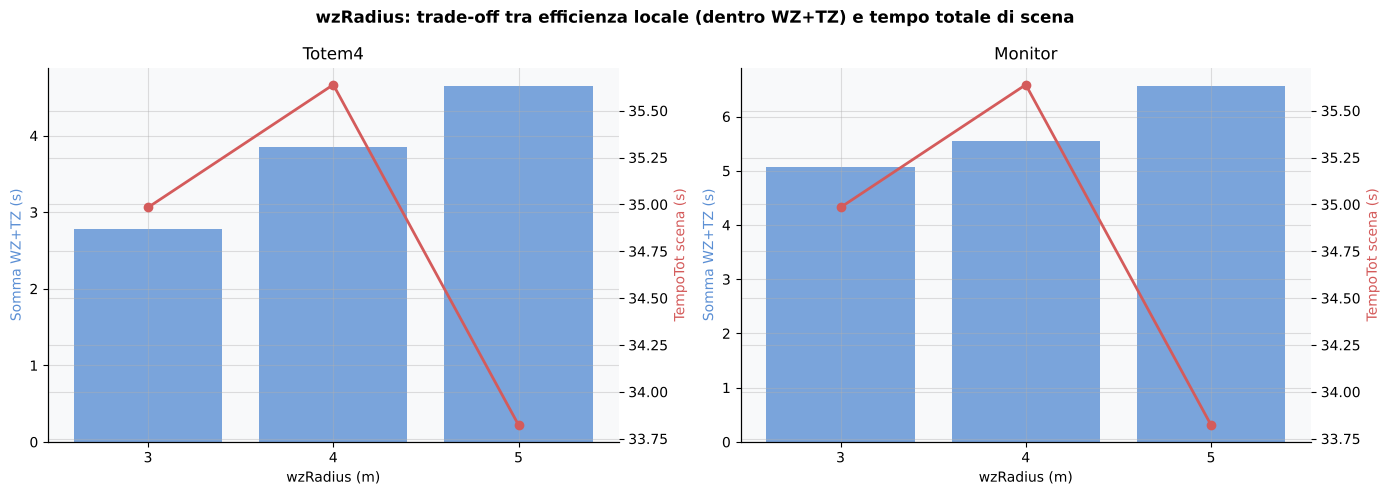

In [47]:
# Trade-off wzRadius: tempo totale vs efficienza locale

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('wzRadius: trade-off tra efficienza locale (dentro WZ+TZ) e tempo totale di scena',
             fontsize=12, fontweight='bold')

for artefatto, col_wz, col_tz, ax in [
    ('Totem4', 'Agent1_Totem4_TempoWZ', 'Agent1_Totem4_TempoTZ', axes[0]),
    ('Monitor', 'Agent1_Monitor_TempoWZ', 'Agent1_Monitor_TempoTZ', axes[1]),
]:
    sub = stage0.dropna(subset=[col_wz, col_tz])
    tab = sub.groupby('wzRadius')[[col_wz, col_tz]].mean()
    tot = sub.groupby('wzRadius')['Agent1_TempoTot'].mean()

    x = tab.index.astype(str)
    ax.bar(x, tab[col_wz] + tab[col_tz], color='#5B8FD4', alpha=0.8, label='Somma TempoWZ+TempoTZ (locale)')
    ax2 = ax.twinx()
    ax2.plot(x, tot.values, color='#D45B5B', marker='o', linewidth=2, label='TempoTot (scena intera)')

    ax.set_title(artefatto)
    ax.set_ylabel('Somma WZ+TZ (s)', color='#5B8FD4')
    ax2.set_ylabel('TempoTot scena (s)', color='#D45B5B')
    ax.set_xlabel('wzRadius (m)')

plt.tight_layout()
plt.savefig('33_tradeoff_wzradius.png', dpi=150, bbox_inches='tight')
plt.show()

### 35-bis. Decomposizione sul tempo totale e composizione dei gruppi

Stessa decomposizione sulle metriche complessive (somma sui due artefatti): tempo nelle zone (TempoWZ + TempoTZ) e tempo restante. Poiché i gruppi di wzRadius non hanno la stessa composizione, il confronto è ripetuto per posizione dell'obiettivo e solo con i rapporti 2/4 e 3/4 (il rapporto 1/4 manca con la WZ di 3 m).

In [48]:
dec = stage0.copy()
dec['zone'] = dec['Agent1_TempoWZ'] + dec['Agent1_TempoTZ']
dec['restante'] = dec['Agent1_TempoTot'] - dec['zone']
print("Tutte le combinazioni affidabili:")
display(dec.groupby('wzRadius')[['zone', 'restante', 'Agent1_TempoTot']].mean().round(2))
print("Quota con l'obiettivo dentro la WZ per raggio:",
      dec.groupby('wzRadius')['posObiettivo'].apply(lambda x: (x == 'Dentro WZ').mean()).round(3).to_dict())
for pos in ['Dentro WZ', 'Fuori WZ']:
    print(f"\n{pos}:")
    display(dec[dec['posObiettivo'] == pos].groupby('wzRadius')[['zone', 'restante', 'Agent1_TempoTot']].mean().round(2))
dec24 = dec[dec['TZ_WZ_Ratio'].isin(['2/4', '3/4'])]
print("\nSolo rapporti 2/4 e 3/4:")
display(dec24.groupby('wzRadius')[['zone', 'restante', 'Agent1_TempoTot']].mean().round(2))
print("Dunn (Bonferroni), WZ di 5 m contro gli altri raggi:",
      sp.posthoc_dunn(dec24, val_col='Agent1_TempoTot', group_col='wzRadius', p_adjust='bonferroni')[5].round(4).to_dict())

Tutte le combinazioni affidabili:


,zone,restante,Agent1_TempoTot
wzRadius,,,
3,7.85,27.13,34.98
4,9.40,26.24,35.64
5,11.23,22.60,33.82


Quota con l'obiettivo dentro la WZ per raggio: {3: 0.864, 4: 0.628, 5: 0.712}

Dentro WZ:


,zone,restante,Agent1_TempoTot
wzRadius,,,
3,7.75,26.46,34.21
4,9.58,24.96,34.54
5,11.30,21.43,32.73



Fuori WZ:


,zone,restante,Agent1_TempoTot
wzRadius,,,
3,8.52,31.36,39.88
4,9.10,28.38,37.49
5,11.05,25.49,36.53



Solo rapporti 2/4 e 3/4:


,zone,restante,Agent1_TempoTot
wzRadius,,,
3,7.85,27.13,34.98
4,9.38,26.47,35.85
5,11.56,22.62,34.18


Dunn (Bonferroni), WZ di 5 m contro gli altri raggi: {3: 0.1806, 4: 0.0, 5: 1.0}


### 💬 Lettura
Passando da 3 a 5 m il tempo nelle zone sale di circa 3.4 s e il tempo restante scende di circa 4.5 s. La riduzione del tempo restante resta anche separando le due posizioni dell'obiettivo (5.0 e 5.9 s). Considerando solo i rapporti 2/4 e 3/4 il saldo si riduce (34.18 contro 34.98 s) e la WZ di 5 m non è più distinguibile da quella di 3 m (p=0.18): il vantaggio rispetto a 3 m dipende in parte dall'assenza del rapporto 1/4 con la WZ di 3 m.

## 35-ter. Verifica: analisi senza l'esclusione degli episodi anomali

La soglia del 95° percentile è una scelta discrezionale. Ripetiamo l'analisi escludendo solo timeout e tempi negativi, con lo stesso criterio di affidabilità (tre ripetizioni valide su tre e NavMesh=100%).

In [49]:
clean_np = filled[~filled['isTimeout'] & ~filled['hasNegative']].copy()
pc_np = (clean_np.groupby(CHIAVI)
         .agg(n_valide=('Agent1_NavMesh', 'size'), NavMesh=('Agent1_NavMesh', 'mean')).reset_index())
aff_np = pc_np[(pc_np['n_valide'] == 3) & (pc_np['NavMesh'] == 1.0)]
s0_np = clean_np.merge(aff_np[CHIAVI], on=CHIAVI, how='inner')
s0_np['TZ_WZ_Ratio'] = (s0_np['tzRadius'] / s0_np['wzRadius']).apply(to_fraction)
print(f"Righe valide: {len(clean_np)} | combinazioni con almeno una valida: {len(pc_np)} | "
      f"affidabili: {len(aff_np)} ({len(s0_np)} righe)\n")
for p in ['posObiettivo', 'wzRadius', 'TZ_WZ_Ratio', 'angularSpeed', 'warnMult']:
    h, pv = kruskal(*[g['Agent1_TempoTot'].values for _, g in s0_np.groupby(p)])
    print(f"  {p}: H={h:.2f}  p={pv:.3g}  eps2={epsilon_squared(h, len(s0_np)):.4f}  "
          f"medie={s0_np.groupby(p)['Agent1_TempoTot'].mean().round(2).to_dict()}")
print()
np1 = filtro_sequenziale(s0_np, 'posObiettivo', 'Agent1_TempoTot', direction='min', label='1. posObiettivo')
np2 = filtro_sequenziale(np1, 'wzRadius', 'Agent1_TempoTot', direction='min', label='2. wzRadius')
print(sp.posthoc_dunn(np1, val_col='Agent1_TempoTot', group_col='wzRadius', p_adjust='bonferroni').round(4))
np3 = filtro_sequenziale(np2, 'TZ_WZ_Ratio', 'Agent1_TempoTot', direction='min', label='3. Rapporto TZ/WZ')
np3 = np3.copy()
np3['combo'] = np3[CHIAVI].astype(str).agg('_'.join, axis=1)
np_conf = np3.groupby('combo')['Agent1_TempoTot'].agg(['size', 'mean', 'std']).sort_values('mean')
h, pv = kruskal(*[g['Agent1_TempoTot'].values for _, g in np3.groupby('combo')])
dn = sp.posthoc_dunn(np3, val_col='Agent1_TempoTot', group_col='combo', p_adjust='bonferroni')
print(f"Configurazioni rimaste: {len(np_conf)} | Kruskal-Wallis: H={h:.2f}, p={pv:.3f} | "
      f"confronti a coppie: {len(np_conf)*(len(np_conf)-1)//2} | "
      f"p minimo di Dunn: {dn.where(~np.eye(len(dn), dtype=bool)).min().min():.3f}")
display(np_conf.head(5).round(2))
print("Posizione della configurazione scelta:", list(np_conf.index).index('150_5_1.25_0.65_Dentro WZ') + 1)

Righe valide: 1118 | combinazioni con almeno una valida: 399 | affidabili: 220 (660 righe)

  posObiettivo: H=114.34  p=1.1e-26  eps2=0.1735  medie={'Dentro WZ': 34.97, 'Fuori WZ': 39.85}
  wzRadius: H=16.66  p=0.000241  eps2=0.0253  medie={3: 34.98, 4: 36.97, 5: 36.72}
  TZ_WZ_Ratio: H=1.43  p=0.49  eps2=0.0022  medie={'1/4': 40.4, '2/4': 36.33, '3/4': 35.35}
  angularSpeed: H=7.77  p=0.169  eps2=0.0118  medie={30: 35.15, 60: 35.87, 90: 36.5, 120: 37.95, 150: 35.62, 180: 37.08}
  warnMult: H=0.28  p=0.965  eps2=0.0004  medie={0.5: 36.62, 0.65: 35.8, 0.8: 36.65, 0.95: 36.92}

--- Filtro: 1. posObiettivo (su Agent1_TempoTot) ---
Kruskal-Wallis: H=114.34  p=1.10e-26  (effetto significativo)
  Livello migliore: posObiettivo=Dentro WZ (Agent1_TempoTot min=34.97)
  Livelli statisticamente equivalenti (p>0.05): ['Dentro WZ']
  Righe: 660 -> 456

--- Filtro: 2. wzRadius (su Agent1_TempoTot) ---
Kruskal-Wallis: H=13.47  p=1.19e-03  (effetto significativo)
  Livello migliore: wzRadius=3 (Agent1

,size,mean,std
combo,,,
90_4_2.0_0.5_Dentro WZ,3,27.93,0.28
150_5_1.25_0.65_Dentro WZ,3,28.67,0.59
120_3_1.5_0.95_Dentro WZ,3,29.11,1.69
150_5_1.25_0.8_Dentro WZ,3,29.20,2.29
90_5_3.75_0.65_Dentro WZ,3,29.45,0.37


Posizione della configurazione scelta: 2


### 💬 Lettura
Senza l'esclusione degli episodi anomali restano solidi il ruolo di `posObiettivo` e la non significatività di `angularSpeed` e `warnMult`. Cambiano invece i risultati sulle zone: per wzRadius il migliore diventa 3 m, non distinguibile da 4 e 5 m, e il rapporto TZ/WZ non è più significativo. Restano 152 configurazioni, non distinguibili a coppie; la configurazione scelta è seconda per media.

## 36. Filtro sequenziale con priorità "naturalezza" (primo tentativo)

Su richiesta esplicita di invertire la gerarchia dei criteri (naturalezza prima, efficienza poi), ripetiamo il filtro sequenziale usando come metrica guida il tempo locale medio (TempoWZ) invece di TempoTot. **Attenzione**: questo primo tentativo userà la metrica grezza, non ancora corretta per un problema che emerge nella sezione successiva.

In [50]:
#  questa versione usa TempoWZ_locale_medio grezzo (non corretto).

# Metrica di naturalezza: media tra TempoWZ dei due artefatti (Totem4+Monitor)
stage0['TempoWZ_locale_medio'] = stage0[['Agent1_Totem4_TempoWZ', 'Agent1_Monitor_TempoWZ']].mean(axis=1)

print(f"Dataset dopo criterio di affidabilità: {len(stage0)} righe\n")

# 1. posObiettivo resta primo: effect size dominante confermato anche sulla naturalezza
stage1 = filtro_sequenziale(stage0, 'posObiettivo', 'TempoWZ_locale_medio',
                             direction='min', label='1. posObiettivo (naturalezza)')

# 2. wzRadius filtrato sulla NATURALEZZA (locale), non più su TempoTot
stage2 = filtro_sequenziale(stage1, 'wzRadius', 'TempoWZ_locale_medio',
                             direction='min', label='2. wzRadius (naturalezza -> radius piccolo atteso vincere)')

# 3. TZ_WZ_Ratio, stessa metrica
stage3 = filtro_sequenziale(stage2, 'TZ_WZ_Ratio', 'TempoWZ_locale_medio',
                             direction='min', label='3. Rapporto TZ/WZ (naturalezza)')

# 4. A PARITA' di naturalezza tra i sopravvissuti, disambigua con l'efficienza (TempoTot)
final_survivors = (stage3.groupby(['angularSpeed','wzRadius','tzRadius','TZ_WZ_Ratio','warnMult','posObiettivo'])
                    .agg(n=('Agent1_NavMesh','size'),
                         TempoWZ_locale=('TempoWZ_locale_medio','mean'),
                         TempoTot=('Agent1_TempoTot','mean'),
                         TempoTot_std=('Agent1_TempoTot','std'))
                    .reset_index()
                    .sort_values(['TempoWZ_locale', 'TempoTot']))  # naturalezza prima, efficienza poi

reliable = final_survivors[final_survivors['n'] >= 3].copy()
print(f"\nConfigurazioni finali (ordinate per naturalezza, poi efficienza): {len(reliable)}\n")
display(reliable.round(3))

Dataset dopo criterio di affidabilità: 588 righe

--- Filtro: 1. posObiettivo (naturalezza) (su TempoWZ_locale_medio) ---
Kruskal-Wallis: H=0.87  p=3.51e-01  (NESSUN effetto significativo -> filtro non applicato)
  -> posObiettivo non discrimina: nessuna riga esclusa.

--- Filtro: 2. wzRadius (naturalezza -> radius piccolo atteso vincere) (su TempoWZ_locale_medio) ---
Kruskal-Wallis: H=177.00  p=3.68e-39  (effetto significativo)
  Livello migliore: wzRadius=3 (TempoWZ_locale_medio min=0.58)
  Livelli statisticamente equivalenti (p>0.05): [3]
  Righe: 588 -> 132

--- Filtro: 3. Rapporto TZ/WZ (naturalezza) (su TempoWZ_locale_medio) ---
Kruskal-Wallis: H=72.14  p=2.01e-17  (effetto significativo)
  Livello migliore: TZ_WZ_Ratio=3/4 (TempoWZ_locale_medio min=0.45)
  Livelli statisticamente equivalenti (p>0.05): ['3/4']
  Righe: 132 -> 81


Configurazioni finali (ordinate per naturalezza, poi efficienza): 27



,angularSpeed,wzRadius,tzRadius,TZ_WZ_Ratio,warnMult,posObiettivo,n,TempoWZ_locale,TempoTot,TempoTot_std
25,180,3,2.25,3/4,0.80,Dentro WZ,3,0.340,38.620,2.580
6,60,3,2.25,3/4,0.80,Dentro WZ,3,0.350,34.047,3.775
13,120,3,2.25,3/4,0.50,Dentro WZ,3,0.353,35.927,4.812
14,120,3,2.25,3/4,0.65,Dentro WZ,3,0.357,33.120,5.043
10,90,3,2.25,3/4,0.65,Dentro WZ,3,0.357,34.293,3.236
21,150,3,2.25,3/4,0.80,Dentro WZ,3,0.357,37.480,9.477
18,120,3,2.25,3/4,0.95,Dentro WZ,3,0.357,38.500,2.967
23,180,3,2.25,3/4,0.50,Dentro WZ,3,0.357,33.707,4.301
5,60,3,2.25,3/4,0.65,Dentro WZ,3,0.367,33.620,3.967
0,30,3,2.25,3/4,0.50,Dentro WZ,3,0.367,35.867,4.813


### 💬 Lettura
Con la metrica grezza, il rapporto TZ/WZ=3/4 risulta il migliore per naturalezza — ma questo risultato è sospetto: con un gap piccolo tra WZ e TZ, l'agente entra "quasi automaticamente" in TZ subito dopo essere entrato in WZ, indipendentemente da quanto stia davvero navigando bene. Verifichiamo questo sospetto nella sezione successiva.

## 37. Scoperta di un confound geometrico

Ipotesi: il vantaggio del rapporto 3/4 osservato in Sez. 36 è dovuto principalmente al gap geometrico ridotto (wzRadius - tzRadius), non a un comportamento di navigazione migliore. Verifichiamo la correlazione tra il gap e il tempo locale.

In [51]:
# Se il gap 'spiega' quasi tutta la variabilità di TempoWZ, la vittoria del
# rapporto 3/4 in Sez. 36 e' un artefatto geometrico, non comportamentale.
# ============================================================
# Verifica: TempoWZ è spiegato dal gap geometrico (wzRadius-tzRadius)
# o riflette davvero il comportamento dell'agente?
# ============================================================
stage0['gap'] = stage0['wzRadius'] - stage0['tzRadius']

# Correlazione gap vs TempoWZ locale (Totem4+Monitor medio)
corr = stage0[['gap', 'TempoWZ_locale_medio']].corr().iloc[0,1]
print(f"Correlazione gap (wzRadius-tzRadius) vs TempoWZ_locale_medio: r={corr:.3f}")

# Confronto diretto: TempoWZ medio per ogni combinazione (wzRadius, TZ_WZ_Ratio)
tab = stage0.groupby(['wzRadius','TZ_WZ_Ratio']).agg(
    gap=('gap','first'),
    TempoWZ_locale=('TempoWZ_locale_medio','mean'),
    n=('TempoWZ_locale_medio','size')
).reset_index().sort_values('gap')
display(tab.round(3))

# Se il gap "spiega" quasi tutto, un modello semplice gap->TempoWZ dovrebbe avere R2 alto
from scipy.stats import pearsonr
r, p = pearsonr(stage0['gap'], stage0['TempoWZ_locale_medio'])
print(f"\nPearson r={r:.3f}, p={p:.2e}, R²={r**2:.3f}")
print(f"-> Il {r**2*100:.1f}% della variabilità di TempoWZ è spiegato linearmente dal solo gap geometrico")

Correlazione gap (wzRadius-tzRadius) vs TempoWZ_locale_medio: r=0.883


,wzRadius,TZ_WZ_Ratio,gap,TempoWZ_locale,n
1,3,3/4,0.75,0.448,81
4,4,3/4,1.00,0.556,126
7,5,3/4,1.25,0.765,87
0,3,2/4,1.50,0.794,51
3,4,2/4,2.00,0.958,111
6,5,2/4,2.50,1.356,84
2,4,1/4,3.00,1.369,21
5,5,1/4,3.75,1.763,27



Pearson r=0.883, p=1.19e-194, R²=0.780
-> Il 78.0% della variabilità di TempoWZ è spiegato linearmente dal solo gap geometrico


### 💬 Lettura
**Correlazione r=0.883, R²=0.78**: il 78% della variabilità di TempoWZ è spiegato dal solo gap geometrico. Confond confermato. Sguardo rapido a come cambierebbe il ranking normalizzando per il gap (tempo per metro di spazio disponibile):

In [52]:
# Sguardo preliminare: normalizzando per il gap, il ranking dovrebbe invertirsi
# (il rapporto 1/4 dovrebbe salire, il 3/4 scendere). Verifica completa in Sez. 38.
# Metrica "corretta" per il confound geometrico: tempo per metro di gap
stage0['TempoWZ_per_gap'] = stage0['TempoWZ_locale_medio'] / stage0['gap'].replace(0, np.nan)

tab2 = stage0.groupby(['wzRadius','TZ_WZ_Ratio']).agg(
    gap=('gap','first'),
    TempoWZ_per_gap=('TempoWZ_per_gap','mean'),
    n=('TempoWZ_per_gap','size')
).reset_index().sort_values('TempoWZ_per_gap')
display(tab2.round(3))

,wzRadius,TZ_WZ_Ratio,gap,TempoWZ_per_gap,n
2,4,1/4,3.00,0.456,21
5,5,1/4,3.75,0.470,27
3,4,2/4,2.00,0.479,111
0,3,2/4,1.50,0.529,51
6,5,2/4,2.50,0.542,84
4,4,3/4,1.00,0.556,126
1,3,3/4,0.75,0.597,81
7,5,3/4,1.25,0.612,87


### 💬 Lettura
Confermato: dopo la normalizzazione il ranking si inverte quasi completamente — 1/4 diventa il migliore, 3/4 il peggiore. Il vantaggio "grezzo" di 3/4 era quasi interamente geometria, non comportamento.

## 38. Filtro sequenziale con naturalezza corretta per il confound

Ripetiamo il filtro sequenziale della Sez. 36, questa volta usando `TempoWZ_per_gap` (tempo locale normalizzato per il gap disponibile) come metrica guida — la versione corretta e definitiva del criterio di naturalezza.

In [53]:
# Versione corretta e definitiva del filtro 'naturalezza' (sostituisce Sez. 36).
# Metrica: TempoWZ_per_gap = TempoWZ_locale / (wzRadius - tzRadius).
# ============================================================
# Metrica di naturalezza corretta per il confound geometrico
# ============================================================
stage0['gap'] = stage0['wzRadius'] - stage0['tzRadius']
stage0['TempoWZ_locale_medio'] = stage0[['Agent1_Totem4_TempoWZ', 'Agent1_Monitor_TempoWZ']].mean(axis=1)
stage0['TempoWZ_per_gap'] = stage0['TempoWZ_locale_medio'] / stage0['gap'].replace(0, np.nan)

print(f"Dataset dopo criterio di affidabilità: {len(stage0)} righe\n")

# 1. posObiettivo
stage1 = filtro_sequenziale(stage0, 'posObiettivo', 'TempoWZ_per_gap',
                             direction='min', label='1. posObiettivo (naturalezza, corretta per gap)')

# 2. wzRadius sulla naturalezza corretta
stage2 = filtro_sequenziale(stage1, 'wzRadius', 'TempoWZ_per_gap',
                             direction='min', label='2. wzRadius (naturalezza, corretta per gap)')

# 3. TZ_WZ_Ratio sulla naturalezza corretta -> atteso: 1/4 vince, non 3/4
stage3 = filtro_sequenziale(stage2, 'TZ_WZ_Ratio', 'TempoWZ_per_gap',
                             direction='min', label='3. Rapporto TZ/WZ (naturalezza, corretta per gap)')

final_survivors = (stage3.groupby(['angularSpeed','wzRadius','tzRadius','TZ_WZ_Ratio','warnMult','posObiettivo'])
                    .agg(n=('Agent1_NavMesh','size'),
                         TempoWZ_per_gap=('TempoWZ_per_gap','mean'),
                         TempoTot=('Agent1_TempoTot','mean'))
                    .reset_index()
                    .sort_values(['TempoWZ_per_gap', 'TempoTot']))  # naturalezza prima, efficienza poi

reliable = final_survivors[final_survivors['n'] >= 3].copy()
print(f"\nConfigurazioni finali (naturalezza corretta, poi efficienza): {len(reliable)}\n")
display(reliable.round(3))

Dataset dopo criterio di affidabilità: 588 righe

--- Filtro: 1. posObiettivo (naturalezza, corretta per gap) (su TempoWZ_per_gap) ---
Kruskal-Wallis: H=33.85  p=5.96e-09  (effetto significativo)
  Livello migliore: posObiettivo=Dentro WZ (TempoWZ_per_gap min=0.52)
  Livelli statisticamente equivalenti (p>0.05): ['Dentro WZ']
  Righe: 588 -> 417

--- Filtro: 2. wzRadius (naturalezza, corretta per gap) (su TempoWZ_per_gap) ---
Kruskal-Wallis: H=59.81  p=1.03e-13  (effetto significativo)
  Livello migliore: wzRadius=4 (TempoWZ_per_gap min=0.49)
  Livelli statisticamente equivalenti (p>0.05): [3, 4]
  Righe: 417 -> 276

--- Filtro: 3. Rapporto TZ/WZ (naturalezza, corretta per gap) (su TempoWZ_per_gap) ---
Kruskal-Wallis: H=57.52  p=3.24e-13  (effetto significativo)


  Livello migliore: TZ_WZ_Ratio=1/4 (TempoWZ_per_gap min=0.46)
  Livelli statisticamente equivalenti (p>0.05): ['1/4', '2/4']
  Righe: 276 -> 132


Configurazioni finali (naturalezza corretta, poi efficienza): 44



,angularSpeed,wzRadius,tzRadius,TZ_WZ_Ratio,warnMult,posObiettivo,n,TempoWZ_per_gap,TempoTot
14,90,4,2.0,2/4,0.50,Dentro WZ,3,0.427,27.933
32,150,4,1.0,1/4,0.95,Dentro WZ,3,0.428,29.953
33,150,4,2.0,2/4,0.50,Dentro WZ,3,0.432,35.240
23,120,4,2.0,2/4,0.65,Dentro WZ,3,0.435,33.073
17,90,4,2.0,2/4,0.95,Dentro WZ,3,0.435,33.967
35,150,4,2.0,2/4,0.80,Dentro WZ,3,0.437,32.113
31,150,4,1.0,1/4,0.80,Dentro WZ,3,0.439,32.387
39,180,4,1.0,1/4,0.95,Dentro WZ,3,0.442,34.473
16,90,4,2.0,2/4,0.80,Dentro WZ,3,0.443,31.053
25,120,4,2.0,2/4,0.95,Dentro WZ,3,0.443,32.927


### 💬 Lettura
Con la metrica corretta, la configurazione in cima vince **sia** per naturalezza sia per TempoTot (angularSpeed=90°/s, wzRadius=4m, rapporto 2/4, warnMult=0.50) — non serve nemmeno arbitrare tra i due criteri per questa configurazione specifica.

In [54]:
# Verifica se le configurazioni top-8 per naturalezza corretta sono davvero
# diverse tra loro o solo rumore campionario (stesso schema della Sez. 30).
# ============================================================
# Verifica finale: le top-N sono statisticamente equivalenti su naturalezza?
# ============================================================
reliable['combo'] = (reliable['angularSpeed'].astype(str) + '_' + reliable['wzRadius'].astype(str) + '_' +
                      reliable['tzRadius'].astype(str) + '_' + reliable['warnMult'].astype(str) + '_' +
                      reliable['posObiettivo'])

top_combos = reliable.head(8)['combo'].tolist()
sub_final = stage3.copy()
sub_final['combo'] = (sub_final['angularSpeed'].astype(str) + '_' + sub_final['wzRadius'].astype(str) + '_' +
                       sub_final['tzRadius'].astype(str) + '_' + sub_final['warnMult'].astype(str) + '_' +
                       sub_final['posObiettivo'])
sub_final = sub_final[sub_final['combo'].isin(top_combos)]

h, p = kruskal(*[g['TempoWZ_per_gap'].values for _, g in sub_final.groupby('combo')])
print(f"Kruskal-Wallis tra le top-8 (naturalezza): H={h:.2f}, p={p:.4f}")
print("-> Tutte equivalenti" if p >= 0.05 else "-> Alcune differiscono davvero")

Kruskal-Wallis tra le top-8 (naturalezza): H=8.86, p=0.2626
-> Tutte equivalenti


### 💬 Lettura
p=0.26: le top-8 sono statisticamente equivalenti anche sulla naturalezza corretta. La configurazione in cima resta quindi la scelta più solida (vince su entrambi i criteri, non serve arbitrare).

## 39. Confronto diretto: Configurazione A (Efficienza) vs Configurazione B (Naturalezza)

Le due pipeline (Sez. 26-30 su TempoTot, Sez. 36-38 su naturalezza corretta) portano a due configurazioni finali diverse. Le confrontiamo direttamente, con le sole 3 repliche disponibili per ciascuna.

In [55]:
# Config. A = risultato della pipeline 'Efficienza' (Sez. 26-30, guidata da TempoTot)
# Config. B = risultato della pipeline 'Naturalezza' (Sez. 36-38, guidata da TempoWZ_per_gap)
# ============================================================
# CONFRONTO A (Efficienza) vs B (Naturalezza)
# ============================================================
config_A = dict(angularSpeed=150, wzRadius=5, tzRadius=1.25, warnMult=0.65, posObiettivo='Dentro WZ')
config_B = dict(angularSpeed=90,  wzRadius=4, tzRadius=2.00, warnMult=0.50, posObiettivo='Dentro WZ')

def get_rows(df, cfg):
    mask = np.isclose(df['angularSpeed'], cfg['angularSpeed']) & \
           np.isclose(df['wzRadius'], cfg['wzRadius']) & \
           np.isclose(df['tzRadius'], cfg['tzRadius']) & \
           np.isclose(df['warnMult'], cfg['warnMult']) & \
           (df['posObiettivo'] == cfg['posObiettivo'])
    return df[mask]

rows_A = get_rows(stage0, config_A)
rows_B = get_rows(stage0, config_B)

print(f"Configurazione A (Efficienza): {len(rows_A)} righe")
print(f"Configurazione B (Naturalezza): {len(rows_B)} righe\n")

Configurazione A (Efficienza): 3 righe
Configurazione B (Naturalezza): 3 righe



In [56]:
# Mann-Whitney (non Kruskal-Wallis, dato che confrontiamo solo 2 gruppi) su
# ogni metrica rilevante. Con n=3 per gruppo la potenza statistica e' bassa:
# interpretare 'non significativo' come 'dati insufficienti', non come 'uguali'.
# ============================================================
# 1. Confronto statistico su ogni metrica rilevante
# ============================================================
from scipy.stats import mannwhitneyu

metriche = {
    'Agent1_TempoTot': 'Tempo totale scena',
    'Agent1_TempoWZ': 'Tempo in WZ',
    'Agent1_TempoTZ': 'Tempo in TZ',
    'TempoWZ_per_gap': 'Tempo WZ per metro di gap (naturalezza)',
}

print(f"{'Metrica':38s} {'Media A':>10s} {'Media B':>10s} {'p-value':>10s} {'Esito':>25s}")
print("-"*100)
confronto = []
for col, label in metriche.items():
    a, b = rows_A[col].dropna(), rows_B[col].dropna()
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    esito = "differenza NON significativa" if p >= 0.05 else ("A significativamente migliore" if a.mean() < b.mean() else "B significativamente migliore")
    print(f"{label:38s} {a.mean():10.3f} {b.mean():10.3f} {p:10.4f} {esito:>25s}")
    confronto.append({'metrica': label, 'media_A': a.mean(), 'media_B': b.mean(), 'p_value': p})

confronto_df = pd.DataFrame(confronto)

Metrica                                   Media A    Media B    p-value                     Esito
----------------------------------------------------------------------------------------------------
Tempo totale scena                         28.667     27.933     0.2000 differenza NON significativa
Tempo in WZ                                 3.380      1.707     0.0765 differenza NON significativa
Tempo in TZ                                 4.800      6.580     0.1000 differenza NON significativa
Tempo WZ per metro di gap (naturalezza)      0.451      0.427     0.3758 differenza NON significativa


### 💬 Lettura
Nessuna differenza raggiunge la significatività con n=3 (TempoTot p=0.20, TempoWZ p=0.077, TempoTZ p=0.10, naturalezza p=0.376), ma le medie grezze mostrano un pattern coerente: TempoWZ di A quasi doppio di B, TempoTZ con andamento opposto. Grafico di dettaglio per artefatto:

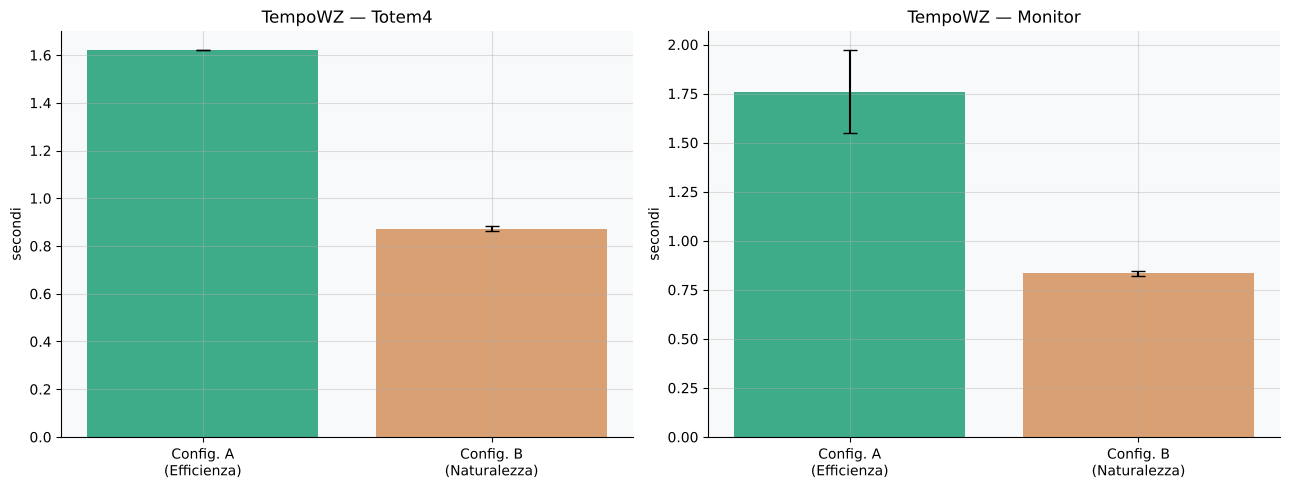

In [57]:
# ============================================================
# 3. Confronto per artefatto (Totem4 vs Monitor) — dove nasce la differenza
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, art, col_wz in [(axes[0], 'Totem4', 'Agent1_Totem4_TempoWZ'), (axes[1], 'Monitor', 'Agent1_Monitor_TempoWZ')]:
    means = [rows_A[col_wz].mean(), rows_B[col_wz].mean()]
    stds  = [rows_A[col_wz].std(),  rows_B[col_wz].std()]
    ax.bar(['Config. A\n(Efficienza)', 'Config. B\n(Naturalezza)'], means, yerr=stds,
           color=['#1D9E75', '#D4915B'], capsize=5, alpha=0.85)
    ax.set_title(f'TempoWZ — {art}')
    ax.set_ylabel('secondi')

plt.tight_layout()
plt.savefig('33_confronto_per_artefatto_AB.png', dpi=150, bbox_inches='tight')
plt.show()

In [58]:
# ============================================================
# 4. Tabella riassuntiva finale
# ============================================================
riassunto = pd.DataFrame({
    'Parametro': ['angularSpeed', 'wzRadius', 'tzRadius', 'TZ_WZ_Ratio', 'warnMult'],
    'Config. A (Efficienza)': [150, 5, 1.25, '1/4', 0.65],
    'Config. B (Naturalezza)': [90, 4, 2.00, '2/4', 0.50],
})
display(riassunto)
print("\n\n\nMetriche riassuntive:")
display(confronto_df.round(4))

,Parametro,Config. A (Efficienza),Config. B (Naturalezza)
0,angularSpeed,150,90
1,wzRadius,5,4
2,tzRadius,1.25,2.0
3,TZ_WZ_Ratio,1/4,2/4
4,warnMult,0.65,0.5





Metriche riassuntive:


,metrica,media_A,media_B,p_value
0,Tempo totale scena,28.6667,27.9333,0.2000
1,Tempo in WZ,3.3800,1.7067,0.0765
2,Tempo in TZ,4.8000,6.5800,0.1000
3,Tempo WZ per metro di gap (naturalezza),0.4507,0.4267,0.3758


## 40. Bootstrap (e perché va interpretato con cautela qui)

Tentativo di rafforzare l'evidenza del confronto A vs B con un bootstrap sulle 3 repliche disponibili. **Attenzione**: con n=3, il ricampionamento con reinserimento produce solo poche combinazioni uniche di medie, generando intervalli di confidenza artificialmente stretti — infatti i risultati qui sotto risultano in contraddizione con il Mann-Whitney della Sez. 39 (che è lo strumento corretto per campioni così piccoli). Cella mantenuta a scopo didattico/di trasparenza sul processo, non come evidenza valida.

In [59]:
# ATTENZIONE METODOLOGICA: con n=3 il bootstrap e' inaffidabile (troppo poche
# combinazioni uniche possibili). Il Mann-Whitney (Sez. 39) resta il test corretto.
# Cella mantenuta per trasparenza sul processo di analisi, non come evidenza valida.
# ============================================================
# Bootstrap: quanto sono affidabili le medie con solo n=3?
# ============================================================
np.random.seed(42)
n_boot = 5000

for col, label in metriche.items():
    a, b = rows_A[col].dropna().values, rows_B[col].dropna().values
    diffs = []
    for _ in range(n_boot):
        boot_a = np.random.choice(a, size=len(a), replace=True).mean()
        boot_b = np.random.choice(b, size=len(b), replace=True).mean()
        diffs.append(boot_a - boot_b)
    diffs = np.array(diffs)
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    print(f"{label:38s} diff medio A-B: {diffs.mean():+.3f}  IC 95%: [{ci_low:+.3f}, {ci_high:+.3f}]")

Tempo totale scena                     diff medio A-B: +0.731  IC 95%: [+0.093, +1.293]


Tempo in WZ                            diff medio A-B: +1.671  IC 95%: [+1.473, +1.893]


Tempo in TZ                            diff medio A-B: -1.780  IC 95%: [-1.907, -1.653]


Tempo WZ per metro di gap (naturalezza) diff medio A-B: +0.024  IC 95%: [-0.003, +0.053]


## 41. Confronto robusto: sovrapposizione tra le top-8 e gruppi esclusivi

Il confronto A vs B con n=3 ha potenza limitata. Aumentiamo la numerosità usando l'intero gruppo delle top-8 configurazioni di ciascuna pipeline (già risultate statisticamente equivalenti al loro interno, Sez. 30 e Sez. 38), verificando prima se i due gruppi si sovrappongono.

In [60]:
# Ricostruisce le top-8 di ciascuna pipeline direttamente da stage3, e le usa
# per un confronto A vs B con numerosita' maggiore (n~10 invece di n=3).
# ============================================================
# Aggiunge 'combo' a stage3 (serve per identificare le righe)
# ============================================================
stage3['combo'] = (stage3['angularSpeed'].astype(str) + '_' + stage3['wzRadius'].astype(str) + '_' +
                    stage3['tzRadius'].astype(str) + '_' + stage3['warnMult'].astype(str) + '_' +
                    stage3['posObiettivo'])

# ============================================================
# Ricostruisci le top-8 per ciascuna analisi (Efficienza = TempoTot,
# Naturalezza = TempoWZ_per_gap), usando stage3 già filtrato dai passaggi precedenti
# ============================================================
top8_eff = (stage3.groupby('combo')['Agent1_TempoTot'].mean()
            .sort_values().head(8).index.tolist())

top8_nat = (stage3.groupby('combo')['TempoWZ_per_gap'].mean()
            .sort_values().head(8).index.tolist())

rows_A_esteso = stage3[stage3['combo'].isin(top8_eff)]
rows_B_esteso = stage3[stage3['combo'].isin(top8_nat)]

print(f"n esteso A (Efficienza): {len(rows_A_esteso)}")
print(f"n esteso B (Naturalezza): {len(rows_B_esteso)}\n")

# ============================================================
# Rilancia Mann-Whitney sui gruppi estesi (n maggiore, test più affidabile)
# ============================================================
for col, label in metriche.items():
    a, b = rows_A_esteso[col].dropna(), rows_B_esteso[col].dropna()
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    esito = "differenza NON significativa" if p >= 0.05 else ("A significativamente migliore" if a.mean() < b.mean() else "B significativamente migliore")
    print(f"{label:38s} {a.mean():10.3f} {b.mean():10.3f} {p:10.4f} {esito:>25s}")

n esteso A (Efficienza): 24
n esteso B (Naturalezza): 24

Tempo totale scena                         30.005     32.392     0.0047 A significativamente migliore
Tempo in WZ                                 1.790      2.064     0.0056 A significativamente migliore
Tempo in TZ                                 5.961      6.869     0.0088 A significativamente migliore
Tempo WZ per metro di gap (naturalezza)      0.449      0.434     0.2700 differenza NON significativa


In [61]:
overlap = set(top8_eff) & set(top8_nat)
print(f"Combinazioni in comune tra le due top-8: {len(overlap)}")
print(overlap)

Combinazioni in comune tra le due top-8: 2
{'90_4_2.0_0.5_Dentro WZ', '150_4_1.0_0.95_Dentro WZ'}


### 💬 Lettura
2 configurazioni su 8 sono condivise tra le due top-8, entrambe con wzRadius=4m: efficienza e naturalezza non sono in forte conflitto, esiste un nucleo di configurazioni valide per entrambi i criteri. Le config. A e B sono i casi limite di ciascuna classifica, non due popolazioni nettamente separate. Per un confronto statistico pulito, isoliamo le combinazioni esclusive di ciascun gruppo:

In [62]:
# Confronto sui soli sottoinsiemi ESCLUSIVI (senza sovrapposizione), per avere
# due popolazioni statisticamente indipendenti e un test piu' potente (n=10/11).
# ============================================================
# Confronto pulito: solo le combinazioni ESCLUSIVE di ciascun gruppo
# (rimuove la sovrapposizione, così il test confronta due popolazioni indipendenti)
# ============================================================
solo_eff = set(top8_eff) - set(top8_nat)
solo_nat = set(top8_nat) - set(top8_eff)

print(f"Esclusive di Efficienza: {solo_eff}")
print(f"Esclusive di Naturalezza: {solo_nat}\n")

rows_A_puro = stage3[stage3['combo'].isin(solo_eff)]
rows_B_puro = stage3[stage3['combo'].isin(solo_nat)]

print(f"n puro A: {len(rows_A_puro)}, n puro B: {len(rows_B_puro)}\n")

for col, label in metriche.items():
    a, b = rows_A_puro[col].dropna(), rows_B_puro[col].dropna()
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    esito = "differenza NON significativa" if p >= 0.05 else ("A significativamente migliore" if a.mean() < b.mean() else "B significativamente migliore")
    print(f"{label:38s} {a.mean():10.3f} {b.mean():10.3f} {p:10.4f} {esito:>25s}")

Esclusive di Efficienza: {'150_3_1.5_0.95_Dentro WZ', '150_4_1.0_0.5_Dentro WZ', '180_3_1.5_0.8_Dentro WZ', '120_3_1.5_0.95_Dentro WZ', '90_4_2.0_0.8_Dentro WZ', '120_3_1.5_0.65_Dentro WZ'}
Esclusive di Naturalezza: {'150_4_1.0_0.8_Dentro WZ', '90_4_2.0_0.95_Dentro WZ', '150_4_2.0_0.5_Dentro WZ', '120_4_2.0_0.65_Dentro WZ', '150_4_2.0_0.8_Dentro WZ', '180_4_1.0_0.95_Dentro WZ'}

n puro A: 18, n puro B: 18

Tempo totale scena                         30.359     33.542     0.0008 A significativamente migliore
Tempo in WZ                                 1.674      2.040     0.0025 A significativamente migliore
Tempo in TZ                                 5.731      6.942     0.0022 A significativamente migliore
Tempo WZ per metro di gap (naturalezza)      0.456      0.437     0.1195 differenza NON significativa


### 💬 Lettura
Con numerosità maggiore e senza sovrapposizione (n=18 per gruppo), il gruppo Efficienza risulta significativamente migliore su TempoTot (p<0.001), ma anche su TempoWZ (p=0.003) e TempoTZ (p=0.002); sulla naturalezza per-gap non c'è differenza significativa (p=0.12). Con il criterio di affidabilità, quindi, il trade-off osservato con il criterio meno severo (dove TempoWZ favoriva il gruppo Naturalezza) non si conferma.

## 42. Conclusioni finali aggiornate

**Perché due configurazioni, non una.** L'analisi iniziale (Sez. 26-30), guidata solo da TempoTot, aveva selezionato `wzRadius=5m, rapporto TZ/WZ=1/4`. Un controllo di coerenza visiva (il raggio sembrava sproporzionato per l'artefatto Totem4) ha portato a scoprire un confound: il tempo locale grezzo è spiegato per il 78% dal solo gap geometrico (Sez. 37), non dal comportamento dell'agente. Correggendo per questo confound (Sez. 38) e applicando una gerarchia di criteri "naturalezza prima, efficienza poi", emerge una seconda configurazione, diversa dalla prima.

**Le due configurazioni:**

| Parametro | Config. A — Efficienza (TempoTot) | Config. B — Naturalezza (corretta per gap) |
|---|---|---|
| angularSpeed | 150°/s | 90°/s |
| wzRadius | 5 m | 4 m |
| tzRadius (rapporto) | 1.25 m (1/4) | 2 m (2/4) |
| warnMult | 0.65 | 0.50 |
| posObiettivo | Dentro WZ | Dentro WZ |

**Il trade-off non è confermato.** Con il criterio meno severo usato nella prima versione dell'analisi, il confronto tra i gruppi esclusivi delle due top-8 (Sez. 41) mostrava Efficienza più rapida in tempo totale e Naturalezza più efficiente nella fase di avvicinamento. Con il criterio di affidabilità (tre ripetizioni valide su tre) il gruppo Efficienza è migliore anche sul tempo in WZ, e la naturalezza per-gap non mostra differenze significative. Con solo n=3 repliche per configurazione singola nessuna differenza tra A e B è comunque dimostrabile (Sez. 39).

**2 configurazioni su 8 sono condivise** tra le top-8 delle due pipeline (entrambe con wzRadius=4m).

**Limite dichiarato**: l'intero ranking si basa su un disegno sperimentale con solo 3 repliche per combinazione, che espone a rischio di selection bias (regression to the mean). Si raccomanda, prima di considerare la scelta definitiva, una fase di validazione con 15-20 repliche aggiuntive sulle configurazioni A/B e sulle configurazioni immediatamente successive in classifica (vedi *Doppia_Analisi_Efficienza_vs_Naturalezza.md* per il piano completo), oltre a un confronto qualitativo diretto in Unity e un'analisi della traiettoria dell'agente.